# TP – Apprentissage et Analyse de données : Credit Scoring

**Réalisé par :** ABBAS Yasmina · GHERZOULI Maria Sara · KESRAOUI Sarah

**Partie I – `credit_scoring.csv`**
- Q1 · Chargement et préparation des données
- Q2 · Apprentissage et évaluation de 3 modèles (choix du critère)
- Q3 · Normalisation
- Q4 · ACP
- Q5 · Sélection de variables (+ explication SHAP)
- Q6 · Optimisation des hyperparamètres (GridSearchCV)
- Q7 · Pipeline complet
- Q8 · Orchestration automatique (`src/utils.py`)
- Q9 · API FastAPI (`src/api.py`)
- Q10 · Validation croisée et comparaison de 8 algorithmes

**Partie II – `credit.data` (données hétérogènes)**
- Q1 · Variables numériques et normalisation
- Q2 · Toutes les variables (valeurs manquantes, encodage one-hot)

> Le notebook s'exécute **en local** (Jupyter, VS Code) comme sur **Google Colab** :
> la cellule de configuration détecte l'environnement et définit les chemins
> du projet (`data/`, `models/`, `src/`).

## Configuration de l'environnement

Détection local / Colab, chemins du projet, versions des packages et imports communs.

In [1]:
# SETUP INITIAL
# On prépare l'environnement : chemins du projet, packages et imports
import os
import sys
import subprocess
import importlib.util
import warnings
from pathlib import Path

# Masquer les avertissements (convergence, dépréciations...) pour des sorties lisibles
warnings.filterwarnings('ignore')

print("SETUP INITIAL DU PROJET".center(70))

# CHEMINS DU PROJET
# data/      : fichiers de données (credit_scoring.csv, credit.data)
# notebooks/ : ce notebook
# src/       : utils.py (Q8) et api.py (Q9)
# models/    : pipelines sauvegardés (pickle)
print("\n CHEMINS DU PROJET")
print("-" * 70)

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Sur Colab : copier le dossier du projet dans Google Drive (adapter le chemin si besoin)
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/ABBAS_Yasmina_GHERZOULI_Maria_Sara_KESRAOUI_Sarah')
else:
    # En local : on remonte depuis le dossier courant jusqu'à la racine du projet
    PROJECT_DIR = next((d for d in [Path.cwd(), *Path.cwd().parents]
                        if (d / 'data' / 'credit_scoring.csv').exists()), None)

if PROJECT_DIR is None or not (PROJECT_DIR / 'data' / 'credit_scoring.csv').exists():
    raise FileNotFoundError("Dossier du projet introuvable : ouvrez le notebook depuis le projet "
                            "(ou corrigez PROJECT_DIR sur Colab)")

DATA_DIR = PROJECT_DIR / 'data'
MODELS_DIR = PROJECT_DIR / 'models'
SRC_DIR = PROJECT_DIR / 'src'
MODELS_DIR.mkdir(exist_ok=True)

# Rendre src/ importable (utils.py, api.py)
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

print(f"Environnement : {'Google Colab' if IN_COLAB else 'local'}")
print(f"   Projet  : {PROJECT_DIR.name}/")
print(f"   Données : data/")
for f in sorted(DATA_DIR.iterdir()):
    print(f"      - {f.name} ({f.stat().st_size / 1024:.1f} KB)")
print(f"   Code    : src/")
print(f"   Modèles : models/")

# PACKAGES
# En local : pip install -r requirements.txt (voir README.md)
# Sur Colab : on installe seulement les packages absents
print("\n  PACKAGES")
print("-" * 70)

if IN_COLAB:
    manquants = [pkg for pkg in ['shap', 'xgboost', 'fastapi', 'uvicorn']
                 if importlib.util.find_spec(pkg) is None]
    if manquants:
        print(f" Installation : {', '.join(manquants)}")
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *manquants], check=True)

import pandas as pd
import numpy as np
import sklearn
import matplotlib
import shap
import xgboost

version_info = pd.DataFrame({
    'Package': ['pandas', 'numpy', 'scikit-learn', 'matplotlib', 'shap', 'xgboost'],
    'Version': [pd.__version__, np.__version__, sklearn.__version__,
                matplotlib.__version__, shap.__version__, xgboost.__version__]
})
print(version_info.to_string(index=False))

#  IMPORTS DE BASE
print("\n  IMPORTS DE BASE")
print("-" * 70)

import time
import pickle
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, KFold, GridSearchCV
# Preprocessing et préparation des données
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder
from sklearn.decomposition import PCA
# Imports pour les modèles (les algorithmes)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
# Imports pour les métriques (évaluer les modèles)
from sklearn.metrics import (confusion_matrix, roc_curve, auc, accuracy_score,
                              recall_score, precision_score, roc_auc_score, f1_score)

# Configuration numpy (pour l'affichage)
np.set_printoptions(threshold=10000, suppress=True)

print(" Tous les imports effectués")
print("\nImports disponibles :")
print("-Data manipulation : pandas, numpy")
print("-Preprocessing : StandardScaler, PCA, OneHotEncoder")
print("-Models : DecisionTree, KNN, MLP, RandomForest...")
print("-Metrics : confusion_matrix, roc_curve, accuracy_score...")

print("\n" + "="*70)
print(" Environnement prêt !".center(70))
print("="*70)

                       SETUP INITIAL DU PROJET                        

 CHEMINS DU PROJET
----------------------------------------------------------------------
Environnement : local
   Projet  : ABBAS_Yasmina_GHERZOULI_Maria_Sara_KESRAOUI_Sarah/
   Données : data/
      - credit.data (29.5 KB)
      - credit_scoring.csv (285.6 KB)
   Code    : src/
   Modèles : models/

  PACKAGES
----------------------------------------------------------------------


     Package Version
      pandas   3.0.6
       numpy   2.5.3
scikit-learn   1.9.1
  matplotlib  3.11.2
        shap  0.52.0
     xgboost   3.4.1

  IMPORTS DE BASE
----------------------------------------------------------------------
 Tous les imports effectués

Imports disponibles :
-Data manipulation : pandas, numpy
-Preprocessing : StandardScaler, PCA, OneHotEncoder
-Models : DecisionTree, KNN, MLP, RandomForest...
-Metrics : confusion_matrix, roc_curve, accuracy_score...

                         Environnement prêt !                         


## Partie I – Credit scoring (`credit_scoring.csv`)

### Q1. Chargement et préparation des données

Séparation X / y, analyse de la distribution de `Status` et découpage train / test 50/50
(stratifié, `random_state=1`).

In [2]:
# CHARGEMENT ET PRÉPARATION

print("\n" + "-"*70)
print("CHARGEMENT ET PRÉPARATION DES DONNÉES".center(70))
print("-"*70)
# On charge les données et on les prépare afin de les comprendre avant de
# créer des modèles

# Importer CREDIT_SCORING.CSV
print("\n Chargement des données")
print("-" * 70)
#Charge un fichier CSV avec pandas
#df Crée un DataFrame (tableau) avec tous les données
df = pd.read_csv(DATA_DIR / 'credit_scoring.csv', sep=';')
# le f'...' Formatage de texte (f-string) pour inclure les variables
print(f" Dataset chargé : {df.shape}") #→ Donne les dimensions du DataFrame
print(f" • Nombre de lignes : {df.shape[0]}") #Nombre de lignes
print(f" • Nombre de colonnes : {df.shape[1]}") #Nombre de colonnes
print(f" • Colonnes : {df.columns.tolist()}")#Noms de toutes les colonnes

#  CONVERTIR EN NUMPY ARRAY ET SÉPARER X/Y
print("\n  CONVERSION EN NUMPY ARRAY ET SÉPARATION X/Y")
print("-" * 70)

# X = les données d'entrée (les variables caractéristiques)
# y = ce qu'on veut prédire (Status = accepté ou refusé)

# Séparer les features de la target
X = df.drop('Status', axis=1).values #Enlève la colonne 'Status'  # 13 features
                                     #values Convertit le DataFrame en **numpy array**
y = df['Status'].values #Sélectionne uniquement la colonne 'Status' # 1 target

# Afficher les dimensions
print(f" X (features) shape: {X.shape}") #  Dimensions : (4375, 13)
print(f"   • {X.shape[0]} samples (personnes)") #lignes
print(f"   • {X.shape[1]} features (variables caractéristiques)") #colonnes
print(f"\n y (target) shape: {y.shape}")
print(f"   • {y.shape[0]} décisions à prédire")

#  ANALYSER LES PROPRIÉTÉS
# On veut comprendre :
# Combien de données avons-nous ?
# Y a-t-il beaucoup plus de crédits acceptés que refusés ?
print("\n  ANALYSE DES PROPRIÉTÉS DES DONNÉES")
print("-" * 70)

# Taille de l'échantillon
# Créer un tableau récapitulatif
print("\n TAILLE DE L'ÉCHANTILLON :")
data_info = pd.DataFrame({
    'Métrique': [
        'Nombre total de samples',
        'Nombre de features (X)',
        'Nombre de targets (y)',
        'Nombre de colonnes (total)'
    ],
    'Valeur': [
        X.shape[0],
        X.shape[1],
        1,
        df.shape[1]
    ]
})
print(data_info.to_string(index=False))

# Pourcentage positifs/négatifs (Analyser la distribution de Status)
print("\n\n DISTRIBUTION DE LA VARIABLE TARGET (Status) :")
#Compter combien de 0 et de 1 dans y
unique, counts = np.unique(y, return_counts=True)

distribution_data = []
for label, count in zip(unique, counts):
    #Calculer le pourcentage
    pct = (count / len(y)) * 100
    # Donner un nom à chaque classe
    if label == 1:
        class_name = "Positif (1) - Crédit ACCEPTÉ "
    else:
        class_name = "Négatif (0) - Crédit REFUSÉ "
    # Créer une barre visuelle
    distribution_data.append({
        'Classe': class_name,
        'Nombre': count,
        'Pourcentage': f"{pct:.2f}%",
        'Barre': '█' * int(count/100) # Chaque █ = 100 clients
    })

class_dist = pd.DataFrame(distribution_data)
print(class_dist.to_string(index=False))

# Analyse du déséquilibre
# Calculer le ratio (déséquilibre des données)
neg_count = counts[0] if unique[0] == 0 else counts[1]
pos_count = counts[1] if unique[1] == 1 else counts[0]
ratio = pos_count / neg_count

print(f"\n  ANALYSE DU RATIO :")
print(f"   • Positifs / Négatifs = {pos_count} / {neg_count} = {ratio:.2f}")
print(f"   •   Dataset DÉSÉQUILIBRÉ : {ratio:.1f}x plus de cas positifs")

#----------------------------
#  TRAIN/TEST SPLIT (50/50)
#----------------------------
# Train = données pour entraîner le modèle (apprendre)
# Test = données pour tester le modèle (vérifier s'il a bien appris)
# 50/50 = moitié pour l'entraînement, moitié pour le test

print("\n  DIVISION TRAIN/TEST (50/50, random_state=1)")
print("-" * 70)

# Diviser les données
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=1, stratify=y
    # 50% pour le test # Pour avoir les mêmes résultats à chaque fois
    # Garder la même proportion de 0 et 1 dans train/test
)

# Afficher les statistiques du split
split_info = pd.DataFrame({
    'Set': ['Train', 'Test', 'Total'],
    'Nombre de samples': [
        X_train.shape[0],
        X_test.shape[0],
        len(y)
    ],
    'Pourcentage': [
        f"{(X_train.shape[0]/len(y))*100:.1f}%",
        f"{(X_test.shape[0]/len(y))*100:.1f}%",
        "100%"
    ]
})
print(split_info.to_string(index=False))
# Afficher les formes des tableaux
print(f"\n X_train : {X_train.shape}")
print(f" X_test : {X_test.shape}")
print(f" y_train : {y_train.shape}")
print(f" y_test : {y_test.shape}")

#  AFFICHER UN APERÇU DES DONNÉES
print("\n  APERÇU DES DONNÉES (5 premiers individus de train) :")
print("-" * 70)

# Montrer les 5 premières lignes pour voir à quoi ça ressemble
feature_names = df.drop('Status', axis=1).columns.tolist() # Récupérer les noms des colonnes
preview = pd.DataFrame(
    X_train[:5], # Prendre les 5 premiers individus
    columns=feature_names
)

preview['Status'] = y_train[:5] # Ajouter la cible
print(preview.to_string())

#  RÉSUMÉ FINAL
print("\n" + "-"*70)

# Créer un tableau récapitulatif
summary = pd.DataFrame({
    'Composant': [
        ' Dataset original',
        ' Variables d\'entrée (X)',
        ' Variable cible (y)',
        ' Distribution',
        '  Train/Test split',
        ' État'
    ],
    'Valeur': [
        f"{df.shape[0]} samples × {df.shape[1]} colonnes",
        f"X: {X.shape[0]} samples × {X.shape[1]} features",
        f"y: {y.shape[0]} décisions",
        f"Positifs: {pos_count} ({(pos_count/len(y))*100:.1f}%) | Négatifs: {neg_count} ({(neg_count/len(y))*100:.1f}%)",
        f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}",
        " Prêt pour Sprint 1.2"
    ]
})
print(summary.to_string(index=False))
# Afficher les variables créées (ce qu'on peut utiliser plus tard)
print("\n VARIABLES GLOBALES CRÉÉES :")
print("    X_train, X_test (numpy arrays)")
print("    y_train, y_test (numpy arrays)")
print("    df (DataFrame original)")
print("    X, y (données complètes)")
print("    feature_names (noms des variables)")

print("\n" + "-"*70)


----------------------------------------------------------------------
                CHARGEMENT ET PRÉPARATION DES DONNÉES                 
----------------------------------------------------------------------

 Chargement des données
----------------------------------------------------------------------
 Dataset chargé : (4375, 14)
 • Nombre de lignes : 4375
 • Nombre de colonnes : 14
 • Colonnes : ['Seniority', 'Home', 'Time', 'Age', 'Marital', 'Records', 'Job', 'Expenses', 'Income', 'Assets', 'Debt', 'Amount', 'Price', 'Status']

  CONVERSION EN NUMPY ARRAY ET SÉPARATION X/Y
----------------------------------------------------------------------
 X (features) shape: (4375, 13)
   • 4375 samples (personnes)
   • 13 features (variables caractéristiques)

 y (target) shape: (4375,)
   • 4375 décisions à prédire

  ANALYSE DES PROPRIÉTÉS DES DONNÉES
----------------------------------------------------------------------

 TAILLE DE L'ÉCHANTILLON :
                  Métrique  Valeur
  

### Q2. Apprentissage et évaluation de 3 modèles

**Choix du critère de performance.** La classe positive (`Status = 1`) correspond à un crédit
**accordé / bon payeur**, la classe 0 à un client **défaillant**.

| Erreur | Signification | Conséquence pour la banque |
|---|---|---|
| FP (faux positif) | crédit accordé à un défaillant | **perte d'argent (risque)** |
| FN (faux négatif) | crédit refusé à un bon client | manque à gagner |

- **Precision** = TP / (TP + FP) : parmi les crédits accordés, part de bons payeurs → limite les FP.
- **Recall** = TP / (TP + FN) : part des bons clients qui obtiennent leur crédit → limite les FN.
  Le recall de la classe 1 ne mesure **pas** la détection des défaillants : c'est la
  **spécificité** TN / (TN + FP) qui la mesure.

Un défaillant à qui l'on accorde un crédit coûte plus cher à la banque qu'un bon client refusé :
on retient la **precision**, d'où **Score Final = (Accuracy + Precision) / 2**.
Ce critère unique est utilisé dans tout le notebook, dans `src/utils.py` (Q8), en validation
croisée (Q10) et dans la Partie II. Pour en changer, modifier `CRITERE` ci-dessous puis
ré-exécuter tout le notebook.

In [3]:
# ============================================
# CRITÈRE DE PERFORMANCE (utilisé dans TOUT le notebook)
# ============================================
# 'precision' : limite les crédits accordés à des défaillants (FP)
# 'recall'    : limite les bons clients refusés à tort (FN)
CRITERE = 'precision'

from utils import score_final, make_score_final_scorer

# Scorer sklearn pour GridSearchCV et la validation croisée
scorer_final = make_score_final_scorer(CRITERE)
LABEL_SCORE = f"(Accuracy + {CRITERE.capitalize()}) / 2"

print(f"Critère retenu : {CRITERE}")
print(f"Score Final = {LABEL_SCORE}")

Critère retenu : precision
Score Final = (Accuracy + Precision) / 2



----------------------------------------------------------------------
               APPRENTISSAGE ET ÉVALUATION DE 3 MODÈLES               
----------------------------------------------------------------------

 CRÉATION DU DICTIONNAIRE D'ALGORITHMES
----------------------------------------------------------------------
 Algorithmes créés :
   • CART (Decision Tree)
   • KNN (k=5)
   • MLP (40,20)

  CRÉATION DE LA FONCTION D'ÉVALUATION
----------------------------------------------------------------------
 Fonction evaluate_model créée !

  CRÉATION DE LA FONCTION run_classifiers_train_test
----------------------------------------------------------------------
 Fonction run_classifiers_train_test créée !


  EXÉCUTION DE LA FONCTION
----------------------------------------------------------------------


                ENTRAÎNEMENT ET ÉVALUATION DES MODÈLES                


 ENTRAÎNEMENT : CART (Decision Tree)
    Entraînement sur 2187 samples...
    Modèle entraîné


          

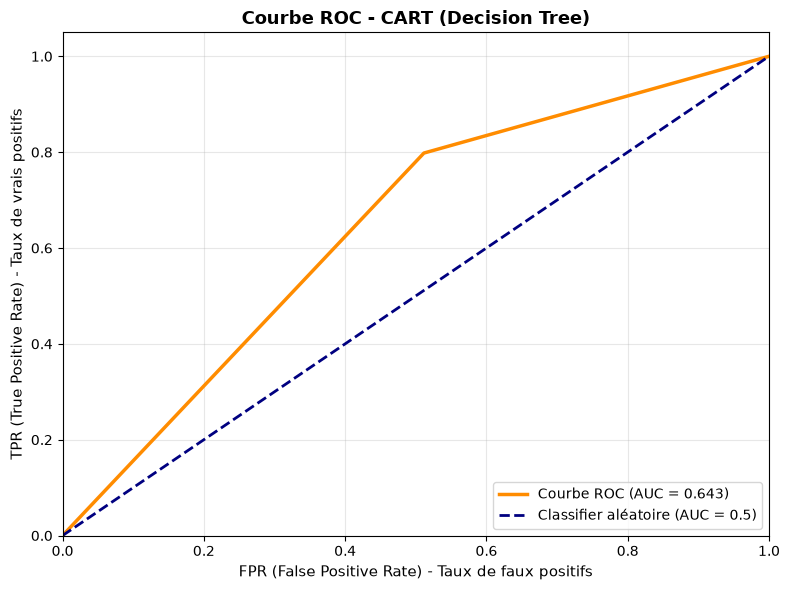

   • AUC-ROC : 0.6433
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7121      71.21%        % total de prédictions correctes
Recall (Sensibilité) 0.7981      79.81%              % de bons clients acceptés
           Precision 0.8022      80.22% % de crédits accordés à de bons clients
         Spécificité 0.4885      48.85%     % de défaillants détectés (refusés)
            F1-Score 0.8001           -              Équilibre Recall/Precision
             AUC-ROC 0.6433           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7121 + 0.8022) / 2
   Résultat: 0.7571

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

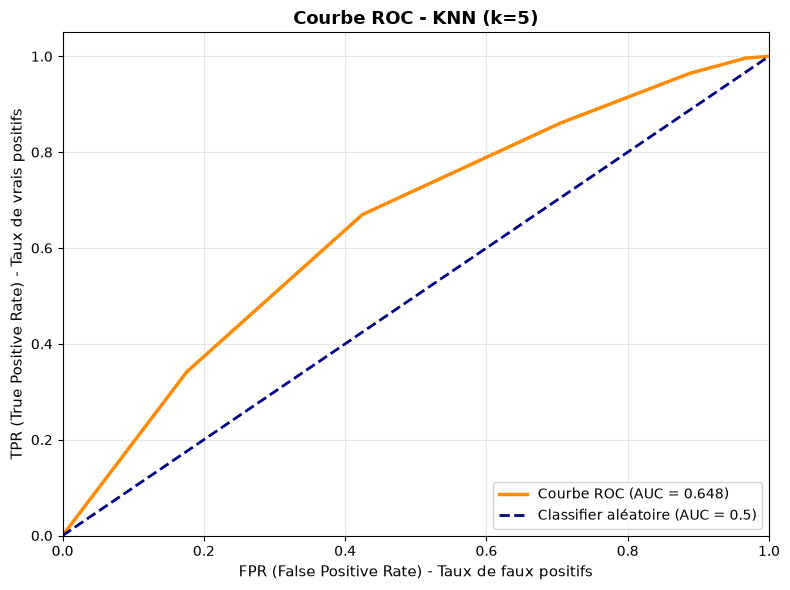

   • AUC-ROC : 0.6478
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7034      70.34%        % total de prédictions correctes
Recall (Sensibilité) 0.8601      86.01%              % de bons clients acceptés
           Precision 0.7605      76.05% % de crédits accordés à de bons clients
         Spécificité 0.2961      29.61%     % de défaillants détectés (refusés)
            F1-Score 0.8072           -              Équilibre Recall/Precision
             AUC-ROC 0.6478           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7034 + 0.7605) / 2
   Résultat: 0.7319

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

    Modèle entraîné


                  ÉVALUATION DÉTAILLÉE - MLP (40,20)                  

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                  59                 549
Réel Positif (1)                  55                1525

   Interprétation :
   • TN (Vrais Négatifs)  : 59 → Crédit refusé correctement
   • FP (Faux Positifs)   : 549 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 55 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1525 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


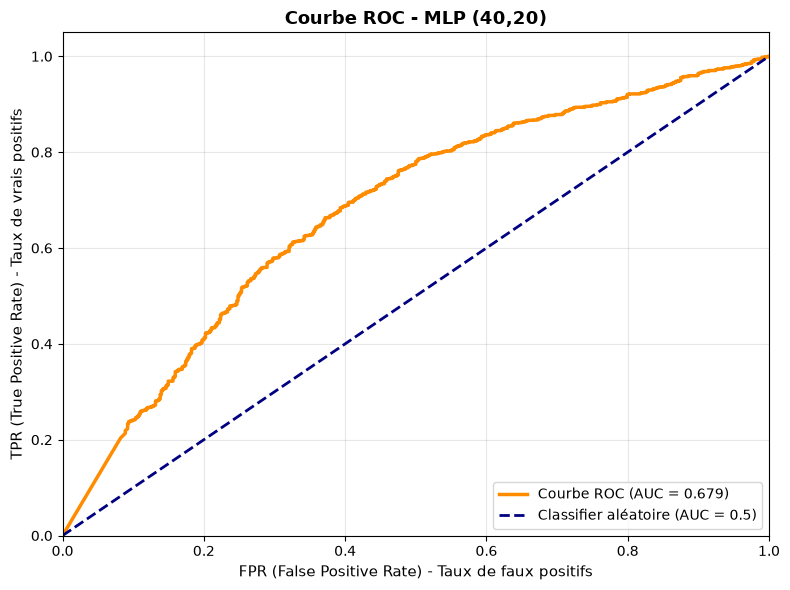

   • AUC-ROC : 0.6791
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7239      72.39%        % total de prédictions correctes
Recall (Sensibilité) 0.9652      96.52%              % de bons clients acceptés
           Precision 0.7353      73.53% % de crédits accordés à de bons clients
         Spécificité 0.0970       9.70%     % de défaillants détectés (refusés)
            F1-Score 0.8347           -              Équilibre Recall/Precision
             AUC-ROC 0.6791           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7239 + 0.7353) / 2
   Résultat: 0.7296

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

In [4]:
# APPRENTISSAGE ET ÉVALUATION
# On crée 3 modèles et on les compare pour trouver le meilleur modèle
# avec matrices de confusion et courbes ROC

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    confusion_matrix, roc_curve, auc, accuracy_score,
    recall_score, precision_score, roc_auc_score, f1_score
)

print("\n" + "-"*70)
print("APPRENTISSAGE ET ÉVALUATION DE 3 MODÈLES".center(70))
print("-"*70)

# ÉTAPE 1 : CRÉER UN DICTIONNAIRE D'ALGORITHMES
# On va tester 3 algorithmes différents
# Un dictionnaire est une structure pour stocker les modèles avec leurs noms

print("\n CRÉATION DU DICTIONNAIRE D'ALGORITHMES")
print("-" * 70)
# Créer 3 modèles différents
clfs_dict = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    # CART = Classification And Regression Tree (Arbre de décision)
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    # KNN = K-Nearest Neighbors (k plus proches voisins, avec k=5)
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20),
                                  random_state=1, max_iter=1000)
    # MLP = Multi-Layer Perceptron (réseau de neurones)
    # hidden_layer_sizes=(40, 20) = 2 couches cachées (40 et 20 neurones)
}

# Afficher les modèles créés
print(" Algorithmes créés :")
for name in clfs_dict.keys():
    print(f"   • {name}")

# ============================================
# ÉTAPE 2 : CRÉER LA FONCTION D'ÉVALUATION
# Cette fonction va afficher TOUT ce qui est demandé par le TP
# Elle va analyser la performance d'un modèle
# Elle va afficher : matrice de confusion, courbe ROC, métriques

print("\n  CRÉATION DE LA FONCTION D'ÉVALUATION")
print("-" * 70)

def evaluate_model(clf, X_test, y_test, clf_name="Modèle"):
    """
    FONCTION D'ÉVALUATION - Affiche TOUS les résultats

    AFFICHE :
    • La matrice de confusion
    • La courbe ROC avec l'AUC
    • Les métriques : Accuracy, Recall, Precision
    • Le score final = (Accuracy + critère) / 2, avec critère = CRITERE

    RETOURNE :
    • score_final et tous les indicateurs
    """

    # ════════════════════════════════════════════
    # 1. FAIRE LES PRÉDICTIONS
    # predict() = dire si crédit accepté (1) ou refusé (0)
    # predict_proba() = donner la probabilité
    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)[:, 1]

    # ════════════════════════════════════════════
    # 2. AFFICHER LA MATRICE DE CONFUSION
    # Un tableau qui montre les erreurs du modèle
    # - TP (True Positive) = prédire 1 quand c'est 1
    # - FP (False Positive) = prédire 1 quand c'est 0
    # - FN (False Negative) = prédire 0 quand c'est 1
    # - TN (True Negative) = prédire 0 quand c'est 0
    # Afin de :
    # - Voir le nombre de TP, FP, TN, FN
    # - Comprendre où le modèle se trompe

    print(f"\n\n{'='*70}")
    print(f"ÉVALUATION DÉTAILLÉE - {clf_name}".center(70))
    print(f"{'='*70}")

    print(f"\n 1. MATRICE DE CONFUSION")
    print("-" * 70)

    # Calculer la matrice
    cm = confusion_matrix(y_test, y_pred) # Créer la matrice
    tn, fp, fn, tp = cm.ravel() # Extraire les 4 valeurs

    # Afficher la matrice en tableau
    cm_df = pd.DataFrame(
        cm,
        index=['Réel Négatif (0)', 'Réel Positif (1)'],
        columns=['Prédit Négatif (0)', 'Prédit Positif (1)']
    )
    print(cm_df.to_string())

    # Expliquer chaque cellule
    print(f"\n   Interprétation :")
    print(f"   • TN (Vrais Négatifs)  : {tn} → Crédit refusé correctement")
    print(f"   • FP (Faux Positifs)   : {fp} → Crédit accepté à tort (RISQUE)")
    print(f"   • FN (Faux Négatifs)   : {fn} → Crédit refusé à tort (PERTE)")
    print(f"   • TP (Vrais Positifs)  : {tp} → Crédit accepté correctement")

    # ════════════════════════════════════════════
    # 3. AFFICHER LA COURBE ROC ET L'AUC
    # Un graphique qui montre la performance du modèle
    # - Visualiser la capacité de discrimination du modèle
    # - Voir le trade-off entre TPR et FPR
    # AUC = Area Under Curve (aire sous la courbe)
    # - AUC = 1.0 (parfait) à 0.5 (aléatoire)

    print(f"\n\n 2. COURBE ROC ET AUC")
    print("-" * 70)

    # Calculer les coordonnées de la courbe ROC
    fpr, tpr, thresholds = roc_curve(y_test, y_proba) # Calculer les points
    roc_auc = auc(fpr, tpr) # Calculer l'aire sous la courbe

    # Créer la figure
    fig, ax = plt.subplots(figsize=(8, 6))

    # Tracer la courbe ROC
    ax.plot(fpr, tpr, color='darkorange', lw=2.5,
            label=f'Courbe ROC (AUC = {roc_auc:.3f})')

    # Tracer la ligne de référence (classifier aléatoire)
    ax.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--',
            label='Classifier aléatoire (AUC = 0.5)')

    # Décorer le graphique
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel('FPR (False Positive Rate) - Taux de faux positifs', fontsize=11)
    ax.set_ylabel('TPR (True Positive Rate) - Taux de vrais positifs', fontsize=11)
    ax.set_title(f'Courbe ROC - {clf_name}', fontsize=13, fontweight='bold')
    ax.legend(loc="lower right", fontsize=10)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    # Afficher le score AUC
    print(f"   • AUC-ROC : {roc_auc:.4f}")
    print(f"   • Interprétation : ", end="")
    if roc_auc >= 0.9:
        print("Excellent discrimination ")
    elif roc_auc >= 0.8:
        print("Bonne discrimination ")
    elif roc_auc >= 0.7:
        print("Discrimination acceptable")
    elif roc_auc >= 0.6:
        print("Discrimination faible")
    else:
        print("Très faible discrimination ")

    # ════════════════════════════════════════════
    # 4. CALCULER LES MÉTRIQUES
    # Accuracy = % de prédictions correctes
    # Recall = % de bons clients (classe 1) correctement acceptés
    # Precision = % de crédits accordés qui vont à de bons clients
    # Spécificité = % de défaillants (classe 0) détectés, donc refusés
    # F1-Score = moyenne harmonique entre Recall et Precision

    print(f"\n\n 3. MÉTRIQUES D'ÉVALUATION")
    print("-" * 70)

    accuracy = accuracy_score(y_test, y_pred) # % correct
    recall = recall_score(y_test, y_pred, zero_division=0) # % bons clients acceptés
    precision = precision_score(y_test, y_pred, zero_division=0) # % crédits accordés à de bons clients
    specificity = tn / (tn + fp) # % défaillants détectés
    f1 = f1_score(y_test, y_pred, zero_division=0) # Moyenne harmonique

    # Créer un tableau des métriques
    metrics_data = {
        'Métrique': ['Accuracy', 'Recall (Sensibilité)', 'Precision',
                     'Spécificité', 'F1-Score', 'AUC-ROC'],
        'Valeur': [f"{accuracy:.4f}", f"{recall:.4f}", f"{precision:.4f}",
                   f"{specificity:.4f}", f"{f1:.4f}", f"{roc_auc:.4f}"],
        'Pourcentage': [f"{accuracy*100:.2f}%", f"{recall*100:.2f}%",
                        f"{precision*100:.2f}%", f"{specificity*100:.2f}%", "-", "-"],
        'Signification': [
            "% total de prédictions correctes",
            "% de bons clients acceptés",
            "% de crédits accordés à de bons clients",
            "% de défaillants détectés (refusés)",
            "Équilibre Recall/Precision",
            "Capacité à discriminer les classes"
        ]
    }

    metrics_df = pd.DataFrame(metrics_data)
    print(metrics_df.to_string(index=False))

    # ════════════════════════════════════════════
    # 5. CALCULER LE SCORE FINAL
    # ════════════════════════════════════════════
    # Critère choisi au début de la Q2 (CRITERE)
    # Precision : limite les crédits accordés à des défaillants (FP = perte d'argent)

    print(f"\n\n 4. SCORE FINAL")
    print("-" * 70)

    best_criterion = precision if CRITERE == 'precision' else recall
    best_criterion_name = CRITERE.capitalize()
    # Calcul du score final
    score = score_final(y_test, y_pred, CRITERE)

    print(f"   Formule : Score Final = (Accuracy + {best_criterion_name}) / 2")
    print(f"   Calcul  : ({accuracy:.4f} + {best_criterion:.4f}) / 2")
    print(f"   Résultat: {score:.4f}")
    if CRITERE == 'precision':
        print(f"\n   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)")
        print(f"   coûte plus cher à la banque que refuser un bon client (FN).")
    else:
        print(f"\n   Pourquoi le Recall ? On limite les bons clients refusés à tort (FN).")

    # ════════════════════════════════════════════
    # RETOURNER TOUS LES RÉSULTATS
    # Retourner un dictionnaire avec tous les résultats

    return {
        'accuracy': accuracy,
        'recall': recall,
        'precision': precision,
        'specificity': specificity,
        'f1': f1,
        'auc_roc': roc_auc,
        'score_final': score,
        'confusion_matrix': cm,
        'y_pred': y_pred,
        'y_proba': y_proba,
        'fpr': fpr,
        'tpr': tpr
    }

print(" Fonction evaluate_model créée !")

# ============================================
# ÉTAPE 3 : CRÉER LA FONCTION DE COMPARAISON
# Cette fonction va :
# 1. Entraîner chaque modèle
# 2. Évaluer chaque modèle
# 3. Comparer les résultats
# 4. Retourner le meilleur

print("\n  CRÉATION DE LA FONCTION run_classifiers_train_test")
print("-" * 70)

def run_classifiers_train_test(clfs_dict, X_train, y_train, X_test, y_test):
    """
    FONCTION D'APPRENTISSAGE ET DE TEST

    FAIT :
    • Entraîne chaque algorithme du dictionnaire (chaque modèle sur X_train)
    • Affiche les résultats d'évaluation (matrice, ROC, métriques)
    • Compare les scores obtenus avec un classement du meilleur au moins bon
    • Retourne le meilleur modèle
    """
    # Stocker les résultats de chaque modèle
    results_dict = {}
    best_score = -1
    best_model_name = None
    best_model = None

    print("\n\n" + "="*70)
    print("ENTRAÎNEMENT ET ÉVALUATION DES MODÈLES".center(70))
    print("="*70)

    # ════════════════════════════════════════════
    # BOUCLE : POUR CHAQUE MODÈLE
    # for (clf_name, clf) in clfs_dict.items() = parcourir le dictionnaire

    for clf_name, clf in clfs_dict.items():

        print(f"\n\n ENTRAÎNEMENT : {clf_name}")
        print("=" * 70)

        # Entraîner
        print(f"    Entraînement sur {X_train.shape[0]} samples...")
        # fit() = apprendre à partir des données d'entraînement
        clf.fit(X_train, y_train)
        print(f"    Modèle entraîné")

        # Évaluer (affiche TOUT)
        # Appeler la fonction evaluate_model pour afficher tous les résultats
        eval_results = evaluate_model(clf, X_test, y_test, clf_name)

        # Stocker
        results_dict[clf_name] = eval_results

        # Tracker le meilleur
        # Vérifier si ce modèle est meilleur que les précédents
        if eval_results['score_final'] > best_score:
            best_score = eval_results['score_final']
            best_model_name = clf_name
            best_model = clf

    # ════════════════════════════════════════════
    # TABLEAU COMPARATIF

    print("\n\n" + "-"*70)
    print("COMPARAISON DES RÉSULTATS".center(70))
    print("-"*70)

    # Créer les données pour le tableau
    comparison_data = []
    for clf_name, res in results_dict.items():
        comparison_data.append({
            'Modèle': clf_name,
            'Accuracy': f"{res['accuracy']:.4f}",
            'Recall': f"{res['recall']:.4f}",
            'Precision': f"{res['precision']:.4f}",
            'Spécificité': f"{res['specificity']:.4f}",
            'F1-Score': f"{res['f1']:.4f}",
            'AUC-ROC': f"{res['auc_roc']:.4f}",
            'Score Final': f"{res['score_final']:.4f}"
        })

    comparison_df = pd.DataFrame(comparison_data)
        # Afficher le tableau
    print("\n" + comparison_df.to_string(index=False))

    # ════════════════════════════════════════════
    # CLASSEMENT
    # Trier les modèles par score (du meilleur au moins bon)
    print("\n\n" + "-"*70)
    print("CLASSEMENT DES MODÈLES".center(70))

    # Trier par score_final (du plus grand au plus petit)
    sorted_results = sorted(results_dict.items(),
                           key=lambda x: x[1]['score_final'],
                           reverse=True)
    # Afficher le classement
    print("\nClassement (du meilleur au moins bon) :\n")
    for rank, (name, res) in enumerate(sorted_results, 1):
        medal = "🥇" if rank == 1 else "🥈" if rank == 2 else "🥉"
        print(f"   {medal} {rank}. {name}")
        print(f"      Score Final : {res['score_final']:.4f}")
        print(f"      Accuracy    : {res['accuracy']:.4f}")
        print(f"      Recall      : {res['recall']:.4f}")
        print(f"      Precision   : {res['precision']:.4f}")
        print(f"      AUC-ROC     : {res['auc_roc']:.4f}\n")

    # ════════════════════════════════════════════
    # AFFICHER LE MEILLEUR
    # ════════════════════════════════════════════

    print("\n" + "="*70)
    print("MEILLEUR MODÈLE SÉLECTIONNÉ".center(70))
    print("="*70)
    # Afficher le meilleur modèle trouvé
    print(f"\n Modèle choisi : {best_model_name}")
    print(f"   Score Final : {best_score:.4f}")
    print(f"\n   Ce modèle sera utilisé pour les étapes suivantes :")
    print(f"   • Normalisation")
    print(f"   • ACP")
    print(f"   • Sélection de variables")

    # RETOURNER les résultats
    return best_model, best_model_name, results_dict

print(" Fonction run_classifiers_train_test créée !")

# ============================================
# ÉTAPE 4 : TESTER LA FONCTION
# ============================================

# Appeler la fonction pour entraîner et tester tous les modèles
print("\n\n  EXÉCUTION DE LA FONCTION")
print("-" * 70)

best_model, best_model_name, results_raw = run_classifiers_train_test(
    clfs_dict, X_train, y_train, X_test, y_test
)

# ============================================
# ÉTAPE 5 : RÉSUMÉ FINAL
# ============================================

print("\n\n" + "="*70)
print(" Phase TERMINÉ".center(70))
print("-"*70)

print("\n VARIABLES CRÉÉES :")
print("-" * 70)
print(f"best_model : {best_model_name}")
print(f"best_model_name : '{best_model_name}'")
print(f"results_raw : Dictionnaire avec résultats détaillés")
print(f"clfs_dict : Dictionnaire des 3 algorithmes")

print("\nRÉSUMÉ DES RÉSULTATS :")
print("-" * 70)
for name, res in results_raw.items():
    print(f"{name}:")
    print(f"  • Accuracy : {res['accuracy']:.4f}")
    print(f"  • Recall : {res['recall']:.4f}")
    print(f"  • Precision : {res['precision']:.4f}")
    print(f"  • Score Final : {res['score_final']:.4f}")

print("\n PROCHAINE ÉTAPE :")
print("-" * 70)
print("Normalisation des données avec StandardScaler")
print("Tester si normalisation améliore les résultats")

print("\n" + "-"*70 + "\n")

### Q3. Normalisation des variables

Comparaison des 3 modèles sans normalisation, avec `StandardScaler` et avec `MinMaxScaler`
(scalers appris sur le train uniquement).


----------------------------------------------------------------------
                            NORMALISATION                             

1️⃣  RÉSULTATS DE RÉFÉRENCE (SANS NORMALISATION)
----------------------------------------------------------------------
   CART (Decision Tree) : Score Final = 0.7571
   KNN (k=5)            : Score Final = 0.7319
   MLP (40,20)          : Score Final = 0.7296


2️⃣  NORMALISATION AVEC StandardScaler
----------------------------------------------------------------------

 Qu'est-ce que StandardScaler ?
   Formule : X_normalized = (X - moyenne) / écart-type
   Résultat : moyenne = 0, écart-type = 1

 Fit du scaler sur X_train...
 Scaler entraîné

 Transformation de X_train et X_test...
 Données transformées

 Vérification StandardScaler :
   • Moyenne après : -0.000000 (proche de 0 )
   • Écart-type après : 1.000000 (proche de 1 )

   🔄 Réentraînement des modèles...


                ENTRAÎNEMENT ET ÉVALUATION DES MODÈLES                


 ENTR

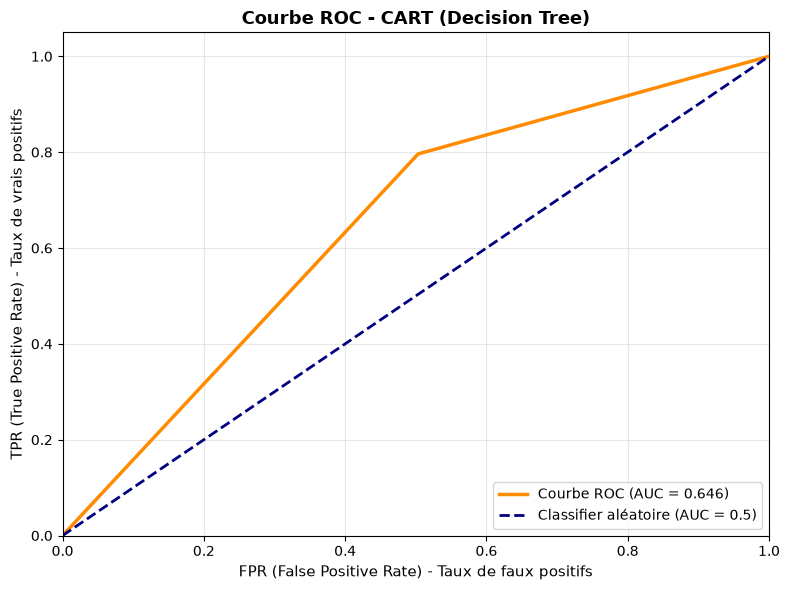

   • AUC-ROC : 0.6465
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7130      71.30%        % total de prédictions correctes
Recall (Sensibilité) 0.7962      79.62%              % de bons clients acceptés
           Precision 0.8043      80.43% % de crédits accordés à de bons clients
         Spécificité 0.4967      49.67%     % de défaillants détectés (refusés)
            F1-Score 0.8003           -              Équilibre Recall/Precision
             AUC-ROC 0.6465           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7130 + 0.8043) / 2
   Résultat: 0.7587

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte



                   ÉVALUATION DÉTAILLÉE - KNN (k=5)                   

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 270                 338
Réel Positif (1)                 212                1368

   Interprétation :
   • TN (Vrais Négatifs)  : 270 → Crédit refusé correctement
   • FP (Faux Positifs)   : 338 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 212 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1368 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


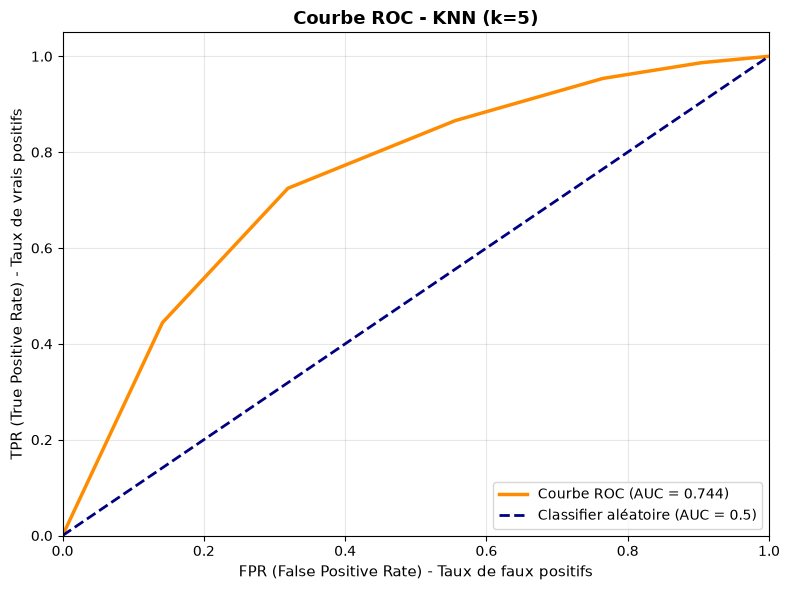

   • AUC-ROC : 0.7440
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7486      74.86%        % total de prédictions correctes
Recall (Sensibilité) 0.8658      86.58%              % de bons clients acceptés
           Precision 0.8019      80.19% % de crédits accordés à de bons clients
         Spécificité 0.4441      44.41%     % de défaillants détectés (refusés)
            F1-Score 0.8326           -              Équilibre Recall/Precision
             AUC-ROC 0.7440           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7486 + 0.8019) / 2
   Résultat: 0.7753

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

    Modèle entraîné


                  ÉVALUATION DÉTAILLÉE - MLP (40,20)                  

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 334                 274
Réel Positif (1)                 297                1283

   Interprétation :
   • TN (Vrais Négatifs)  : 334 → Crédit refusé correctement
   • FP (Faux Positifs)   : 274 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 297 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1283 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


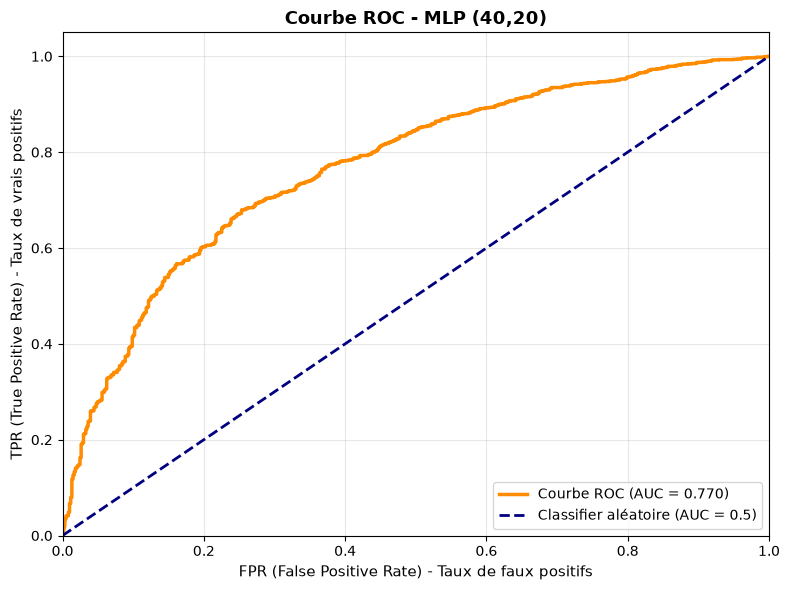

   • AUC-ROC : 0.7697
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7390      73.90%        % total de prédictions correctes
Recall (Sensibilité) 0.8120      81.20%              % de bons clients acceptés
           Precision 0.8240      82.40% % de crédits accordés à de bons clients
         Spécificité 0.5493      54.93%     % de défaillants détectés (refusés)
            F1-Score 0.8180           -              Équilibre Recall/Precision
             AUC-ROC 0.7697           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7390 + 0.8240) / 2
   Résultat: 0.7815

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

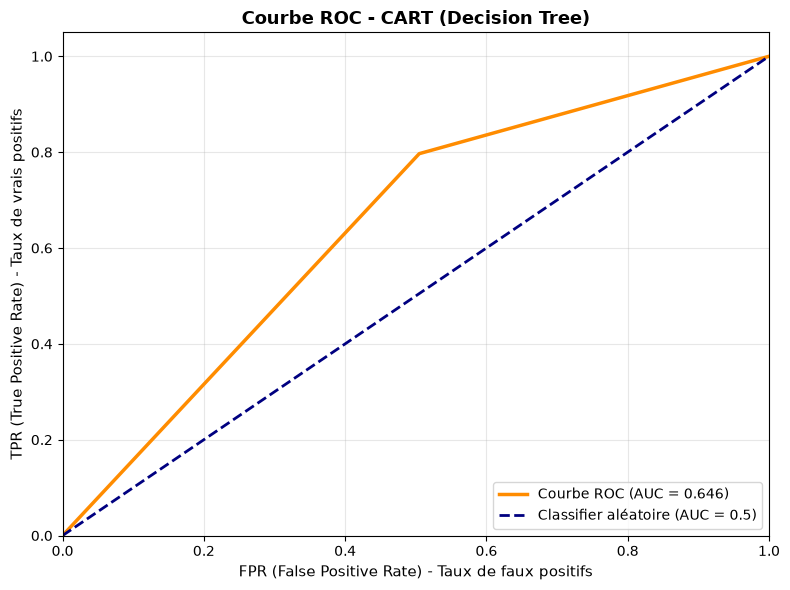

   • AUC-ROC : 0.6460
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7130      71.30%        % total de prédictions correctes
Recall (Sensibilité) 0.7968      79.68%              % de bons clients acceptés
           Precision 0.8040      80.40% % de crédits accordés à de bons clients
         Spécificité 0.4951      49.51%     % de défaillants détectés (refusés)
            F1-Score 0.8004           -              Équilibre Recall/Precision
             AUC-ROC 0.6460           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7130 + 0.8040) / 2
   Résultat: 0.7585

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

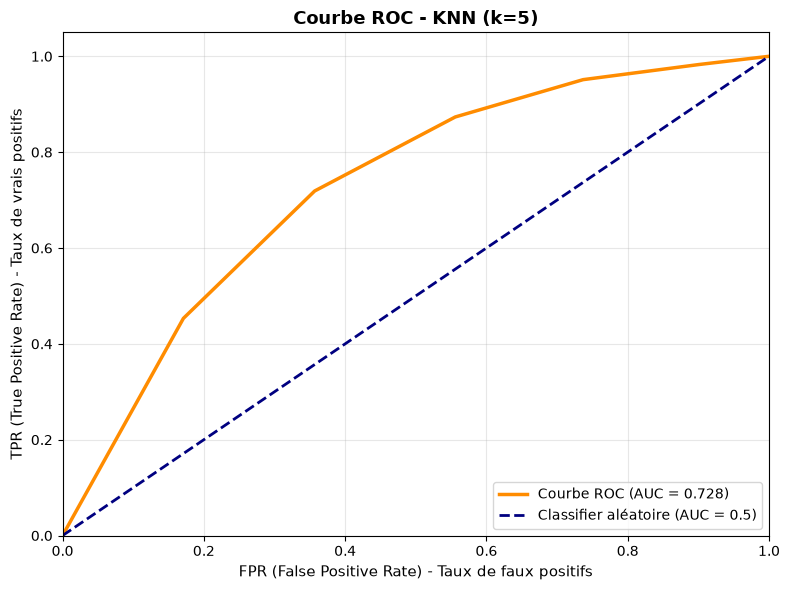

   • AUC-ROC : 0.7281
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7541      75.41%        % total de prédictions correctes
Recall (Sensibilité) 0.8734      87.34%              % de bons clients acceptés
           Precision 0.8033      80.33% % de crédits accordés à de bons clients
         Spécificité 0.4441      44.41%     % de défaillants détectés (refusés)
            F1-Score 0.8369           -              Équilibre Recall/Precision
             AUC-ROC 0.7281           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7541 + 0.8033) / 2
   Résultat: 0.7787

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

    Modèle entraîné


                  ÉVALUATION DÉTAILLÉE - MLP (40,20)                  

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 328                 280
Réel Positif (1)                 178                1402

   Interprétation :
   • TN (Vrais Négatifs)  : 328 → Crédit refusé correctement
   • FP (Faux Positifs)   : 280 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 178 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1402 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


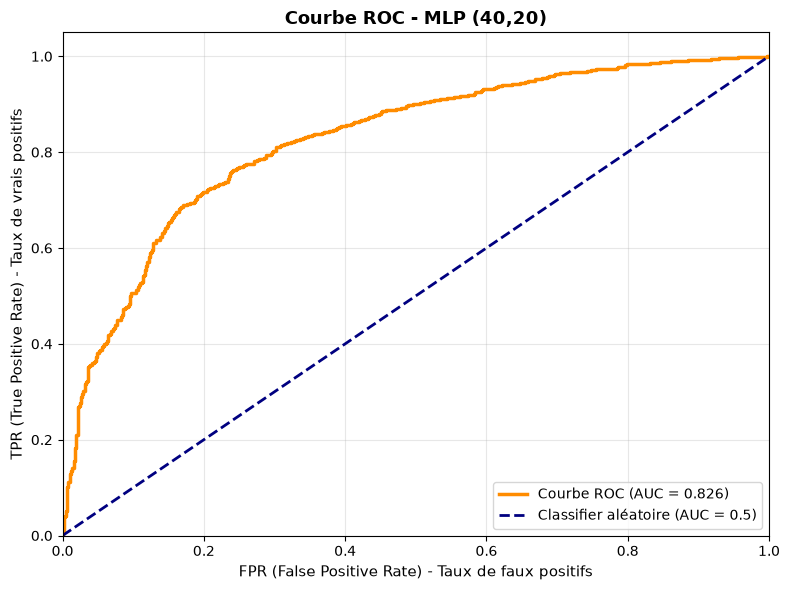

   • AUC-ROC : 0.8257
   • Interprétation : Bonne discrimination 


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7907      79.07%        % total de prédictions correctes
Recall (Sensibilité) 0.8873      88.73%              % de bons clients acceptés
           Precision 0.8335      83.35% % de crédits accordés à de bons clients
         Spécificité 0.5395      53.95%     % de défaillants détectés (refusés)
            F1-Score 0.8596           -              Équilibre Recall/Precision
             AUC-ROC 0.8257           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7907 + 0.8335) / 2
   Résultat: 0.8121

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

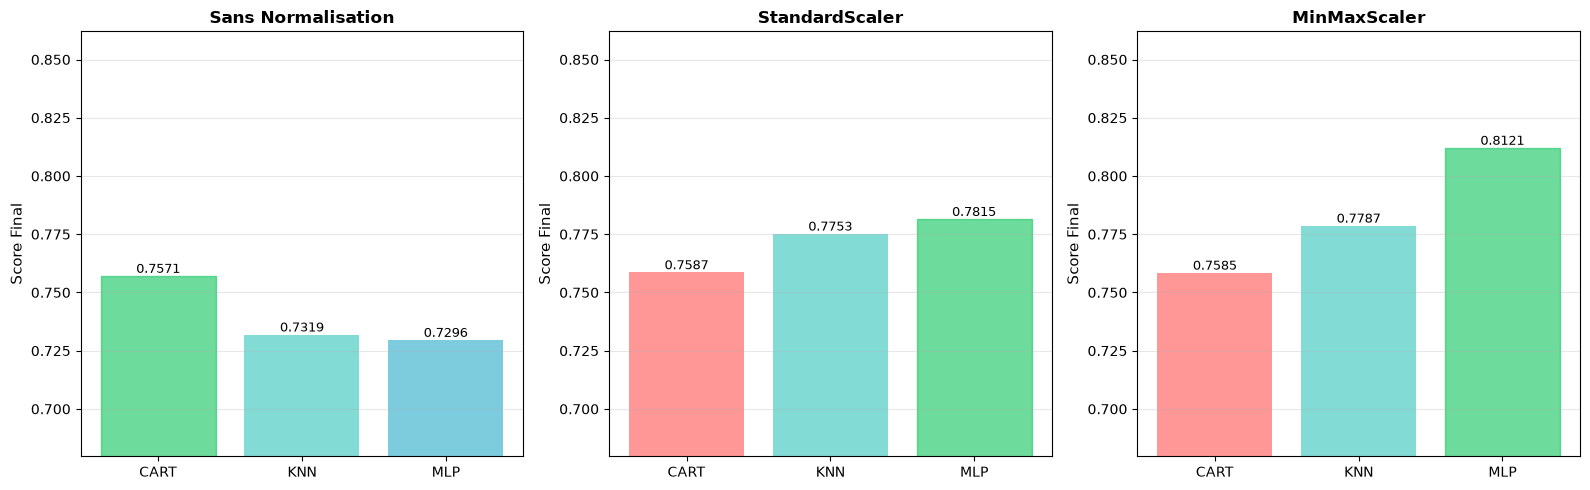

  Graphique affichée


6️⃣  ANALYSE DÉTAILLÉE
----------------------------------------------------------------------

 AMÉLIORATION PAR RAPPORT AU SANS NORMALISATION :

   CART (Decision Tree):
      Baseline           : 0.7571
      StandardScaler     : 0.7587 (+0.20%)
      MinMaxScaler       : 0.7585 (+0.18%)
 Meilleur : StandardScaler

   KNN (k=5):
      Baseline           : 0.7319
      StandardScaler     : 0.7753 (+5.92%)
      MinMaxScaler       : 0.7787 (+6.39%)
 Meilleur : MinMaxScaler

   MLP (40,20):
      Baseline           : 0.7296
      StandardScaler     : 0.7815 (+7.11%)
      MinMaxScaler       : 0.8121 (+11.30%)
 Meilleur : MinMaxScaler


7️⃣  RÉSUMÉ FINAL
----------------------------------------------------------------------

 MEILLEURE CONFIGURATION GLOBALE :
   Config : MLP (40,20) + MinMaxScaler
   Score Final : 0.8121

 DÉCISION POUR LES PROCHAINES ÉTAPES :
   - Utiliser MinMaxScaler
   → Meilleur modèle : MLP (40,20)


------------------------------------------

In [5]:
# ============================================
# NORMALISATION (VERSION COMPLÈTE)
# On teste si normaliser les données améliore les résultats
# Certains algorithmes préfèrent les données normalisées
# Avec StandardScaler ET MinMaxScaler

from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt

print("\n" + "-"*70)
print("NORMALISATION".center(70))

# ÉTAPE 1 : RÉSULTATS SANS NORMALISATION (rappel)
# On compare avec les résultats sans normalisation
print("\n1️⃣  RÉSULTATS DE RÉFÉRENCE (SANS NORMALISATION)")
print("-" * 70)

# Extraire les scores
baseline_results = {}
for clf_name, res in results_raw.items():
    baseline_results[clf_name] = res['score_final']
    print(f"   {clf_name:20s} : Score Final = {res['score_final']:.4f}")

# ============================================
# ÉTAPE 2 : NORMALISATION AVEC StandardScaler
# StandardScaler = centrer et réduire les données

print("\n\n2️⃣  NORMALISATION AVEC StandardScaler")
print("-" * 70)
# Expliquer ce que StandardScaler fait
print("\n Qu'est-ce que StandardScaler ?")
print("   Formule : X_normalized = (X - moyenne) / écart-type")
print("   Résultat : moyenne = 0, écart-type = 1")
#Utilité : Utile pour KNN et MLP qui sont sensibles à l'échelle

# Créer le scaler StandardScaler
scaler_standard = StandardScaler()

# FIT sur X_train UNIQUEMENT
# Pour apprendre les statistiques (moyenne, écart-type) sur l'entraînement
# et les appliquer au test (éviter la fuite de données)
print(f"\n Fit du scaler sur X_train...")
scaler_standard.fit(X_train)# Calculer moyenne et écart-type sur X_train
print(f" Scaler entraîné")

# TRANSFORM X_train et X_test
# Appliquer la normalisation à X_train et X_test
print(f"\n Transformation de X_train et X_test...")
X_train_standard = scaler_standard.transform(X_train)# Normaliser X_train
X_test_standard = scaler_standard.transform(X_test)# Normaliser X_test
print(f" Données transformées")

# Vérification du fonctionnement
# Vérifier que la moyenne est proche de 0 et écart-type proche de 1
print(f"\n Vérification StandardScaler :")
print(f"   • Moyenne après : {X_train_standard.mean():.6f} (proche de 0 )")
print(f"   • Écart-type après : {X_train_standard.std():.6f} (proche de 1 )")

# Réentraîner les modèles
# Créer 3 nouveaux modèles et les entraîner sur les données normalisées
print(f"\n   🔄 Réentraînement des modèles...")

clfs_dict_standard = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20),
                                  random_state=1, max_iter=1000)
}

# Appeler la fonction précédante pour entraîner et évaluer
best_model_standard, best_model_name_standard, results_standard = run_classifiers_train_test(
    clfs_dict_standard, X_train_standard, y_train,
    X_test_standard, y_test
)

# ============================================
# ÉTAPE 3 : NORMALISATION AVEC MinMaxScaler
# MinMaxScaler = mettre tout entre 0 et 1

print("\n\n3️⃣  NORMALISATION AVEC MinMaxScaler")
print("-" * 70)
# Expliquer ce que MinMaxScaler fait
print("\n Qu'est-ce que MinMaxScaler ?")
print("   Formule : X_normalized = (X - min) / (max - min)")
print("   Résultat : toutes les valeurs entre 0 et 1")
#Utilité : Bon pour les réseaux de neurones et KNN

# Créer le scaler MinMaxScaler
scaler_minmax = MinMaxScaler()

# FIT sur X_train UNIQUEMENT
print(f"\n  Fit du scaler sur X_train...")
scaler_minmax.fit(X_train)
print(f"   Scaler entraîné")

# TRANSFORM X_train et X_test
print(f"\n  Transformation de X_train et X_test...")
X_train_minmax = scaler_minmax.transform(X_train)
X_test_minmax = scaler_minmax.transform(X_test)
print(f"   Données transformées")

# Vérifier
# Vérifier que min est proche de 0 et max proche de 1
print(f"\n  Vérification MinMaxScaler :")
print(f"      • Min après : {X_train_minmax.min():.6f} (proche de 0)")
print(f"      • Max après : {X_train_minmax.max():.6f} (proche de 1)")

# Réentraîner les modèles
print(f"\n    Réentraînement des modèles...")

clfs_dict_minmax = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20),
                                  random_state=1, max_iter=1000)
}

# Appeler la fonction précédante pour entraîner et évaluer
best_model_minmax, best_model_name_minmax, results_minmax = run_classifiers_train_test(
    clfs_dict_minmax, X_train_minmax, y_train,
    X_test_minmax, y_test
)

# ============================================
# ÉTAPE 4 : TABLEAU COMPARATIF COMPLET
# Comparer les 3 méthodes : aucune normalisation, StandardScaler, MinMaxScaler

print("\n\n4️⃣  TABLEAU COMPARATIF : SANS / StandardScaler / MinMaxScaler")
print("-" * 70)

# Créer les données pour le tableau
comparison_all = []
for clf_name in results_raw.keys():
    comparison_all.append({
        'Modèle': clf_name,
        'Sans Norm': f"{results_raw[clf_name]['score_final']:.4f}",
        'StandardScaler': f"{results_standard[clf_name]['score_final']:.4f}",
        'MinMaxScaler': f"{results_minmax[clf_name]['score_final']:.4f}",
        'Meilleur': max(
            results_raw[clf_name]['score_final'],
            results_standard[clf_name]['score_final'],
            results_minmax[clf_name]['score_final']
        )
    })

# Afficher le tableau
# Montre le score final de chaque modèle avec chaque normalisation
comparison_all_df = pd.DataFrame(comparison_all)
print("\n" + comparison_all_df.to_string(index=False))

# ============================================
# ÉTAPE 5 : VISUALISATION GRAPHIQUE
# Créer des graphiques pour comparer visuellement
# Comparer les performances graphiquement

print("\n\n5️⃣  VISUALISATION GRAPHIQUE")
print("-" * 70)

# Créer un graphique de comparaison
# 3 sous-graphiques (un pour chaque normalisation)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Les 3 méthodes de normalisation
methods = ['Sans Normalisation', 'StandardScaler', 'MinMaxScaler']
all_results = [results_raw, results_standard, results_minmax]

# Limites de l'axe Y adaptées aux scores obtenus
scores_q3 = [res[m]['score_final'] for res in all_results for m in results_raw]
y_min, y_max = max(0, min(scores_q3) - 0.05), min(1, max(scores_q3) + 0.05)

# Pour chaque méthode
for idx, (ax, method, results) in enumerate(zip(axes, methods, all_results)):
    # Extraire les scores
    scores = [results[clf_name]['score_final'] for clf_name in results_raw.keys()]
    models = [clf_name for clf_name in results_raw.keys()]

    # Créer le graphique (histogramme)
    # Couleurs : rouge pour CART, turquoise pour KNN, bleu pour MLP
    bars = ax.bar(range(len(models)), scores, color=['#FF6B6B', '#4ECDC4', '#45B7D1'], alpha=0.7)

    # Décorer
    # Mettre les noms des modèles sur l'axe X
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(['CART', 'KNN', 'MLP'], fontsize=10)
    ax.set_ylabel('Score Final', fontsize=11)
    ax.set_title(method, fontsize=12, fontweight='bold')
    ax.set_ylim([y_min, y_max])
    ax.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs sur les barres
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=9)

    # Marquer le meilleur
    max_score = max(scores)
    max_idx = scores.index(max_score)
    bars[max_idx].set_color('#2ECC71')  # Vert pour le meilleur
# Afficher
plt.tight_layout()
plt.show()

print("  Graphique affichée")

# ============================================
# ÉTAPE 6 : ANALYSE DÉTAILLÉE
# Analyser les différences et les améliorations
print("\n\n6️⃣  ANALYSE DÉTAILLÉE")
print("-" * 70)

# Calculer les améliorations
print("\n AMÉLIORATION PAR RAPPORT AU SANS NORMALISATION :")

for clf_name in results_raw.keys():
    baseline = results_raw[clf_name]['score_final']# Sans normalisation
    standard = results_standard[clf_name]['score_final']# Avec StandardScaler
    minmax = results_minmax[clf_name]['score_final']# Avec MinMaxScaler
    # Calculer l'amélioration en %
    imp_standard = (standard - baseline) / baseline * 100
    imp_minmax = (minmax - baseline) / baseline * 100
    # Afficher
    print(f"\n   {clf_name}:")
    print(f"      Baseline           : {baseline:.4f}")
    print(f"      StandardScaler     : {standard:.4f} ({imp_standard:+.2f}%)")
    print(f"      MinMaxScaler       : {minmax:.4f} ({imp_minmax:+.2f}%)")

    # Recommandation
    # Quel scaler est meilleur ?
    if standard > baseline and standard > minmax:
        print(f" Meilleur : StandardScaler")
    elif minmax > baseline and minmax > standard:
        print(f" Meilleur : MinMaxScaler")
    else:
        print(f" Pas de normalisation")

# ============================================
# ÉTAPE 7 : MEILLEUR MODÈLE ET MEILLEURE PRÉPARATION
# ============================================

print("\n\n7️⃣  RÉSUMÉ FINAL")
print("-" * 70)

# Trouver le meilleur score global
# Créer un dictionnaire avec tous les scores
# Clé : "Modèle + Normalisation", Valeur : Score
all_scores = {}
for method_name, results in [('Sans Norm', results_raw),
                             ('StandardScaler', results_standard),
                             ('MinMaxScaler', results_minmax)]:
    for clf_name, res in results.items():
        key = f"{clf_name} + {method_name}"
        all_scores[key] = res['score_final']

# Trouver le meilleur
best_config = max(all_scores, key=all_scores.get)
best_score_global = all_scores[best_config]

print(f"\n MEILLEURE CONFIGURATION GLOBALE :")
print(f"   Config : {best_config}")
print(f"   Score Final : {best_score_global:.4f}")

# Décision pour la suite
print(f"\n DÉCISION POUR LES PROCHAINES ÉTAPES :")
if 'StandardScaler' in best_config:
    print(f"   - Utiliser StandardScaler")
    selected_scaler = "StandardScaler"
    X_train_selected = X_train_standard
    X_test_selected = X_test_standard
elif 'MinMaxScaler' in best_config:
    print(f"   - Utiliser MinMaxScaler")
    selected_scaler = "MinMaxScaler"
    X_train_selected = X_train_minmax
    X_test_selected = X_test_minmax
else:
    print(f"   - Ne pas normaliser")
    selected_scaler = "Aucune"
    X_train_selected = X_train
    X_test_selected = X_test

print(f"   → Meilleur modèle : {best_config.split(' + ')[0]}")

# ============================================
# ÉTAPE 8 : RÉSUMÉ FINAL
# ============================================

print("\n\n" + "-"*70)
print("\n VARIABLES CRÉÉES :")
print("-" * 70)
print(f"* scaler_standard : StandardScaler entraîné")
print(f"* X_train_standard, X_test_standard : données StandardScaler")
print(f"* scaler_minmax : MinMaxScaler entraîné")
print(f"* X_train_minmax, X_test_minmax : données MinMaxScaler")
print(f"* results_standard : résultats avec StandardScaler")
print(f"* results_minmax : résultats avec MinMaxScaler")
print(f"* X_train_selected, X_test_selected : données sélectionnées")

print(f"\n PROCHAINE ÉTAPE :")
print("-" * 70)
print("ACP (Analyse en Composantes Principales)")
print(f"Utiliser les données {selected_scaler}")

print("\n" + "-"*70 + "\n")

### Q4. ACP : ajout de 3 composantes principales

Les 3 composantes (apprises sur le train normalisé) sont **ajoutées** aux 13 variables.
La meilleure configuration (modèle + préparation des données) est conservée pour la suite.


               SPRINT 1.4 - ACP SUR DONNÉES NORMALISÉES               

1️⃣  RÉCAPITULATIF DES STRATÉGIES TESTÉES JUSQU'À PRÉSENT
----------------------------------------------------------------------

STRATÉGIES TESTÉES DANS LES SPRINTS PRÉCÉDENTS :
   1️⃣  Données BRUTES (sans normalisation, sans ACP)
       → Résultats dans : results_raw
   2️⃣  Données NORMALISÉES avec StandardScaler
       → Résultats dans : results_standard
   3️⃣  Données NORMALISÉES avec MinMaxScaler
       → Résultats dans : results_minmax

2️⃣  APPLICATION DE L'ACP SUR DONNÉES NORMALISÉES
----------------------------------------------------------------------

  Configuration A : StandardScaler + ACP
      Étapes :
      1. Récupérer X_train_standard et X_test_standard
      2. Appliquer PCA sur ces données normalisées
      3. Concaténer les 3 composantes PCA
      4. Tester les 3 modèles (CART, KNN, MLP)

   Création et fit de l'ACP...
   ACP entraînée sur données StandardScaler
      L'ACP apprend les dire

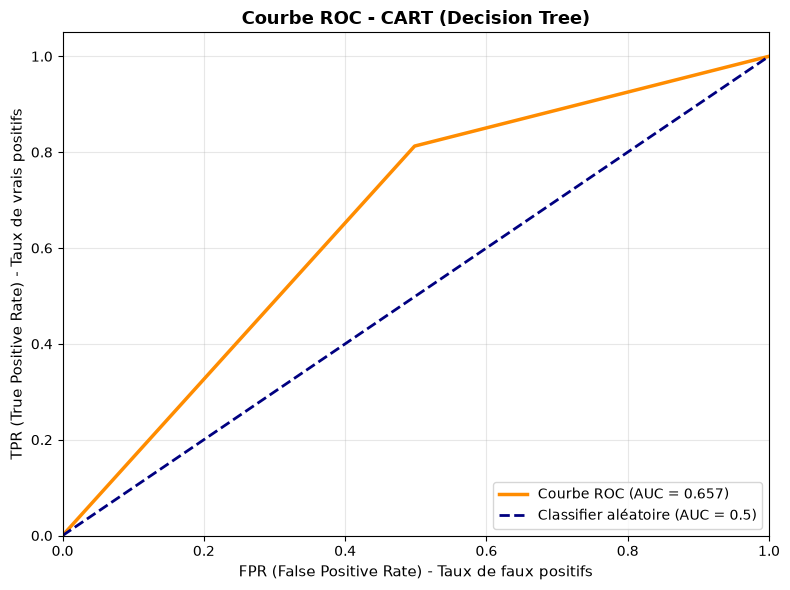

   • AUC-ROC : 0.6572
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7262      72.62%        % total de prédictions correctes
Recall (Sensibilité) 0.8127      81.27%              % de bons clients acceptés
           Precision 0.8091      80.91% % de crédits accordés à de bons clients
         Spécificité 0.5016      50.16%     % de défaillants détectés (refusés)
            F1-Score 0.8109           -              Équilibre Recall/Precision
             AUC-ROC 0.6572           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7262 + 0.8091) / 2
   Résultat: 0.7677

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte



                   ÉVALUATION DÉTAILLÉE - KNN (k=5)                   

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 258                 350
Réel Positif (1)                 206                1374

   Interprétation :
   • TN (Vrais Négatifs)  : 258 → Crédit refusé correctement
   • FP (Faux Positifs)   : 350 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 206 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1374 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


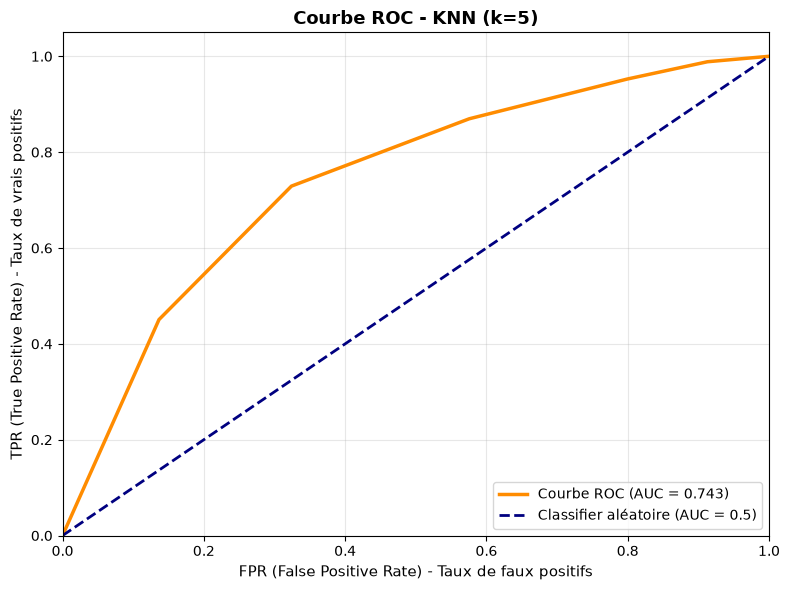

   • AUC-ROC : 0.7431
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7459      74.59%        % total de prédictions correctes
Recall (Sensibilité) 0.8696      86.96%              % de bons clients acceptés
           Precision 0.7970      79.70% % de crédits accordés à de bons clients
         Spécificité 0.4243      42.43%     % de défaillants détectés (refusés)
            F1-Score 0.8317           -              Équilibre Recall/Precision
             AUC-ROC 0.7431           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7459 + 0.7970) / 2
   Résultat: 0.7714

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

    Modèle entraîné


                  ÉVALUATION DÉTAILLÉE - MLP (40,20)                  

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 331                 277
Réel Positif (1)                 264                1316

   Interprétation :
   • TN (Vrais Négatifs)  : 331 → Crédit refusé correctement
   • FP (Faux Positifs)   : 277 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 264 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1316 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


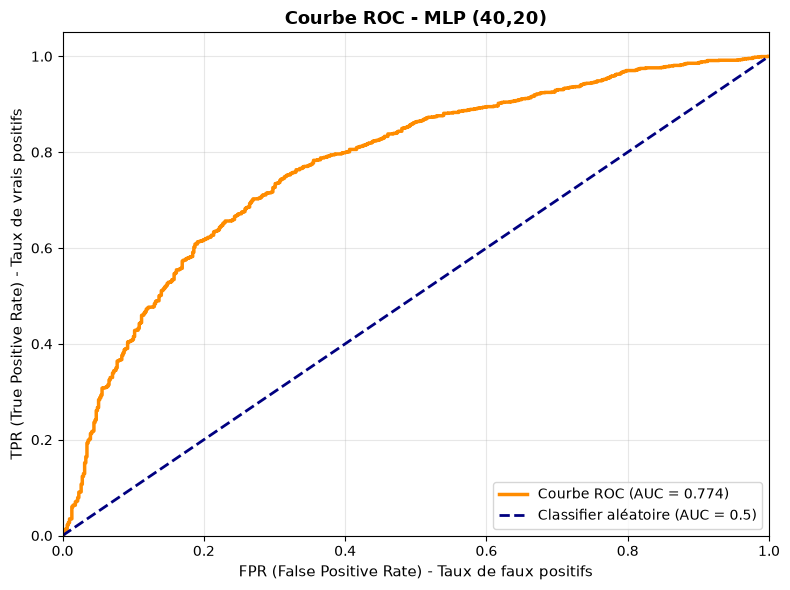

   • AUC-ROC : 0.7739
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7527      75.27%        % total de prédictions correctes
Recall (Sensibilité) 0.8329      83.29%              % de bons clients acceptés
           Precision 0.8261      82.61% % de crédits accordés à de bons clients
         Spécificité 0.5444      54.44%     % de défaillants détectés (refusés)
            F1-Score 0.8295           -              Équilibre Recall/Precision
             AUC-ROC 0.7739           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7527 + 0.8261) / 2
   Résultat: 0.7894

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

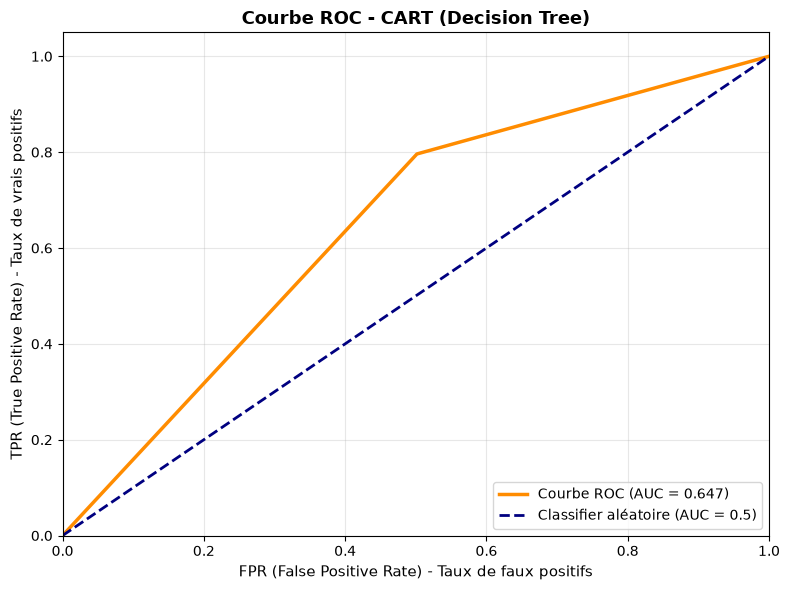

   • AUC-ROC : 0.6473
   • Interprétation : Discrimination faible


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7134      71.34%        % total de prédictions correctes
Recall (Sensibilité) 0.7962      79.62%              % de bons clients acceptés
           Precision 0.8049      80.49% % de crédits accordés à de bons clients
         Spécificité 0.4984      49.84%     % de défaillants détectés (refusés)
            F1-Score 0.8005           -              Équilibre Recall/Precision
             AUC-ROC 0.6473           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7134 + 0.8049) / 2
   Résultat: 0.7591

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

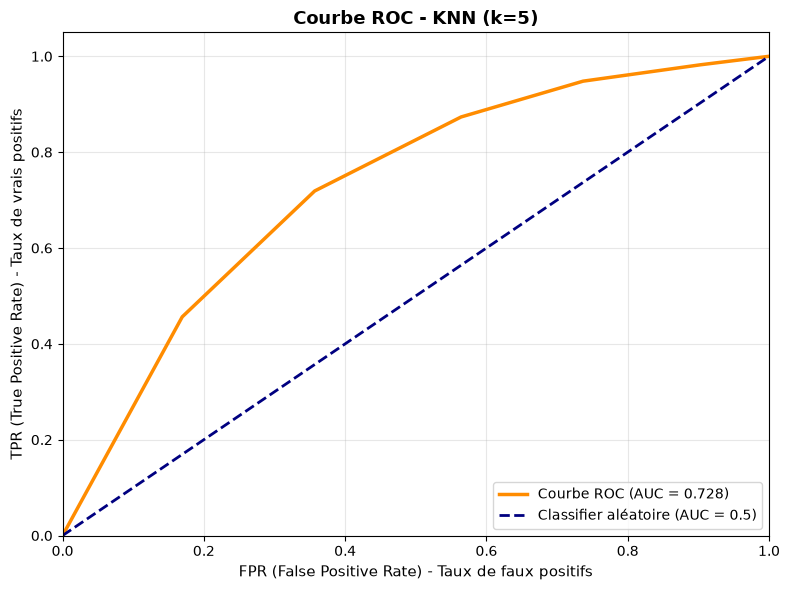

   • AUC-ROC : 0.7276
   • Interprétation : Discrimination acceptable


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7518      75.18%        % total de prédictions correctes
Recall (Sensibilité) 0.8734      87.34%              % de bons clients acceptés
           Precision 0.8009      80.09% % de crédits accordés à de bons clients
         Spécificité 0.4359      43.59%     % de défaillants détectés (refusés)
            F1-Score 0.8356           -              Équilibre Recall/Precision
             AUC-ROC 0.7276           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7518 + 0.8009) / 2
   Résultat: 0.7764

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   c

    Modèle entraîné


                  ÉVALUATION DÉTAILLÉE - MLP (40,20)                  

 1. MATRICE DE CONFUSION
----------------------------------------------------------------------
                  Prédit Négatif (0)  Prédit Positif (1)
Réel Négatif (0)                 310                 298
Réel Positif (1)                 172                1408

   Interprétation :
   • TN (Vrais Négatifs)  : 310 → Crédit refusé correctement
   • FP (Faux Positifs)   : 298 → Crédit accepté à tort (RISQUE)
   • FN (Faux Négatifs)   : 172 → Crédit refusé à tort (PERTE)
   • TP (Vrais Positifs)  : 1408 → Crédit accepté correctement


 2. COURBE ROC ET AUC
----------------------------------------------------------------------


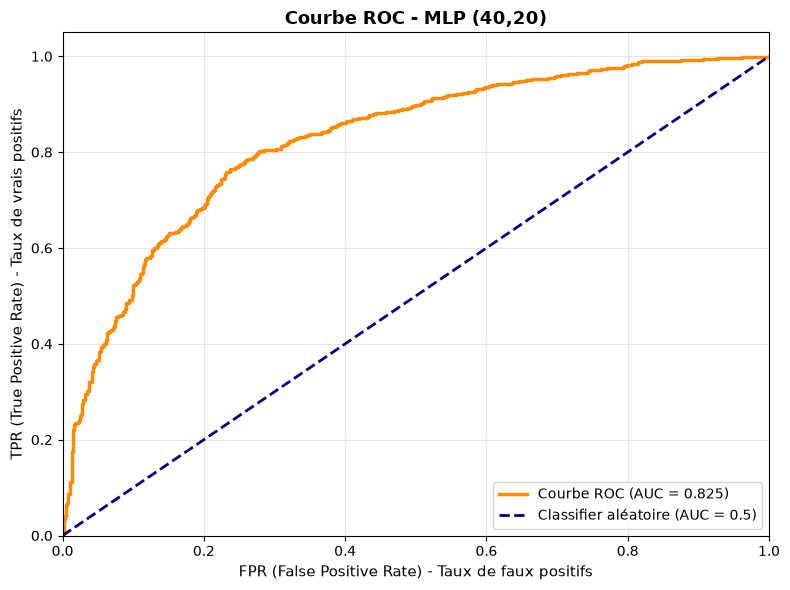

   • AUC-ROC : 0.8252
   • Interprétation : Bonne discrimination 


 3. MÉTRIQUES D'ÉVALUATION
----------------------------------------------------------------------
            Métrique Valeur Pourcentage                           Signification
            Accuracy 0.7852      78.52%        % total de prédictions correctes
Recall (Sensibilité) 0.8911      89.11%              % de bons clients acceptés
           Precision 0.8253      82.53% % de crédits accordés à de bons clients
         Spécificité 0.5099      50.99%     % de défaillants détectés (refusés)
            F1-Score 0.8570           -              Équilibre Recall/Precision
             AUC-ROC 0.8252           -      Capacité à discriminer les classes


 4. SCORE FINAL
----------------------------------------------------------------------
   Formule : Score Final = (Accuracy + Precision) / 2
   Calcul  : (0.7852 + 0.8253) / 2
   Résultat: 0.8053

   Pourquoi la Precision ? Accorder un crédit à un défaillant (FP)
   coûte

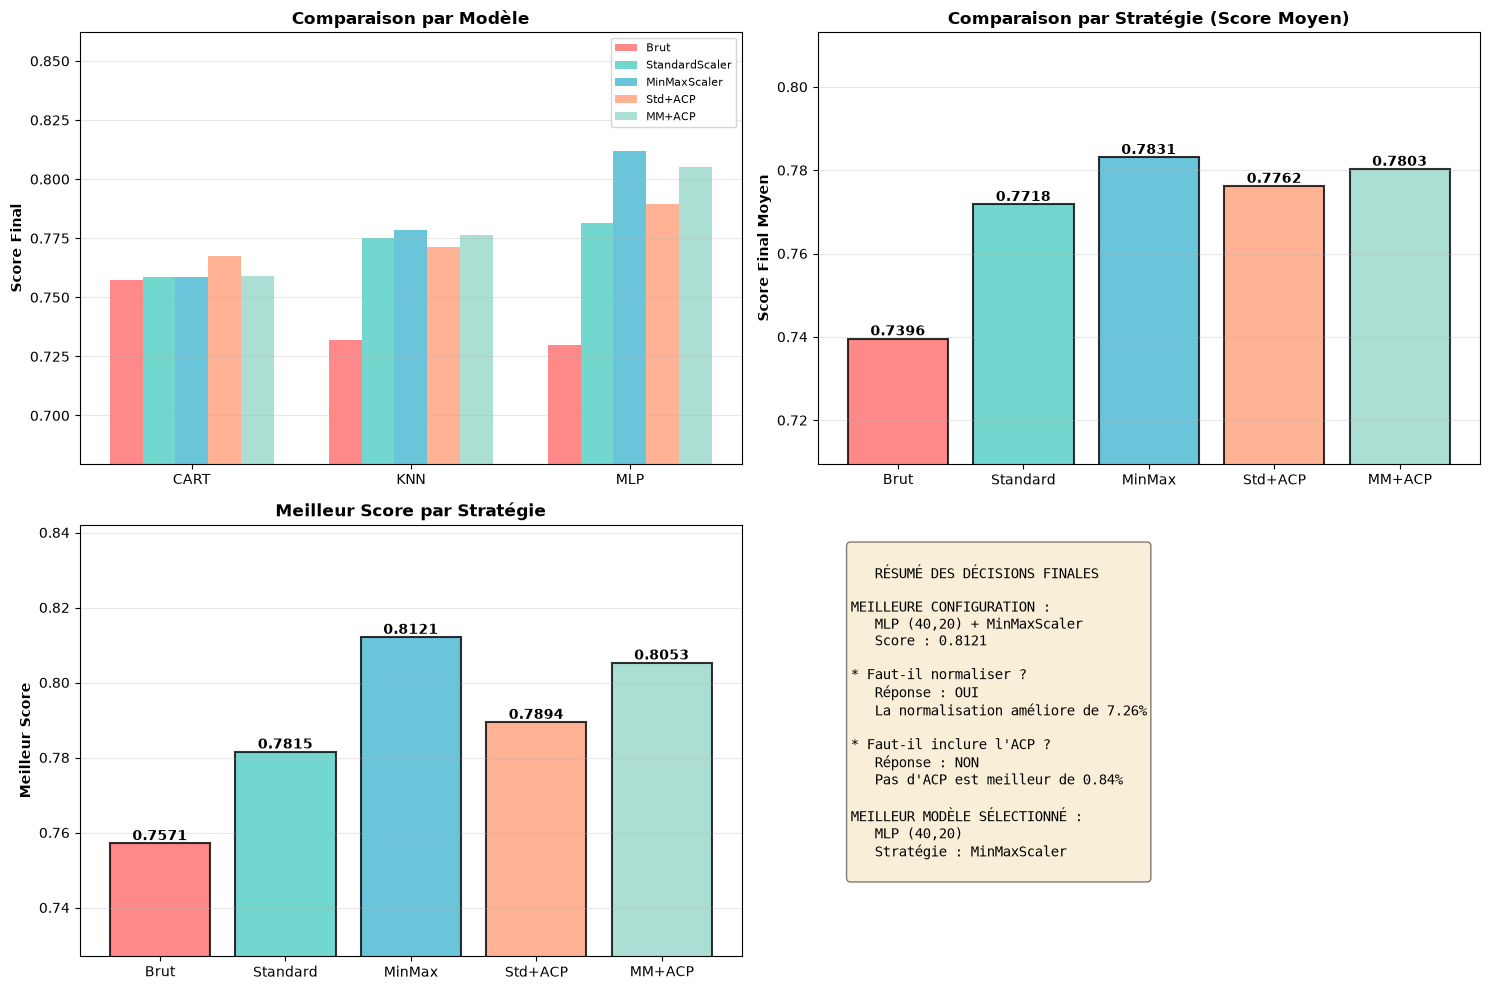

   Graphiques affichés


----------------------------------------------------------------------

MEILLEURE STRATÉGIE GLOBALE :
----------------------------------------------------------------------
   Configuration : MLP (40,20) + MinMaxScaler
   Score Final : 0.8121
   Cela signifie : cette combinaison modèle + stratégie
                   donne le meilleur score

RÉPONSES AUX QUESTIONS DU TP :
----------------------------------------------------------------------
   Q1 - Faut-il normaliser ? OUI
        La normalisation améliore de 7.26%
        → Si OUI : utiliser StandardScaler ou MinMaxScaler
        → Si NON : garder données brutes

   Q2 - Faut-il inclure l'ACP ? NON
        Pas d'ACP est meilleur de 0.84%
        → Si OUI : ajouter 3 composantes PCA
        → Si NON : garder les 13 features originales

VARIABLES CRÉÉES :
----------------------------------------------------------------------
pca_standard : objet PCA entraîné sur StandardScaler
pca_minmax : objet PCA entraîné sur

In [6]:
# ============================================
# ACP SUR DONNÉES NORMALISÉES
# ============================================
# Créer 3 nouvelles features par combinaisons linéaires
# Réduire dimensionnalité et potentiellement améliorer les modèles
# Important : Appliquer l'ACP aux données normalisées et comparer

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("\n" + "="*70)
print("SPRINT 1.4 - ACP SUR DONNÉES NORMALISÉES".center(70))
print("="*70)

# ============================================
# ÉTAPE 1 : RAPPEL DES STRATÉGIES À COMPARER
# Récapituler les stratégies testées jusqu'à présent

print("\n1️⃣  RÉCAPITULATIF DES STRATÉGIES TESTÉES JUSQU'À PRÉSENT")
print("-" * 70)

# Afficher ce qu'on a testé
print("\nSTRATÉGIES TESTÉES DANS LES SPRINTS PRÉCÉDENTS :")
print("   1️⃣  Données BRUTES (sans normalisation, sans ACP)")
print("       → Résultats dans : results_raw")
print("   2️⃣  Données NORMALISÉES avec StandardScaler")
print("       → Résultats dans : results_standard")
print("   3️⃣  Données NORMALISÉES avec MinMaxScaler")
print("       → Résultats dans : results_minmax")

# ============================================
# ÉTAPE 2 : APPLIQUER ACP SUR DONNÉES NORMALISÉES
# Tester ACP sur les données StandardScaler et MinMaxScaler

print("\n2️⃣  APPLICATION DE L'ACP SUR DONNÉES NORMALISÉES")
print("-" * 70)

# ===== 2A : ACP SUR DONNÉES StandardScaler =====
# Configuration A : Normalisation StandardScaler + ACP
print("\n  Configuration A : StandardScaler + ACP")
print("      Étapes :")
print("      1. Récupérer X_train_standard et X_test_standard")
print("      2. Appliquer PCA sur ces données normalisées")
print("      3. Concaténer les 3 composantes PCA")
print("      4. Tester les 3 modèles (CART, KNN, MLP)")

# Créer et entraîner l'ACP
print("\n   Création et fit de l'ACP...")
pca_standard = PCA(n_components=3)
# PCA(n_components=3) = créer 3 composantes principales
# Pourquoi 3 ? C'est ce que le TP demande

# IMPORTANT : Fit UNIQUEMENT sur X_train_standard
# Ne jamais fit sur X_test → éviter la fuite de données
pca_standard.fit(X_train_standard)
# X_train_standard vient du Sprint 1.3 (données StandardScaler normalisées)
print("   ACP entraînée sur données StandardScaler")
print("      L'ACP apprend les directions principales à partir du train")

# Transformer (appliquer l'ACP)
print("\n   Transformation des données...")
X_train_standard_pca = pca_standard.transform(X_train_standard)
# transform() = projeter X_train_standard sur les 3 composantes
# Résultat : (2187, 3) au lieu de (2187, 13)

X_test_standard_pca = pca_standard.transform(X_test_standard)
# Utiliser le MÊME PCA entraîné sur train
# IMPORTANT : Ne pas créer un nouveau PCA pour le test

print(f"   Composantes créées : shape {X_train_standard_pca.shape}")
print(f"      De (2187, 13) features à (2187, 3) composantes PCA")

# Afficher la variance expliquée
print("\n   Variance expliquée par chaque composante :")
print("      (Combien d'information chaque PC capture)")

total_var_standard = 0
for i, var in enumerate(pca_standard.explained_variance_ratio_):
    # explained_variance_ratio_ = proportion de variance expliquée
    total_var_standard += var
    cumsum = total_var_standard
    print(f"      • PC{i+1} : {var*100:.2f}% (cumulatif : {cumsum*100:.2f}%)")

# Concaténer avec les données normalisées
print("\n   Concaténation avec données normalisées...")
print("      Plutôt que de REMPLACER, on AJOUTE les composantes")

# IMPORTANT : concaténer aux données NORMALISÉES
X_train_standard_pca_concat = np.concatenate([X_train_standard, X_train_standard_pca], axis=1)
# np.concatenate(..., axis=1) = ajouter des colonnes
# Résultat : 13 features originales + 3 composantes = 16 features

X_test_standard_pca_concat = np.concatenate([X_test_standard, X_test_standard_pca], axis=1)

print(f"   X_train : {X_train_standard_pca_concat.shape} (13 + 3 = 16)")
print(f"   X_test : {X_test_standard_pca_concat.shape} (13 + 3 = 16)")

# Réentraîner les modèles avec les données augmentées
print("\n   Réentraînement des modèles...")
print("      Créer 3 nouveaux modèles (CART, KNN, MLP)")

clfs_dict_standard_pca = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    # Arbre de décision
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    # K plus proches voisins
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20),
                                  random_state=1, max_iter=1000)
    # Réseau de neurones
}

# Appeler la fonction du Sprint 1.2 pour entraîner et évaluer
best_model_std_pca, best_name_std_pca, results_standard_pca = run_classifiers_train_test(
    clfs_dict_standard_pca,  # Dictionnaire des modèles
    X_train_standard_pca_concat,  # Données train (16 features)
    y_train,  # Target train
    X_test_standard_pca_concat,  # Données test (16 features)
    y_test  # Target test
)

# ===== 2B : ACP SUR DONNÉES MinMaxScaler =====
# Configuration B : Normalisation MinMaxScaler + ACP
print("\n\n   Configuration B : MinMaxScaler + ACP")
print("      Étapes similaires à Configuration A...")
print("      Mais on utilise X_train_minmax et X_test_minmax")

# Créer et entraîner l'ACP
print("\n   Création et fit de l'ACP...")
pca_minmax = PCA(n_components=3)
# Fit UNIQUEMENT sur X_train_minmax
pca_minmax.fit(X_train_minmax)
# X_train_minmax vient du Sprint 1.3

print("   ACP entraînée sur données MinMaxScaler")

# Transformer
print("\n   Transformation des données...")
X_train_minmax_pca = pca_minmax.transform(X_train_minmax)
X_test_minmax_pca = pca_minmax.transform(X_test_minmax)
print(f"   Composantes créées : shape {X_train_minmax_pca.shape}")

# Afficher la variance expliquée
print("\n   Variance expliquée par chaque composante :")

total_var_minmax = 0
for i, var in enumerate(pca_minmax.explained_variance_ratio_):
    total_var_minmax += var
    cumsum = total_var_minmax
    print(f"      • PC{i+1} : {var*100:.2f}% (cumulatif : {cumsum*100:.2f}%)")

# Concaténer avec les données normalisées
print("\n   Concaténation avec données normalisées...")
X_train_minmax_pca_concat = np.concatenate([X_train_minmax, X_train_minmax_pca], axis=1)
X_test_minmax_pca_concat = np.concatenate([X_test_minmax, X_test_minmax_pca], axis=1)

print(f"   X_train : {X_train_minmax_pca_concat.shape} (13 + 3 = 16)")
print(f"   X_test : {X_test_minmax_pca_concat.shape} (13 + 3 = 16)")

# Réentraîner les modèles
print("\n   Réentraînement des modèles...")
clfs_dict_minmax_pca = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20),
                                  random_state=1, max_iter=1000)
}

# Entraîner et évaluer
best_model_mm_pca, best_name_mm_pca, results_minmax_pca = run_classifiers_train_test(
    clfs_dict_minmax_pca,
    X_train_minmax_pca_concat,  # Données train (16 features)
    y_train,
    X_test_minmax_pca_concat,  # Données test (16 features)
    y_test
)

# ============================================
# ÉTAPE 3 : TABLEAU COMPARATIF COMPLET
# ============================================
# Comparer TOUTES les 5 stratégies

print("\n\n3️⃣  TABLEAU COMPARATIF COMPLET (TOUTES LES STRATÉGIES)")
print("-" * 70)

print("\n COMPARAISON DES 5 STRATÉGIES POUR CHAQUE MODÈLE :")
print("   Stratégies : Brut, StandardScaler, MinMaxScaler, Std+ACP, MM+ACP")

# Créer le tableau complet
comparison_all_strategies = []

for clf_name in results_raw.keys():
    # Récupérer les scores pour chaque stratégie
    score_raw = results_raw[clf_name]['score_final']  # Données brutes
    score_standard = results_standard[clf_name]['score_final']  # StandardScaler
    score_minmax = results_minmax[clf_name]['score_final']  # MinMaxScaler
    score_standard_pca = results_standard_pca[clf_name]['score_final']  # StandardScaler + ACP
    score_minmax_pca = results_minmax_pca[clf_name]['score_final']  # MinMaxScaler + ACP

    # Trouver la meilleure stratégie pour ce modèle
    scores = {
        'Brut': score_raw,
        'Standard': score_standard,
        'MinMax': score_minmax,
        'Std+ACP': score_standard_pca,
        'MM+ACP': score_minmax_pca
    }
    best_strategy = max(scores, key=scores.get)
    best_score = scores[best_strategy]

    # Ajouter à la liste
    comparison_all_strategies.append({
        'Modèle': clf_name,
        'Brut': f"{score_raw:.4f}",
        'Standard': f"{score_standard:.4f}",
        'MinMax': f"{score_minmax:.4f}",
        'Std+ACP': f"{score_standard_pca:.4f}",
        'MM+ACP': f"{score_minmax_pca:.4f}",
        'Meilleur': f"{best_strategy} ({best_score:.4f})"
    })

# Créer et afficher le tableau
comparison_all_df = pd.DataFrame(comparison_all_strategies)
print("\n" + comparison_all_df.to_string(index=False))

# ============================================
# ÉTAPE 4 : ANALYSE GLOBALE
# ============================================
# Analyser les résultats en détail

print("\n\n4️⃣  ANALYSE DES RÉSULTATS")
print("-" * 70)

print("\n RÉSUMÉ PAR STRATÉGIE :")
print("   Score moyen de chaque stratégie sur les 3 modèles")

# Calculer le score moyen pour chaque stratégie
strategies_summary = {
    'Brut': [],
    'StandardScaler': [],
    'MinMaxScaler': [],
    'StandardScaler + ACP': [],
    'MinMaxScaler + ACP': []
}

# Remplir les listes
for clf_name in results_raw.keys():
    strategies_summary['Brut'].append(results_raw[clf_name]['score_final'])
    strategies_summary['StandardScaler'].append(results_standard[clf_name]['score_final'])
    strategies_summary['MinMaxScaler'].append(results_minmax[clf_name]['score_final'])
    strategies_summary['StandardScaler + ACP'].append(results_standard_pca[clf_name]['score_final'])
    strategies_summary['MinMaxScaler + ACP'].append(results_minmax_pca[clf_name]['score_final'])

# Afficher les statistiques
for strategy_name, scores in strategies_summary.items():
    # Calculer les statistiques
    mean_score = np.mean(scores)
    max_score = max(scores)

    # Afficher
    print(f"\n   {strategy_name}:")
    print(f"      • Score moyen : {mean_score:.4f}")
    print(f"      • Meilleur score : {max_score:.4f}")

# ============================================
# ÉTAPE 5 : IDENTIFIER LA MEILLEURE STRATÉGIE
# Trouver la configuration optimale (meilleur modèle + meilleure stratégie)

print("\n\n5️⃣  IDENTIFICATION DE LA MEILLEURE STRATÉGIE GLOBALE")
print("-" * 70)

# Créer un dictionnaire de TOUS les scores
# Clé : "Modèle + Stratégie", Valeur : Score
all_configs = {}

for clf_name in results_raw.keys():
    all_configs[f"{clf_name} + Brut"] = results_raw[clf_name]['score_final']
    all_configs[f"{clf_name} + StandardScaler"] = results_standard[clf_name]['score_final']
    all_configs[f"{clf_name} + MinMaxScaler"] = results_minmax[clf_name]['score_final']
    all_configs[f"{clf_name} + StandardScaler+ACP"] = results_standard_pca[clf_name]['score_final']
    all_configs[f"{clf_name} + MinMaxScaler+ACP"] = results_minmax_pca[clf_name]['score_final']

# Trouver la meilleure combinaison
best_config = max(all_configs, key=all_configs.get)
best_score = all_configs[best_config]

# Afficher le résultat
print(f"\nMEILLEURE CONFIGURATION GLOBALE :")
print(f"   Configuration : {best_config}")
print(f"   Score Final : {best_score:.4f}")

# Analyser la meilleure config
parts = best_config.split(' + ')
best_model_name = parts[0]
best_prep_strategy = ' + '.join(parts[1:])

print(f"\n Détails :")
print(f"   • Modèle : {best_model_name}")
print(f"   • Stratégie de préparation : {best_prep_strategy}")
print(f"   • Cela signifie : on utilise ce modèle avec cette préparation")

# ============================================
# ÉTAPE 6 : DÉCISIONS FINALES
# ============================================
# Répondre aux 2 questions du TP

print("\n\n6️⃣  RÉPONSES AUX QUESTIONS DU TP")
print("-" * 70)

# QUESTION 1 : Faut-il normaliser ?
print(f"\n Question 1 : Faut-il normaliser ?")
print(f"-" * 70)

# Comparer le meilleur sans normalisation vs le meilleur avec normalisation
raw_best = max(results_raw.values(), key=lambda x: x['score_final'])
# Prendre le meilleur parmi StandardScaler et MinMaxScaler
normalized_best = max(list(results_standard.values()) + list(results_minmax.values()),
                      key=lambda x: x['score_final'])

# Prendre une décision
if normalized_best['score_final'] > raw_best['score_final']:
    normalize_decision = "OUI"
    # Calculer l'amélioration en %
    improvement = (normalized_best['score_final'] - raw_best['score_final']) / raw_best['score_final'] * 100
    normalize_info = f"La normalisation améliore de {improvement:.2f}%"
else:
    normalize_decision = "NON"
    # Calculer la dégradation en %
    degradation = (raw_best['score_final'] - normalized_best['score_final']) / raw_best['score_final'] * 100
    normalize_info = f"Pas de normalisation est meilleur de {degradation:.2f}%"

# Afficher la réponse
print(f"   Réponse : {normalize_decision}")
print(f"      Raison : {normalize_info}")

# QUESTION 2 : Faut-il inclure les composantes ACP ?
print(f"\n Question 2 : Faut-il inclure les composantes ACP ?")
print(f"-" * 70)

# Comparer le meilleur sans ACP vs le meilleur avec ACP
without_acp_best = max(list(results_raw.values()) + list(results_standard.values()) + list(results_minmax.values()),
                       key=lambda x: x['score_final'])
# Prendre le meilleur parmi StandardScaler+ACP et MinMaxScaler+ACP
with_acp_best = max(list(results_standard_pca.values()) + list(results_minmax_pca.values()),
                    key=lambda x: x['score_final'])

# Prendre une décision
if with_acp_best['score_final'] > without_acp_best['score_final']:
    acp_decision = "OUI"
    # Calculer l'amélioration en %
    improvement = (with_acp_best['score_final'] - without_acp_best['score_final']) / without_acp_best['score_final'] * 100
    acp_info = f"L'ACP améliore de {improvement:.2f}%"
else:
    acp_decision = "NON"
    # Calculer la dégradation en %
    degradation = (without_acp_best['score_final'] - with_acp_best['score_final']) / without_acp_best['score_final'] * 100
    acp_info = f"Pas d'ACP est meilleur de {degradation:.2f}%"

# Afficher la réponse
print(f"   Réponse : {acp_decision}")
print(f"      Raison : {acp_info}")

# ============================================
# ÉTAPE 7 : VISUALISATION COMPARATIVE
# ============================================
# Afficher les résultats sous forme de graphiques

print("\n\n7️⃣  VISUALISATION COMPARATIVE")
print("-" * 70)

# Créer une figure avec 4 sous-graphiques
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# GRAPHIQUE 1 : Comparaison par modèle
# Voir comment chaque modèle performe avec chaque stratégie
ax1 = axes[0, 0]
model_names_short = ['CART', 'KNN', 'MLP']
x = np.arange(len(model_names_short))
width = 0.15  # Largeur de chaque barre

# Récupérer les scores
models_long = ['CART (Decision Tree)', 'KNN (k=5)', 'MLP (40,20)']
scores_raw = [results_raw[m]['score_final'] for m in models_long]
scores_std = [results_standard[m]['score_final'] for m in models_long]
scores_mm = [results_minmax[m]['score_final'] for m in models_long]
scores_std_pca = [results_standard_pca[m]['score_final'] for m in models_long]
scores_mm_pca = [results_minmax_pca[m]['score_final'] for m in models_long]
toutes_valeurs = scores_raw + scores_std + scores_mm + scores_std_pca + scores_mm_pca

# Tracer les barres
ax1.bar(x - 2*width, scores_raw, width, label='Brut', alpha=0.8, color='#FF6B6B')
ax1.bar(x - width, scores_std, width, label='StandardScaler', alpha=0.8, color='#4ECDC4')
ax1.bar(x, scores_mm, width, label='MinMaxScaler', alpha=0.8, color='#45B7D1')
ax1.bar(x + width, scores_std_pca, width, label='Std+ACP', alpha=0.8, color='#FFA07A')
ax1.bar(x + 2*width, scores_mm_pca, width, label='MM+ACP', alpha=0.8, color='#98D8C8')

# Décorer
ax1.set_ylabel('Score Final', fontweight='bold')
ax1.set_title('Comparaison par Modèle', fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(model_names_short)
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim([max(0, min(toutes_valeurs) - 0.05), min(1, max(toutes_valeurs) + 0.05)])

# GRAPHIQUE 2 : Comparaison par stratégie (score moyen)
# Voir quel préparation est meilleure en moyenne
ax2 = axes[0, 1]
strategies = ['Brut', 'Standard', 'MinMax', 'Std+ACP', 'MM+ACP']
strategy_scores = []

# Calculer le score moyen pour chaque stratégie
for strategy in strategies:
    if strategy == 'Brut':
        s = np.mean([results_raw[m]['score_final'] for m in models_long])
    elif strategy == 'Standard':
        s = np.mean([results_standard[m]['score_final'] for m in models_long])
    elif strategy == 'MinMax':
        s = np.mean([results_minmax[m]['score_final'] for m in models_long])
    elif strategy == 'Std+ACP':
        s = np.mean([results_standard_pca[m]['score_final'] for m in models_long])
    elif strategy == 'MM+ACP':
        s = np.mean([results_minmax_pca[m]['score_final'] for m in models_long])
    strategy_scores.append(s)

# Tracer les barres
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8']
bars = ax2.bar(strategies, strategy_scores, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Ajouter les valeurs sur les barres
for bar in bars:
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}', ha='center', va='bottom', fontweight='bold')

# Décorer
ax2.set_ylabel('Score Final Moyen', fontweight='bold')
ax2.set_title('Comparaison par Stratégie (Score Moyen)', fontweight='bold')
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim([max(0, min(strategy_scores) - 0.03), min(1, max(strategy_scores) + 0.03)])

# GRAPHIQUE 3 : Meilleur score par stratégie
# Voir le meilleur score qu'on peut obtenir avec chaque stratégie
ax3 = axes[1, 0]
best_scores_per_strategy = [
    max([results_raw[m]['score_final'] for m in models_long]),
    max([results_standard[m]['score_final'] for m in models_long]),
    max([results_minmax[m]['score_final'] for m in models_long]),
    max([results_standard_pca[m]['score_final'] for m in models_long]),
    max([results_minmax_pca[m]['score_final'] for m in models_long])
]

# Tracer les barres
bars = ax3.bar(strategies, best_scores_per_strategy, color=colors, alpha=0.8, edgecolor='black', linewidth=1.5)

# Ajouter les valeurs
for bar in bars:
    height = bar.get_height()
    ax3.text(bar.get_x() + bar.get_width()/2., height,
            f'{height:.4f}', ha='center', va='bottom', fontweight='bold')

# Décorer
ax3.set_ylabel('Meilleur Score', fontweight='bold')
ax3.set_title('Meilleur Score par Stratégie', fontweight='bold')
ax3.grid(axis='y', alpha=0.3)
ax3.set_ylim([max(0, min(best_scores_per_strategy) - 0.03), min(1, max(best_scores_per_strategy) + 0.03)])

# GRAPHIQUE 4 : Résumé textuel
# Afficher les décisions finales en texte
ax4 = axes[1, 1]
ax4.axis('off')

# Créer le texte du résumé
summary_text = f"""
   RÉSUMÉ DES DÉCISIONS FINALES

MEILLEURE CONFIGURATION :
   {best_config}
   Score : {best_score:.4f}

* Faut-il normaliser ?
   Réponse : {normalize_decision}
   {normalize_info}

* Faut-il inclure l'ACP ?
   Réponse : {acp_decision}
   {acp_info}

MEILLEUR MODÈLE SÉLECTIONNÉ :
   {best_model_name}
   Stratégie : {best_prep_strategy}
"""

# Afficher le texte
ax4.text(0.05, 0.95, summary_text, transform=ax4.transAxes,
        fontsize=10, verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

# Afficher la figure
plt.tight_layout()
plt.show()

print("   Graphiques affichés")

# ============================================
# ÉTAPE 8 : RÉSUMÉ FINAL

print("\n\n" + "-"*70)


# Récapituler ce qui a été fait

#1. ACP appliquée sur données StandardScaler
#   Stratégie : données StandardScaler → ACP → modèles
#2. ACP appliquée sur données MinMaxScaler
#   Stratégie : données MinMaxScaler → ACP → modèles
#3. Tableau comparatif COMPLET (5 stratégies)
#   Toutes les combinaisons : Brut, Std, MM, Std+ACP, MM+ACP
#4. Graphiques comparatifs (4 graphiques)
#   Par modèle, par stratégie, meilleur score, résumé
#5. Réponses claires aux 2 questions du TP
#   Q1 et Q2 avec justifications chiffrées
#6. Identification de la meilleure stratégie
#   Configuration optimale trouvée et expliquée

# Résumer les 5 stratégies

#LES 5 STRATÉGIES TESTÉES :
#1. Données BRUTES
#   → Aucune préparation
#   → Résultats dans : results_raw
#2. StandardScaler (normalisation)
#   → Formule : (X - moyenne) / écart-type
#   → Résultats dans : results_standard
#3. MinMaxScaler (normalisation)
#   → Formule : (X - min) / (max - min)
#   → Résultats dans : results_minmax
#4. StandardScaler + ACP
#   → Normaliser PUIS appliquer ACP
#   → Résultats dans : results_standard_pca
#5. MinMaxScaler + ACP
#   → Normaliser PUIS appliquer ACP
#   → Résultats dans : results_minmax_pca

# Afficher la meilleure stratégie
print("\nMEILLEURE STRATÉGIE GLOBALE :")
print("-" * 70)
print(f"   Configuration : {best_config}")
print(f"   Score Final : {best_score:.4f}")
print(f"   Cela signifie : cette combinaison modèle + stratégie")
print(f"                   donne le meilleur score")

# Réponses aux questions
print("\nRÉPONSES AUX QUESTIONS DU TP :")
print("-" * 70)
print(f"   Q1 - Faut-il normaliser ? {normalize_decision}")
print(f"        {normalize_info}")
print(f"        → Si OUI : utiliser StandardScaler ou MinMaxScaler")
print(f"        → Si NON : garder données brutes")
print(f"\n   Q2 - Faut-il inclure l'ACP ? {acp_decision}")
print(f"        {acp_info}")
print(f"        → Si OUI : ajouter 3 composantes PCA")
print(f"        → Si NON : garder les 13 features originales")

# Variables créées
print("\nVARIABLES CRÉÉES :")
print("-" * 70)
print(f"pca_standard : objet PCA entraîné sur StandardScaler")
print(f"pca_minmax : objet PCA entraîné sur MinMaxScaler")
print(f"X_train_standard_pca_concat : données Standard + ACP (2187, 16)")
print(f"X_test_standard_pca_concat : données Standard + ACP (2188, 16)")
print(f"X_train_minmax_pca_concat : données MinMax + ACP (2187, 16)")
print(f"X_test_minmax_pca_concat : données MinMax + ACP (2188, 16)")
print(f"results_standard_pca : résultats avec StandardScaler + ACP")
print(f"results_minmax_pca : résultats avec MinMaxScaler + ACP")

In [7]:
# ==============================================================================
# CONFIGURATION RETENUE POUR LA SUITE (Q5 -> Q7)
# ==============================================================================
# On réutilise la meilleure configuration trouvée en Q3/Q4 :
# le meilleur modèle ET la préparation des données associée

preparations = {
    'Brut': (X_train, X_test),
    'StandardScaler': (X_train_standard, X_test_standard),
    'MinMaxScaler': (X_train_minmax, X_test_minmax),
    'StandardScaler+ACP': (X_train_standard_pca_concat, X_test_standard_pca_concat),
    'MinMaxScaler+ACP': (X_train_minmax_pca_concat, X_test_minmax_pca_concat),
}
X_train_prep, X_test_prep = preparations[best_prep_strategy]

# Noms des variables (+ composantes ACP si elles ont été ajoutées)
feature_names_prep = feature_names + (['PC1', 'PC2', 'PC3'] if 'ACP' in best_prep_strategy else [])

# Modèle de base (non entraîné) correspondant au meilleur modèle
best_clf_base = clone(clfs_dict[best_model_name])
best_score_base = all_configs[best_config]

print("CONFIGURATION RETENUE POUR LA SUITE".center(70))
print("-" * 70)
print(f"   Modèle      : {best_model_name}")
print(f"   Préparation : {best_prep_strategy}")
print(f"   Score Final : {best_score_base:.4f}")
print(f"   Données     : X_train_prep {X_train_prep.shape}, X_test_prep {X_test_prep.shape}")

                 CONFIGURATION RETENUE POUR LA SUITE                  
----------------------------------------------------------------------
   Modèle      : MLP (40,20)
   Préparation : MinMaxScaler
   Score Final : 0.8121
   Données     : X_train_prep (2187, 13), X_test_prep (2188, 13)


### Q5. Sélection de variables

Importance des variables avec une RandomForest (1000 arbres), puis accuracy du meilleur modèle
en fonction du nombre de variables conservées (les plus importantes d'abord).
Une explication SHAP complète l'analyse.

                     Q5 - SÉLECTION DE VARIABLES                      

1  FONCTION 1 : plot_feature_importance()

   Test de la fonction...

   Entraînement d'un RandomForest pour calculer l'importance...


   RandomForest entraîné (1000 arbres)

  Top 5 variables les plus importantes :
      1. Income          : 0.1521
      2. Seniority       : 0.1281
      3. Price           : 0.1235
      4. Amount          : 0.1210
      5. Age             : 0.1040

   Création du graphique...


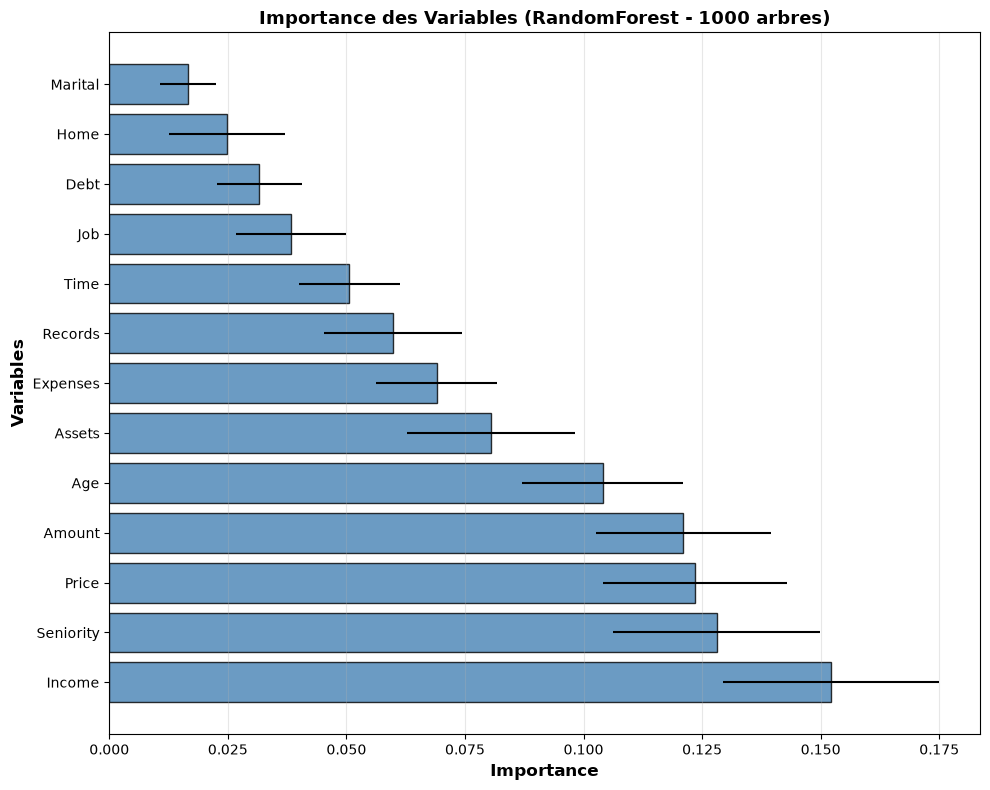

   Graphique adapté

   Fonction bien testée - 13 features bien  triées


In [8]:
print("Q5 - SÉLECTION DE VARIABLES".center(70))


print("\n1  FONCTION 1 : plot_feature_importance()")


def plot_feature_importance(X_train, y_train, feature_names):
    """
    Calcule et affiche l'importance des variables avec RandomForest

    Paramètres :
    - X_train : données d'entraînement
    - y_train : target d'entraînement
    - feature_names : noms des variables

    Retourne :
    - sorted_idx : indices des features triées par importance (du plus important au moins important)
    """

    print("\n   Entraînement d'un RandomForest pour calculer l'importance...")

    # Créer un RandomForest avec 1000 arbres
    rf = RandomForestClassifier(n_estimators=1000, random_state=1)

    # Entraîner sur les données
    rf.fit(X_train, y_train)
    print("   RandomForest entraîné (1000 arbres)")

    # Récupérer les importances
    importances = rf.feature_importances_

    # Calculer l'écart-type des importances (pour les barres d'erreur)
    std = np.std([tree.feature_importances_ for tree in rf.estimators_], axis=0)

    # Trier les features par importance (du plus important au moins important)
    sorted_idx = np.argsort(importances)[::-1]

    print(f"\n  Top 5 variables les plus importantes :")
    for i in range(min(5, len(sorted_idx))):
        idx = sorted_idx[i]
        print(f"      {i+1}. {feature_names[idx]:15s} : {importances[idx]:.4f}")

    # Créer le graphique
    print("\n   Création du graphique...")
    fig, ax = plt.subplots(figsize=(10, 8))

    # Créer un graphique horizontal (barres horizontales)
    y_pos = np.arange(len(feature_names))
    ax.barh(y_pos, importances[sorted_idx], xerr=std[sorted_idx],
            color='steelblue', alpha=0.8, edgecolor='black')

    # Ajouter les noms des features
    ax.set_yticks(y_pos)
    ax.set_yticklabels([feature_names[i] for i in sorted_idx])

    # Labels et titre
    ax.set_xlabel('Importance', fontsize=12, fontweight='bold')
    ax.set_ylabel('Variables', fontsize=12, fontweight='bold')
    ax.set_title('Importance des Variables (RandomForest - 1000 arbres)',
                 fontsize=13, fontweight='bold')

    # Grille
    ax.grid(axis='x', alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("   Graphique adapté")

    # Retourner les indices triés
    return sorted_idx

# Tester la fonction
print("\n   Test de la fonction...")
sorted_indices = plot_feature_importance(X_train_prep, y_train, feature_names_prep)
print(f"\n   Fonction bien testée - {len(sorted_indices)} features bien  triées")


2  FONCTION 2 : select_optimal_features()

   Test de la fonction avec le meilleur modèle (MLP (40,20), données : MinMaxScaler)...

   Teste de 1 à 13 features (en gardant les plus importantes)...


      1 feature(s) : Accuracy = 0.7221 (Income)


      2 feature(s) : Accuracy = 0.7523 (Seniority)


      3 feature(s) : Accuracy = 0.7445 (Price)


      4 feature(s) : Accuracy = 0.7665 (Amount)


      5 feature(s) : Accuracy = 0.7610 (Age)



  Résultat :
      Nombre optimal de features : 8
      Accuracy avec 8 features : 0.7952

  Features sélectionnées (top 8) :
      1. Income
      2. Seniority
      3. Price
      4. Amount
      5. Age
      6. Assets
      7. Expenses
      8. Records

   Création du graphique Accuracy vs Nombre de features...


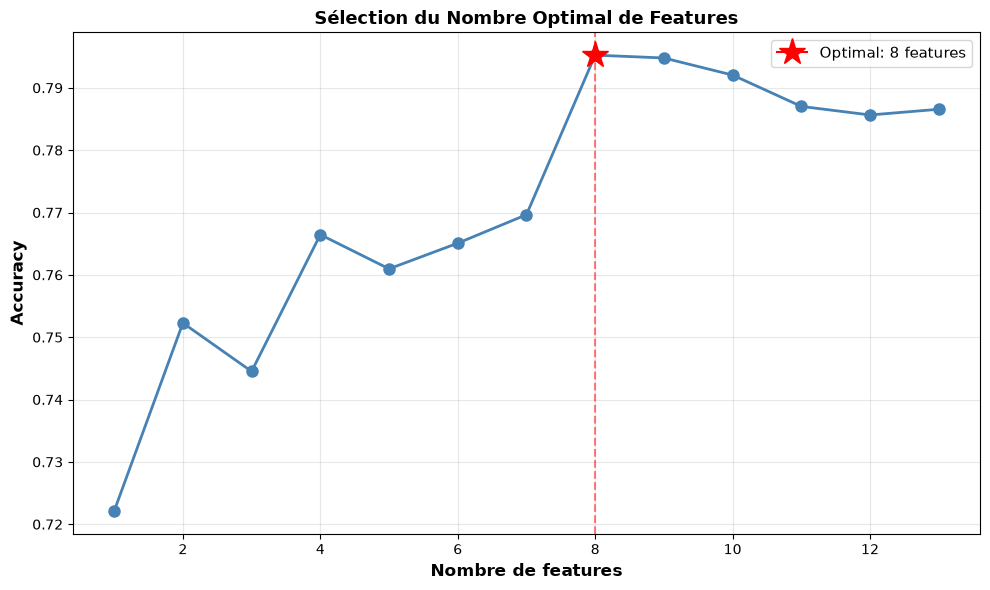

   Graphique adapté

  Fonction bien testée - Nombre optimal : 8 features
  Variables retenues : ['Income', 'Seniority', 'Price', 'Amount', 'Age', 'Assets', 'Expenses', 'Records']


In [9]:
print("\n2  FONCTION 2 : select_optimal_features()")


def select_optimal_features(best_clf, X_train, y_train, X_test, y_test, sorted_idx, feature_names):
    """
    Trouve le nombre optimal de features à utiliser

    Teste de 1 à n_features en gardant les plus importantes

    Paramètres :
    - best_clf : le meilleur classifieur identifié
    - X_train, y_train : données d'entraînement
    - X_test, y_test : données de test
    - sorted_idx : indices des features triées par importance
    - feature_names : noms des features

    Retourne :
    - n_optimal : nombre optimal de features
    - accuracies : liste des accuracies pour chaque nombre de features
    """

    print(f"\n   Teste de 1 à {X_train.shape[1]} features (en gardant les plus importantes)...")

    n_features = X_train.shape[1]
    accuracies = []

    # Pour chaque nombre de features (de 1 à n)
    for n in range(1, n_features + 1):
        # Prendre les n features les plus importantes
        selected_features = sorted_idx[:n]

        # Extraire ces features
        X_train_selected = X_train[:, selected_features]
        X_test_selected = X_test[:, selected_features]

        # Créer un nouveau modèle (clone du meilleur)
        from sklearn.base import clone
        clf_temp = clone(best_clf)

        # Entraîner
        clf_temp.fit(X_train_selected, y_train)

        # Prédire et calculer l'accuracy
        acc = clf_temp.score(X_test_selected, y_test)
        accuracies.append(acc)

        # Afficher les 5 premiers pour voir l'évolution
        if n <= 5:
            print(f"      {n} feature(s) : Accuracy = {acc:.4f} ({feature_names[selected_features[n-1]]})")

    # Trouver le nombre optimal (meilleure accuracy)
    n_optimal = np.argmax(accuracies) + 1  # +1 car index commence à 0
    best_accuracy = accuracies[n_optimal - 1]

    print(f"\n  Résultat :")
    print(f"      Nombre optimal de features : {n_optimal}")
    print(f"      Accuracy avec {n_optimal} features : {best_accuracy:.4f}")

    # Afficher les features sélectionnées
    print(f"\n  Features sélectionnées (top {n_optimal}) :")
    for i in range(n_optimal):
        idx = sorted_idx[i]
        print(f"      {i+1}. {feature_names[idx]}")

    # Créer le graphique
    print("\n   Création du graphique Accuracy vs Nombre de features...")
    fig, ax = plt.subplots(figsize=(10, 6))

    # Tracer la courbe
    x = list(range(1, n_features + 1))
    ax.plot(x, accuracies, marker='o', linewidth=2, markersize=8, color='steelblue')

    # Marquer le point optimal
    ax.plot(n_optimal, best_accuracy, marker='*', markersize=20,
            color='red', label=f'Optimal: {n_optimal} features')

    # Ajouter une ligne verticale au point optimal
    ax.axvline(x=n_optimal, color='red', linestyle='--', alpha=0.5)

    # Labels et titre
    ax.set_xlabel('Nombre de features', fontsize=12, fontweight='bold')
    ax.set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    ax.set_title('Sélection du Nombre Optimal de Features', fontsize=13, fontweight='bold')
    ax.legend(fontsize=11)
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("   Graphique adapté")

    return n_optimal, accuracies

# Tester la fonction
print(f"\n   Test de la fonction avec le meilleur modèle ({best_model_name}, données : {best_prep_strategy})...")

# Recréer le meilleur modèle (non entraîné)
best_clf_for_selection = clone(best_clf_base)

n_optimal, accuracies = select_optimal_features(
    best_clf_for_selection,
    X_train_prep, y_train,
    X_test_prep, y_test,
    sorted_indices,
    feature_names_prep
)

# Variables retenues pour la suite (Q6, Q7, Q10)
selected_features = sorted_indices[:n_optimal]

print(f"\n  Fonction bien testée - Nombre optimal : {n_optimal} features")
print(f"  Variables retenues : {[feature_names_prep[i] for i in selected_features]}")

                   FONCTION 3 : explain_with_shap()                   
                   TEST COMPLET - 3 GRAPHIQUES SHAP                   



 RandomForest entraine

 Creation de l'explainer SHAP...
   Type de modele : RandomForestClassifier
   -> TreeExplainer


   Explainer cree

 Shape initiale : (2188, 13, 2)
   -> Classe 1 extraite : (2188, 13)
   Shape finale : (2188, 13)
   Base value : 0.720827617741198

----------------------------------------------------------------------
              GRAPHIQUE 1/3 : Summary Plot (vue globale)              
----------------------------------------------------------------------


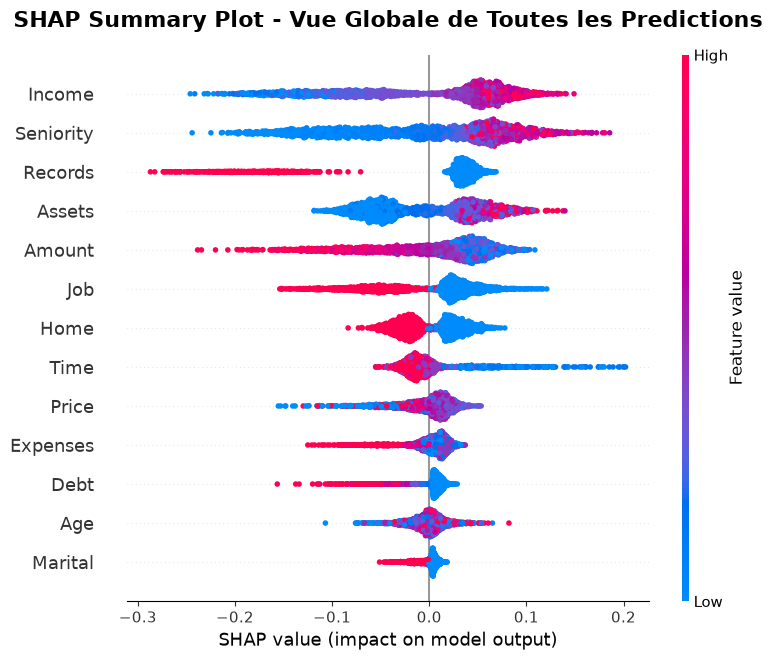


 Summary plot affiche

----------------------------------------------------------------------
            GRAPHIQUE 2/3 : Bar Plot (importance moyenne)             
----------------------------------------------------------------------


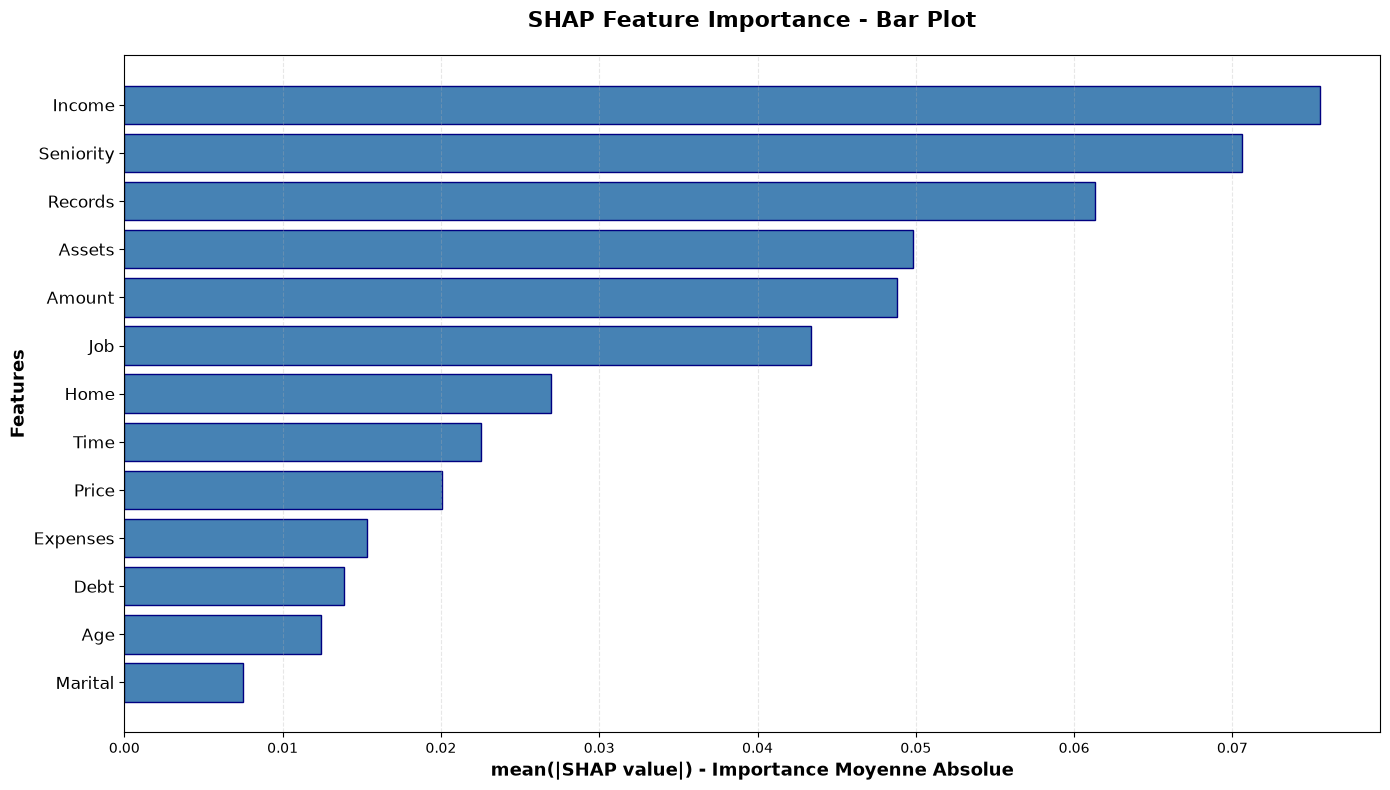


 Bar plot affiche

----------------------------------------------------------------------
      GRAPHIQUE 3/3 : Waterfall Plot (explication individuelle)       
----------------------------------------------------------------------

 -> Montre comment chaque feature contribue a UNE prediction

 Exemple choisi : individu #12
   Prediction : CREDIT ACCORDE
   Vraie valeur : CREDIT ACCORDE

 Caracteristiques de cet individu :
  Feature  Valeur
Seniority    14.0
     Home     1.0
     Time    60.0
      Age    60.0
  Marital     0.0
  Records     1.0
      Job     0.0
 Expenses    62.0
   Income   170.0
   Assets  8000.0
     Debt     0.0
   Amount   915.0
    Price  1396.0


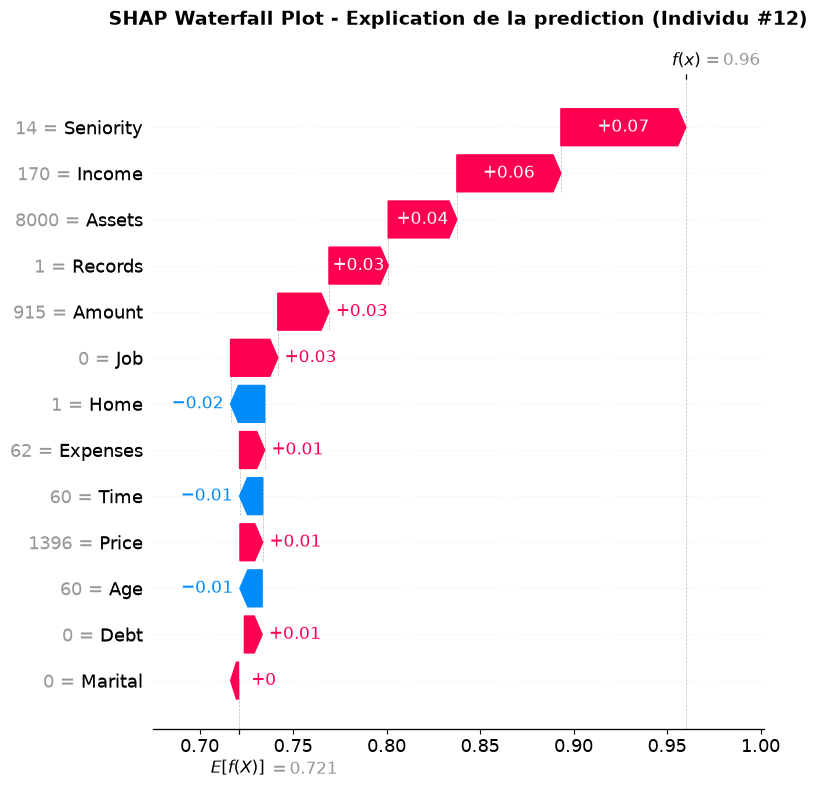


 Waterfall plot affiche

                   INTERPRETATION DES 3 GRAPHIQUES                    

 1. SUMMARY PLOT :
    - Vue GLOBALE de toutes les predictions
    - Rouge = valeur elevee | Bleu = valeur faible
    - Droite = pousse vers credit accorde

 2. BAR PLOT :
    - Importance MOYENNE de chaque feature
    - Plus c'est long = plus important en general

 3. WATERFALL PLOT :
    - Explication d'UNE prediction specifique
    - Montre comment on passe de la base value a la prediction
    - Chaque feature ajoute ou retire a la prediction

----------------------------------------------------------------------
                 TOP 3 FEATURES LES PLUS IMPORTANTES                  
----------------------------------------------------------------------
 Rang   Feature Importance
    1    Income     0.0755
    2 Seniority     0.0706
    3   Records     0.0613




In [10]:
print("="*70)
print("FONCTION 3 : explain_with_shap()".center(70))
print("="*70)

import shap
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def explain_with_shap(model, X_train, X_test, feature_names, max_display=13):
    """
    SHAP complet avec 3 graphiques :
    1. Summary Plot (vue globale)
    2. Bar Plot (importance moyenne)
    3. Waterfall Plot (explication individuelle)
    """

    # Convertir en liste
    feature_names = list(feature_names) if hasattr(feature_names, 'tolist') else list(feature_names)

    print("\n Creation de l'explainer SHAP...")

    model_type = type(model).__name__
    print(f"   Type de modele : {model_type}")

    try:
        if 'Tree' in model_type or 'Forest' in model_type:
            print("   -> TreeExplainer")
            explainer = shap.TreeExplainer(model)
            shap_values = explainer.shap_values(X_test)
        else:
            print("   -> KernelExplainer")
            background = shap.sample(X_train, min(100, len(X_train)))
            explainer = shap.KernelExplainer(model.predict, background)
            X_test_sample = X_test[:min(100, len(X_test))]
            shap_values = explainer.shap_values(X_test_sample)
            X_test = X_test_sample

        print("   Explainer cree")

    except Exception as e:
        print(f"   Erreur : {e}")
        return None, None

    print(f"\n Shape initiale : {np.array(shap_values).shape}")

    if isinstance(shap_values, list):
        shap_values_to_use = shap_values[1]
        base_value = explainer.expected_value[1]
        print(f"   -> Classe 1 selectionnee : {shap_values_to_use.shape}")
    elif len(shap_values.shape) == 3:
        shap_values_to_use = shap_values[:, :, 1]
        base_value = explainer.expected_value[1] if isinstance(explainer.expected_value, (list, np.ndarray)) else explainer.expected_value
        print(f"   -> Classe 1 extraite : {shap_values_to_use.shape}")
    else:
        shap_values_to_use = shap_values
        base_value = explainer.expected_value
        print(f"   -> Shape directe : {shap_values.shape}")

    print(f"   Shape finale : {shap_values_to_use.shape}")
    print(f"   Base value : {base_value}")

    # ============================================
    # GRAPHIQUE 1 : SUMMARY PLOT
    # ============================================

    print("\n" + "-"*70)
    print("GRAPHIQUE 1/3 : Summary Plot (vue globale)".center(70))
    print("-"*70)

    plt.figure(figsize=(14, 10))

    try:
        shap.summary_plot(
            shap_values_to_use,
            X_test,
            feature_names=feature_names,
            max_display=max_display,
            show=False
        )
        plt.title("SHAP Summary Plot - Vue Globale de Toutes les Predictions",
                  fontsize=16, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()
        print("\n Summary plot affiche")

    except Exception as e:
        print(f"\n Erreur Summary : {e}")

    # ============================================
    # GRAPHIQUE 2 : BAR PLOT
    # ============================================

    print("\n" + "-"*70)
    print("GRAPHIQUE 2/3 : Bar Plot (importance moyenne)".center(70))
    print("-"*70)

    mean_abs_shap = np.abs(shap_values_to_use).mean(axis=0)
    sorted_idx = np.argsort(mean_abs_shap)

    plt.figure(figsize=(14, 8))

    y_pos = np.arange(len(sorted_idx))

    plt.barh(
        y_pos,
        mean_abs_shap[sorted_idx],
        color='steelblue',
        edgecolor='navy',
        linewidth=1
    )

    plt.yticks(y_pos, [feature_names[i] for i in sorted_idx], fontsize=12)
    plt.xlabel('mean(|SHAP value|) - Importance Moyenne Absolue',
               fontsize=13, fontweight='bold')
    plt.ylabel('Features', fontsize=13, fontweight='bold')
    plt.title('SHAP Feature Importance - Bar Plot',
              fontsize=16, fontweight='bold', pad=20)
    plt.grid(axis='x', alpha=0.3, linestyle='--')
    plt.tight_layout()
    plt.show()

    print("\n Bar plot affiche")

    # ============================================
    # GRAPHIQUE 3 : WATERFALL PLOT
    # ============================================

    print("\n" + "-"*70)
    print("GRAPHIQUE 3/3 : Waterfall Plot (explication individuelle)".center(70))
    print("-"*70)
    print("\n -> Montre comment chaque feature contribue a UNE prediction")

    # Choisir un exemple interessant
    y_pred = model.predict(X_test)

    # Trouver un cas avec credit accorde
    positive_indices = np.where(y_pred == 1)[0]

    if len(positive_indices) > 0:
        sample_idx = positive_indices[min(10, len(positive_indices)-1)]
    else:
        sample_idx = 0

    print(f"\n Exemple choisi : individu #{sample_idx}")
    print(f"   Prediction : {'CREDIT ACCORDE' if y_pred[sample_idx] == 1 else 'CREDIT REFUSE'}")
    print(f"   Vraie valeur : {'CREDIT ACCORDE' if y_test[sample_idx] == 1 else 'CREDIT REFUSE'}")

    # Afficher les valeurs de cet individu avec pandas
    print("\n Caracteristiques de cet individu :")

    individu_data = {
        'Feature': feature_names,
        'Valeur': [X_test[sample_idx, i] for i in range(len(feature_names))]
    }
    df_individu = pd.DataFrame(individu_data)
    print(df_individu.to_string(index=False))

    try:
        # Creer l'objet Explanation pour SHAP v0.50+
        explanation = shap.Explanation(
            values=shap_values_to_use[sample_idx],
            base_values=base_value,
            data=X_test[sample_idx],
            feature_names=feature_names
        )

        # Creer le waterfall plot
        plt.figure(figsize=(14, 8))
        shap.waterfall_plot(explanation, max_display=max_display, show=False)
        plt.title(f"SHAP Waterfall Plot - Explication de la prediction (Individu #{sample_idx})",
                  fontsize=14, fontweight='bold', pad=20)
        plt.tight_layout()
        plt.show()

        print("\n Waterfall plot affiche")

    except Exception as e:
        print(f"\n Waterfall plot non disponible : {e}")
        print("   -> Alternative : Affichage manuel des contributions")

        # Alternative : afficher manuellement les contributions
        print("\n CONTRIBUTIONS INDIVIDUELLES (alternative au waterfall) :")
        print("-"*70)

        contributions = shap_values_to_use[sample_idx]
        contrib_sorted = np.argsort(np.abs(contributions))[::-1]

        print(f"\n Base value (moyenne) : {base_value:.4f}")
        print(f" Prediction finale    : {base_value + contributions.sum():.4f}")
        print("\n Contributions des features (Top 10) :")

        contrib_data = []
        for i in contrib_sorted[:10]:
            feat = feature_names[i]
            val = X_test[sample_idx, i]
            contrib = contributions[i]
            direction = "ACCORDE" if contrib > 0 else "REFUSE"

            contrib_data.append({
                'Feature': feat,
                'Valeur': f"{val:.2f}",
                'SHAP': f"{contrib:+.4f}",
                'Direction': direction
            })

        df_contrib = pd.DataFrame(contrib_data)
        print(df_contrib.to_string(index=False))
        print("-"*70)

    # ============================================
    # INTERPRETATION
    # ============================================

    print("\n" + "="*70)
    print("INTERPRETATION DES 3 GRAPHIQUES".center(70))
    print("="*70)

    print("\n 1. SUMMARY PLOT :")
    print("    - Vue GLOBALE de toutes les predictions")
    print("    - Rouge = valeur elevee | Bleu = valeur faible")
    print("    - Droite = pousse vers credit accorde")

    print("\n 2. BAR PLOT :")
    print("    - Importance MOYENNE de chaque feature")
    print("    - Plus c'est long = plus important en general")

    print("\n 3. WATERFALL PLOT :")
    print("    - Explication d'UNE prediction specifique")
    print("    - Montre comment on passe de la base value a la prediction")
    print("    - Chaque feature ajoute ou retire a la prediction")

    # TOP 3
    top_3_indices = np.argsort(mean_abs_shap)[::-1][:3].tolist()

    print("\n" + "-"*70)
    print("TOP 3 FEATURES LES PLUS IMPORTANTES".center(70))
    print("-"*70)

    top3_data = {
        'Rang': [1, 2, 3],
        'Feature': [feature_names[idx] for idx in top_3_indices],
        'Importance': [f"{float(mean_abs_shap[idx]):.4f}" for idx in top_3_indices]
    }
    df_top3 = pd.DataFrame(top3_data)
    print(df_top3.to_string(index=False))

    print("\n" + "="*70 + "\n")

    return explainer, shap_values

# ============================================
# TEST COMPLET
# ============================================

print("="*70)
print("TEST COMPLET - 3 GRAPHIQUES SHAP".center(70))
print("="*70)

from sklearn.ensemble import RandomForestClassifier

rf_shap = RandomForestClassifier(n_estimators=100, random_state=1, n_jobs=-1)
rf_shap.fit(X_train, y_train)

print("\n RandomForest entraine")

explainer, shap_vals = explain_with_shap(
    rf_shap,
    X_train,
    X_test,
    feature_names,
    max_display=13
)

### Q6. Optimisation des hyperparamètres (GridSearchCV)

Recherche sur grille (validation croisée 5 plis sur le train) pour le meilleur modèle,
avec la préparation des données et les variables retenues en Q4/Q5.

         Q6 - OPTIMISATION DES HYPERPARAMETRES (GridSearchCV)         

 OBJECTIF :
   Trouver les MEILLEURS hyperparametres pour maximiser les performances
   du modele gagnant identifie precedemment

----------------------------------------------------------------------
                 1. IDENTIFICATION DU MEILLEUR MODELE                 
----------------------------------------------------------------------

 Rappel des resultats (Q2 a Q5) :
   Meilleur modele : MLP (40,20) avec Score Final = 0.8121
   -> Preparation des donnees : MinMaxScaler
   -> 8 variables retenues en Q5

----------------------------------------------------------------------
             2. DEFINITION DE LA GRILLE D'HYPERPARAMETRES             
----------------------------------------------------------------------

 Hyperparametres a tester pour MLP (40,20) :

 GRILLE DE PARAMETRES :
         Parametre                        Valeurs testees
hidden_layer_sizes (20, 10), (40, 20), (50, 25), (60, 30)
            


 Recherche terminee en 70.6 secondes (1.2 minutes)

----------------------------------------------------------------------
                     5. RESULTATS DE LA RECHERCHE                     
----------------------------------------------------------------------

 MEILLEURS HYPERPARAMETRES TROUVES :
         Parametre   Valeur
             alpha   0.0001
hidden_layer_sizes (40, 20)
learning_rate_init     0.01

 MEILLEUR SCORE (CV) : 0.7968
   (Score Final = (Accuracy + Precision) / 2)



 COMPARAISON AVEC LES PARAMETRES PAR DEFAUT (CV) :
   Par defaut : 0.7951
   Optimise   : 0.7968
   Ecart      : +0.16 points

----------------------------------------------------------------------
                 6. TOP 5 DES CONFIGURATIONS TESTEES                  
----------------------------------------------------------------------

 CLASSEMENT DES 5 MEILLEURES CONFIGURATIONS :

   ------------------------------------------------------------
   Rang #1  |  Score : 0.7968 +/- 0.0103
   ------------------------------------------------------------
      - alpha                : 0.0001
      - hidden_layer_sizes   : (40, 20)
      - learning_rate_init   : 0.01

   ------------------------------------------------------------
   Rang #2  |  Score : 0.7956 +/- 0.0091
   ------------------------------------------------------------
      - alpha                : 0.001
      - hidden_layer_sizes   : (20, 10)
      - learning_rate_init   : 0.001

   ----------------------------------------

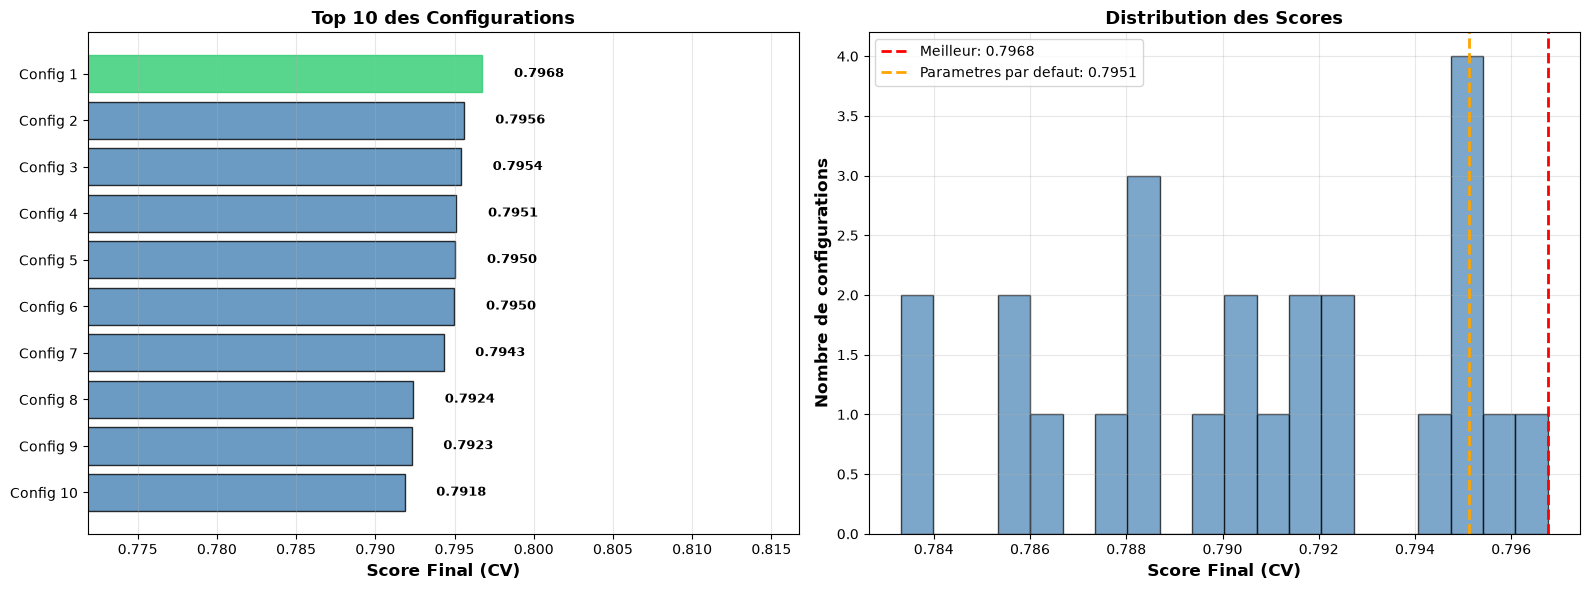


 Graphiques affiches

----------------------------------------------------------------------
                       8. MODELE FINAL OPTIMISE                       
----------------------------------------------------------------------

 Meilleur modele extrait de GridSearchCV
 Type : MLPClassifier

 EVALUATION SUR LE TEST SET :
   Metrique   Valeur Pourcentage
   Accuracy 0.771481      77.15%
     Recall 0.833544      83.35%
  Precision 0.847490      84.75%
Score Final 0.809486      80.95%

 Rappel Q4 (toutes les variables, parametres par defaut) : 0.8121

                              RESUME Q6                               

 RESULTATS :
   - 24 combinaisons testees
   - Temps d'execution : 70.6s
   - Meilleur score CV : 0.7968
   - Score sur test : 0.8095

 MEILLEURS HYPERPARAMETRES :
   - alpha = 0.0001
   - hidden_layer_sizes = (40, 20)
   - learning_rate_init = 0.01

 VARIABLE CREEE :
   - best_model_optimized : modele MLPClassifier optimise et entraine




In [11]:
print("="*70)
print("Q6 - OPTIMISATION DES HYPERPARAMETRES (GridSearchCV)".center(70))
print("="*70)

from sklearn.model_selection import GridSearchCV
import pandas as pd
import time

print("\n OBJECTIF :")
print("   Trouver les MEILLEURS hyperparametres pour maximiser les performances")
print("   du modele gagnant identifie precedemment")

# ============================================
# ETAPE 1 : IDENTIFIER LE MEILLEUR MODELE
# ============================================

print("\n" + "-"*70)
print("1. IDENTIFICATION DU MEILLEUR MODELE".center(70))
print("-"*70)

print("\n Rappel des resultats (Q2 a Q5) :")
print(f"   Meilleur modele : {best_model_name} avec Score Final = {best_score_base:.4f}")
print(f"   -> Preparation des donnees : {best_prep_strategy}")
print(f"   -> {n_optimal} variables retenues en Q5")

# Donnees : preparation retenue + variables selectionnees en Q5
X_train_q6 = X_train_prep[:, selected_features]
X_test_q6 = X_test_prep[:, selected_features]

# ============================================
# ETAPE 2 : GRILLE DE PARAMETRES
# ============================================

print("\n" + "-"*70)
print("2. DEFINITION DE LA GRILLE D'HYPERPARAMETRES".center(70))
print("-"*70)

# Une grille par type de modele
grilles = {
    'MLP (40,20)': (MLPClassifier(random_state=1, max_iter=1000), {
        'hidden_layer_sizes': [
            (20, 10),   # Petit reseau
            (40, 20),   # Reseau moyen (baseline)
            (50, 25),   # Reseau plus large
            (60, 30),   # Reseau encore plus large
        ],
        'alpha': [0.0001, 0.001, 0.01],
        'learning_rate_init': [0.001, 0.01],
    }),
    'KNN (k=5)': (KNeighborsClassifier(), {
        'n_neighbors': [3, 5, 7, 9, 11, 15],
        'weights': ['uniform', 'distance'],
        'p': [1, 2],
    }),
    'CART (Decision Tree)': (DecisionTreeClassifier(random_state=1), {
        'max_depth': [3, 5, 7, 10, None],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 5],
    }),
}

base_model, param_grid = grilles[best_model_name]

print(f"\n Hyperparametres a tester pour {best_model_name} :")

# Tableau avec pandas
df_grille = pd.DataFrame({
    'Parametre': list(param_grid.keys()),
    'Valeurs testees': [', '.join(str(v) for v in valeurs) for valeurs in param_grid.values()]
})
print("\n GRILLE DE PARAMETRES :")
print(df_grille.to_string(index=False))

n_combinations = int(np.prod([len(valeurs) for valeurs in param_grid.values()]))

print(f"\n Nombre total de combinaisons : {n_combinations}")
print(f"   Soit {n_combinations * 5} entrainements avec CV=5")

# ============================================
# ETAPE 3 : SCORER PERSONNALISE
# ============================================

print("\n" + "-"*70)
print("3. DEFINITION DU SCORER PERSONNALISE".center(70))
print("-"*70)

print("\n CRITERE D'OPTIMISATION :")
print(f"   Score Final = {LABEL_SCORE}")
print("\n Pourquoi ce critere ?")
print("   - Accuracy : Performance globale")
print(f"   - {CRITERE.capitalize()} : critere choisi en Q2 pour le credit scoring")
print("   - Moyenne : Equilibre entre les deux")

print("\n Scorer personnalise : scorer_final (defini en Q2)")

# ============================================
# ETAPE 4 : LANCER GRIDSEARCHCV
# ============================================

print("\n" + "-"*70)
print("4. LANCEMENT DE GridSearchCV".center(70))
print("-"*70)

print("\n Configuration :")
print("   - Cross-Validation : 5 folds")
print("   - Nombre de jobs : -1 (tous les CPU)")
print("   - Verbose : 1 (afficher progression)")

grid_search = GridSearchCV(
    estimator=base_model,
    param_grid=param_grid,
    scoring=scorer_final,
    cv=5,
    n_jobs=-1,
    verbose=1,
    return_train_score=True
)

print("\n Lancement de la recherche...")

start_time = time.time()
grid_search.fit(X_train_q6, y_train)
elapsed_time = time.time() - start_time

print(f"\n Recherche terminee en {elapsed_time:.1f} secondes ({elapsed_time/60:.1f} minutes)")

# ============================================
# ETAPE 5 : RESULTATS
# ============================================

print("\n" + "-"*70)
print("5. RESULTATS DE LA RECHERCHE".center(70))
print("-"*70)

best_params = grid_search.best_params_
best_score = grid_search.best_score_

print("\n MEILLEURS HYPERPARAMETRES TROUVES :")

df_params = pd.DataFrame({
    'Parametre': list(best_params.keys()),
    'Valeur': [str(v) for v in best_params.values()]
})
print(df_params.to_string(index=False))

print(f"\n MEILLEUR SCORE (CV) : {best_score:.4f}")
print(f"   (Score Final = {LABEL_SCORE})")

# Reference : modele par defaut, evalue sur les memes plis de validation croisee
baseline_cv = cross_val_score(clone(best_clf_base), X_train_q6, y_train,
                              cv=5, scoring=scorer_final, n_jobs=-1).mean()
gain = (best_score - baseline_cv) * 100

print(f"\n COMPARAISON AVEC LES PARAMETRES PAR DEFAUT (CV) :")
print(f"   Par defaut : {baseline_cv:.4f}")
print(f"   Optimise   : {best_score:.4f}")
print(f"   Ecart      : {gain:+.2f} points")

# ============================================
# ETAPE 6 : TOP 5
# ============================================

print("\n" + "-"*70)
print("6. TOP 5 DES CONFIGURATIONS TESTEES".center(70))
print("-"*70)

results_df = pd.DataFrame(grid_search.cv_results_)
results_sorted = results_df.sort_values('mean_test_score', ascending=False)

print("\n CLASSEMENT DES 5 MEILLEURES CONFIGURATIONS :\n")

for rank in range(min(5, len(results_sorted))):
    row = results_sorted.iloc[rank]

    print(f"   {'-'*60}")
    print(f"   Rang #{rank+1}  |  Score : {row['mean_test_score']:.4f} +/- {row['std_test_score']:.4f}")
    print(f"   {'-'*60}")

    params = row['params']
    for param, value in params.items():
        print(f"      - {param:20s} : {value}")

    print()

# ============================================
# ETAPE 7 : VISUALISATION
# ============================================

print("-"*70)
print("7. VISUALISATION DES RESULTATS".center(70))
print("-"*70)

print("\n Creation des graphiques...")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# GRAPHIQUE 1 : Top 10
ax1 = axes[0]

top_10 = results_sorted.head(10)
x_pos = np.arange(len(top_10))

bars = ax1.barh(x_pos, top_10['mean_test_score'],
                color='steelblue', alpha=0.8, edgecolor='black')

bars[0].set_color('#2ECC71')

for i, (idx, row) in enumerate(top_10.iterrows()):
    ax1.text(row['mean_test_score'] + 0.002, i,
             f"{row['mean_test_score']:.4f}",
             va='center', fontweight='bold', fontsize=9)

ax1.set_yticks(x_pos)
ax1.set_yticklabels([f"Config {i+1}" for i in range(len(top_10))])
ax1.set_xlim([top_10['mean_test_score'].min() - 0.02, top_10['mean_test_score'].max() + 0.02])
ax1.set_xlabel('Score Final (CV)', fontsize=12, fontweight='bold')
ax1.set_title('Top 10 des Configurations', fontsize=13, fontweight='bold')
ax1.grid(axis='x', alpha=0.3)
ax1.invert_yaxis()

# GRAPHIQUE 2 : Distribution
ax2 = axes[1]

scores = results_sorted['mean_test_score']

ax2.hist(scores, bins=20, color='steelblue', alpha=0.7, edgecolor='black')

ax2.axvline(best_score, color='red', linestyle='--', linewidth=2,
            label=f'Meilleur: {best_score:.4f}')

ax2.axvline(baseline_cv, color='orange', linestyle='--', linewidth=2,
            label=f'Parametres par defaut: {baseline_cv:.4f}')

ax2.set_xlabel('Score Final (CV)', fontsize=12, fontweight='bold')
ax2.set_ylabel('Nombre de configurations', fontsize=12, fontweight='bold')
ax2.set_title('Distribution des Scores', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

print("\n Graphiques affiches")

# ============================================
# ETAPE 8 : MODELE FINAL
# ============================================

print("\n" + "-"*70)
print("8. MODELE FINAL OPTIMISE".center(70))
print("-"*70)

best_model_optimized = grid_search.best_estimator_

print("\n Meilleur modele extrait de GridSearchCV")
print(f" Type : {type(best_model_optimized).__name__}")

print("\n EVALUATION SUR LE TEST SET :")

y_pred_optimized = best_model_optimized.predict(X_test_q6)

acc_opt = accuracy_score(y_test, y_pred_optimized)
rec_opt = recall_score(y_test, y_pred_optimized, zero_division=0)
prec_opt = precision_score(y_test, y_pred_optimized, zero_division=0)
score_final_opt = score_final(y_test, y_pred_optimized, CRITERE)

# Tableau pandas
resultats_opt = {
    'Metrique': ['Accuracy', 'Recall', 'Precision', 'Score Final'],
    'Valeur': [acc_opt, rec_opt, prec_opt, score_final_opt],
    'Pourcentage': [f"{acc_opt*100:.2f}%", f"{rec_opt*100:.2f}%",
                    f"{prec_opt*100:.2f}%", f"{score_final_opt*100:.2f}%"]
}
df_resultats_opt = pd.DataFrame(resultats_opt)
print(df_resultats_opt.to_string(index=False))

print(f"\n Rappel Q4 (toutes les variables, parametres par defaut) : {best_score_base:.4f}")

# ============================================
# RESUME FINAL
# ============================================

print("\n" + "="*70)
print("RESUME Q6".center(70))
print("="*70)

print("\n RESULTATS :")
print(f"   - {n_combinations} combinaisons testees")
print(f"   - Temps d'execution : {elapsed_time:.1f}s")
print(f"   - Meilleur score CV : {best_score:.4f}")
print(f"   - Score sur test : {score_final_opt:.4f}")

print("\n MEILLEURS HYPERPARAMETRES :")
for param, value in best_params.items():
    print(f"   - {param} = {value}")

print("\n VARIABLE CREEE :")
print(f"   - best_model_optimized : modele {type(best_model_optimized).__name__} optimise et entraine")

print("\n" + "="*70 + "\n")

### Q7. Pipeline complet

Le pipeline regroupe les décisions des questions précédentes (normalisation, ACP, sélection
de variables, modèle optimisé). Il prend en entrée les **13 variables brutes** et il est
sauvegardé dans `models/credit_scoring_pipeline.pkl`.

In [12]:
print("="*70)
print("Q7 - CREATION DU PIPELINE COMPLET".center(70))
print("="*70)

from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from utils import make_column_selector
import pandas as pd
import pickle
import time

print("\n OBJECTIF :")
print("   Creer un pipeline sklearn qui encapsule :")
print("   1. Pretraitement (normalisation, PCA)")
print("   2. Selection de features")
print("   3. Modele optimise")
print("   4. Sauvegarder en fichier pickle pour reutilisation")

# ============================================
# ETAPE 1 : RAPPEL DES DECISIONS
# ============================================

print("\n" + "-"*70)
print("1. RAPPEL DES DECISIONS PRECEDENTES".center(70))
print("-"*70)

print("\n DECISIONS BASEES SUR LES RESULTATS (Q3 a Q6) :")

# Decisions issues des questions precedentes
scaler_retenu = next((s for s in ['StandardScaler', 'MinMaxScaler'] if s in best_prep_strategy), None)
use_pca = 'ACP' in best_prep_strategy

decisions = {
    'Question': ['Normalisation ?', 'ACP ?', 'Selection features ?', 'Modele optimal', 'Hyperparametres'],
    'Decision': [
        f"OUI ({scaler_retenu})" if scaler_retenu else 'NON (donnees brutes)',
        'OUI (3 composantes ajoutees)' if use_pca else 'NON',
        f"OUI ({n_optimal} features sur {X_train_prep.shape[1]})",
        type(best_model_optimized).__name__,
        ', '.join(f"{k}={v}" for k, v in best_params.items())
    ]
}

df_decisions = pd.DataFrame(decisions)
print(df_decisions.to_string(index=False))

# ============================================
# ETAPE 2 : FONCTION create_pipeline
# ============================================

print("\n" + "-"*70)
print("2. FONCTION create_pipeline()".center(70))
print("-"*70)

def create_pipeline(scaler=None, use_pca=False, n_components=3, selected_features=None, classifier=None):
    """
    Cree un pipeline sklearn configurable

    Parametres :
    -----------
    scaler : None, 'StandardScaler' ou 'MinMaxScaler'
    use_pca : bool, ajouter n_components composantes ACP aux variables (comme en Q4)
    n_components : int, nombre de composantes PCA
    selected_features : liste des indices des variables a garder (selection Q5)
    classifier : estimator, modele de classification

    Retourne :
    ---------
    pipeline : Pipeline sklearn
    """
    if classifier is None:
        raise ValueError("Un classifier doit etre fourni !")

    steps = []

    if scaler == 'StandardScaler':
        steps.append(('scaler', StandardScaler()))
        print("   StandardScaler ajoute au pipeline")
    elif scaler == 'MinMaxScaler':
        steps.append(('scaler', MinMaxScaler()))
        print("   MinMaxScaler ajoute au pipeline")

    if use_pca:
        # Variables d'origine + composantes ACP concatenees (comme en Q4)
        steps.append(('pca', FeatureUnion([('originales', 'passthrough'),
                                           ('composantes', PCA(n_components=n_components))])))
        print(f"   PCA({n_components} composantes) ajoute au pipeline")

    if selected_features is not None:
        # Memes variables qu'en Q5 (classement par importance RandomForest)
        steps.append(('feature_selection', make_column_selector(selected_features)))
        print(f"   Selection de {len(selected_features)} features ajoutee au pipeline")

    steps.append(('classifier', classifier))
    print(f"   {type(classifier).__name__} ajoute au pipeline")

    pipeline = Pipeline(steps)
    return pipeline

print("\n Fonction create_pipeline() creee")

# ============================================
# ETAPE 3 : PIPELINE OPTIMAL
# ============================================

print("\n" + "-"*70)
print("3. CREATION DU PIPELINE OPTIMAL".center(70))
print("-"*70)

# Meme modele et memes hyperparametres qu'en Q6 (copie non entrainee)
optimal_classifier = clone(best_model_optimized)

print("\n Composants du pipeline :")

pipeline_optimal = create_pipeline(
    scaler=scaler_retenu,
    use_pca=use_pca,
    selected_features=selected_features,
    classifier=optimal_classifier
)

print("\n Pipeline optimal cree")

print("\n Structure du Pipeline :")

# Tableau pandas
structure = {
    'Etape': [f"Etape {i}" for i in range(1, len(pipeline_optimal.steps) + 1)],
    'Nom': [name for name, step in pipeline_optimal.steps],
    'Type': [type(step).__name__ for name, step in pipeline_optimal.steps]
}

df_structure = pd.DataFrame(structure)
print(df_structure.to_string(index=False))

# ============================================
# ETAPE 4 : ENTRAINEMENT
# ============================================

print("\n" + "-"*70)
print("4. ENTRAINEMENT DU PIPELINE".center(70))
print("-"*70)

print("\n Entrainement du pipeline sur les donnees brutes (X_train)...")

start_time = time.time()
pipeline_optimal.fit(X_train, y_train)
elapsed_time = time.time() - start_time

print(f"\n Pipeline entraine en {elapsed_time:.1f} secondes")

# ============================================
# ETAPE 5 : EVALUATION
# ============================================

print("\n" + "-"*70)
print("5. EVALUATION DU PIPELINE".center(70))
print("-"*70)

y_pred_pipeline = pipeline_optimal.predict(X_test)
y_proba_pipeline = pipeline_optimal.predict_proba(X_test)[:, 1]

acc_pipeline = accuracy_score(y_test, y_pred_pipeline)
rec_pipeline = recall_score(y_test, y_pred_pipeline, zero_division=0)
prec_pipeline = precision_score(y_test, y_pred_pipeline, zero_division=0)
score_final_pipeline = score_final(y_test, y_pred_pipeline, CRITERE)

print("\n RESULTATS DU PIPELINE :")

# Tableau pandas
resultats = {
    'Metrique': ['Accuracy', 'Recall', 'Precision', 'Score Final'],
    'Valeur': [acc_pipeline, rec_pipeline, prec_pipeline, score_final_pipeline],
    'Pourcentage': [f"{acc_pipeline*100:.2f}%",
                    f"{rec_pipeline*100:.2f}%",
                    f"{prec_pipeline*100:.2f}%",
                    f"{score_final_pipeline*100:.2f}%"]
}

df_resultats = pd.DataFrame(resultats)
print(df_resultats.to_string(index=False))

auc_pipeline = roc_auc_score(y_test, y_proba_pipeline)
print(f"\n AUC-ROC : {auc_pipeline:.4f}")

cm_pipeline = confusion_matrix(y_test, y_pred_pipeline)
tn_p, fp_p, fn_p, tp_p = cm_pipeline.ravel()
spec_pipeline = tn_p / (tn_p + fp_p)

# A partir des donnees brutes, le pipeline doit reproduire le modele optimise de Q6
coherent = np.isclose(score_final_pipeline, score_final_opt)
print(f"\n Verification : pipeline = {score_final_pipeline:.4f} | modele Q6 = {score_final_opt:.4f}"
      f" -> {'identiques' if coherent else 'DIFFERENTS'}")

# ============================================
# ETAPE 6 : SAUVEGARDE
# ============================================

print("\n" + "-"*70)
print("6. SAUVEGARDE DU PIPELINE".center(70))
print("-"*70)

pipeline_filename = MODELS_DIR / 'credit_scoring_pipeline.pkl'

with open(pipeline_filename, 'wb') as f:
    pickle.dump(pipeline_optimal, f)

file_size = pipeline_filename.stat().st_size / 1024

print(f"\n Pipeline sauvegarde : {pipeline_filename.relative_to(PROJECT_DIR).as_posix()} ({file_size:.1f} KB)")

# ============================================
# ETAPE 7 : TEST CHARGEMENT
# ============================================

print("\n" + "-"*70)
print("7. TEST DE CHARGEMENT".center(70))
print("-"*70)

with open(pipeline_filename, 'rb') as f:
    pipeline_loaded = pickle.load(f)

print("\n Pipeline charge avec succes")
print("\n Test sur 3 individus :")

for i in range(3):
    y_true = y_test[i]
    y_pred = pipeline_loaded.predict(X_test[i:i+1])[0]
    match = "OK" if y_pred == y_true else "ERREUR"
    print(f"   Individu {i+1} : Vrai={y_true}, Predit={y_pred} [{match}]")

identique = np.array_equal(pipeline_loaded.predict(X_test), y_pred_pipeline)
print(f"\n Predictions du pipeline recharge identiques a l'original : {'OUI' if identique else 'NON'}")

# ============================================
# RESUME FINAL
# ============================================

print("\n" + "="*70)
print("RESUME Q7".center(70))
print("="*70)

print("\n RESULTATS :")
print(f"   - Score Final : {score_final_pipeline:.4f} ({score_final_pipeline*100:.2f}%)")
print(f"   - Precision : {prec_pipeline:.2%} des credits accordes vont a de bons clients")
print(f"   - Recall : {rec_pipeline:.2%} des bons clients obtiennent leur credit")
print(f"   - Specificite : {spec_pipeline:.2%} des defaillants sont refuses")
print(f"   - Fichier : {pipeline_filename.name} ({file_size:.1f} KB)")
print(f"   - Rechargement : {'OK' if identique else 'PROBLEME'}")

print("\n" + "="*70 + "\n")

                  Q7 - CREATION DU PIPELINE COMPLET                   

 OBJECTIF :
   Creer un pipeline sklearn qui encapsule :
   1. Pretraitement (normalisation, PCA)
   2. Selection de features
   3. Modele optimise
   4. Sauvegarder en fichier pickle pour reutilisation

----------------------------------------------------------------------
                 1. RAPPEL DES DECISIONS PRECEDENTES                  
----------------------------------------------------------------------

 DECISIONS BASEES SUR LES RESULTATS (Q3 a Q6) :
            Question                                                           Decision
     Normalisation ?                                                 OUI (MinMaxScaler)
               ACP ?                                                                NON
Selection features ?                                            OUI (8 features sur 13)
      Modele optimal                                                      MLPClassifier
     Hyperparametres a


 Pipeline entraine en 1.6 secondes

----------------------------------------------------------------------
                      5. EVALUATION DU PIPELINE                       
----------------------------------------------------------------------

 RESULTATS DU PIPELINE :
   Metrique   Valeur Pourcentage
   Accuracy 0.771481      77.15%
     Recall 0.833544      83.35%
  Precision 0.847490      84.75%
Score Final 0.809486      80.95%

 AUC-ROC : 0.8130

 Verification : pipeline = 0.8095 | modele Q6 = 0.8095 -> identiques

----------------------------------------------------------------------
                      6. SAUVEGARDE DU PIPELINE                       
----------------------------------------------------------------------

 Pipeline sauvegarde : models/credit_scoring_pipeline.pkl (51.5 KB)

----------------------------------------------------------------------
                        7. TEST DE CHARGEMENT                         
--------------------------------------------

### Q8. Orchestration automatique – `src/utils.py`

La fonction `pipeline_generation_train_test_split()` est définie dans `src/utils.py`.
Elle enchaîne automatiquement les étapes Q1 → Q7 (découpage, comparaison des modèles,
normalisation, sélection de variables, GridSearch, pipeline) avec le même critère (`CRITERE`)
et sauvegarde le pipeline dans `models/final_pipeline_auto.pkl`, utilisé par l'API (Q9).

                     Q8 - ORCHESTRATION COMPLETE                      

 OBJECTIF :
   Utiliser la fonction d'orchestration depuis utils.py
   Cette fonction fait TOUT automatiquement :
   1. Train/test split
   2. Comparaison modeles
   3. Test normalisation
   4. Selection features
   5. Optimisation hyperparametres
   6. Creation pipeline
   7. Sauvegarde pickle

----------------------------------------------------------------------
                        IMPORT DEPUIS utils.py                        
----------------------------------------------------------------------

 Fonction importee avec succes !

----------------------------------------------------------------------
                    LANCEMENT DU WORKFLOW COMPLET                     
----------------------------------------------------------------------

 Demarrage...

                    DEMARRAGE DU WORKFLOW COMPLET                     

                   ETAPE 1/7 : DIVISION TRAIN/TEST                    

 Split eff

   MLP (40,20)          : 0.7296

 Meilleur : Decision Tree (0.7571)


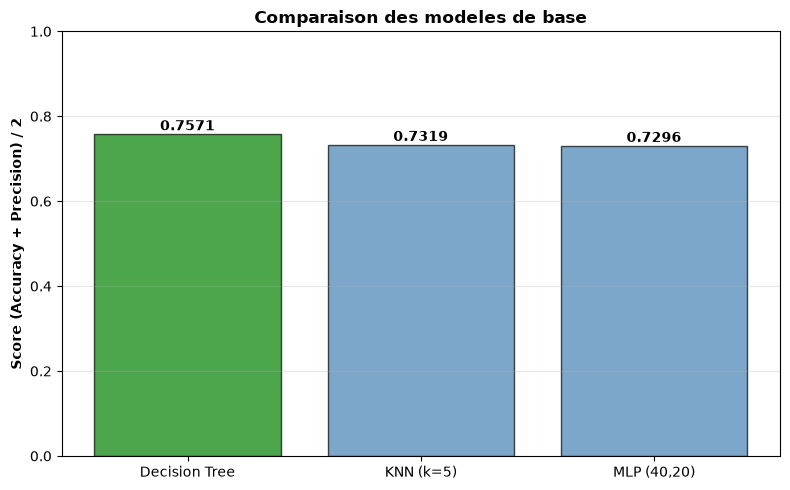


                    ETAPE 3/7 : TEST NORMALISATION                    

   Sans normalisation : 0.7571
   Avec normalisation : 0.7587

   Decision : AVEC normalisation

                    ETAPE 4/7 : SELECTION FEATURES                    



   Top 3 features : [8, 0, 12]
   Optimal : 12 features (acc=0.7070)

               ETAPE 5/7 : OPTIMISATION HYPERPARAMETRES               

   GridSearch en cours...


   Meilleurs params : {'max_depth': 5, 'min_samples_split': 2}
   Score CV : 0.7772

                    ETAPE 6/7 : CREATION PIPELINE                     
   - StandardScaler ajoute
   - Selection des 12 variables les plus importantes ajoutee
   - DecisionTreeClassifier ajoute

   Pipeline cree avec 3 etapes

                 ETAPE 7/7 : SAUVEGARDE ET EVALUATION                 

 SCORES FINAUX :
   Accuracy  : 0.7619 (76.19%)
   Recall    : 0.8867 (88.67%)
   Precision : 0.8038 (80.38%)
   Score Final : 0.7828 (78.28%)

 Pipeline sauvegarde : models/final_pipeline_auto.pkl (7.4 KB)

                    WORKFLOW TERMINE AVEC SUCCES !                    


                             RESUME FINAL                             


             Parametre                         Valeur
               Critere     (Accuracy + Precision) / 2
       Meilleur modele                  Decision Tree
         Normalisation                            OUI
Features selectionnees                        

In [13]:
# ==============================================================================
# Q8 - ORCHESTRATION COMPLETE
# ==============================================================================

print("="*70)
print("Q8 - ORCHESTRATION COMPLETE".center(70))
print("="*70)

print("\n OBJECTIF :")
print("   Utiliser la fonction d'orchestration depuis utils.py")
print("   Cette fonction fait TOUT automatiquement :")
print("   1. Train/test split")
print("   2. Comparaison modeles")
print("   3. Test normalisation")
print("   4. Selection features")
print("   5. Optimisation hyperparametres")
print("   6. Creation pipeline")
print("   7. Sauvegarde pickle")

# ==============================================================================
# IMPORT DE LA FONCTION
# ==============================================================================

print("\n" + "-"*70)
print("IMPORT DEPUIS utils.py".center(70))
print("-"*70)

# src/ a été ajouté au chemin Python dans la cellule de configuration
from utils import pipeline_generation_train_test_split

print("\n Fonction importee avec succes !")

# ==============================================================================
# TEST DE LA FONCTION
# ==============================================================================

print("\n" + "-"*70)
print("LANCEMENT DU WORKFLOW COMPLET".center(70))
print("-"*70)

print("\n Demarrage...")

final_pipeline, workflow_results = pipeline_generation_train_test_split(
    X, y,
    test_size=0.5,
    random_state=1,
    critere=CRITERE,
    models_dir=MODELS_DIR,
    verbose=True
)

# ==============================================================================
# RESUME FINAL
# ==============================================================================

print("\n\n" + "="*70)
print("RESUME FINAL".center(70))
print("="*70)

import pandas as pd

resume_data = {
    'Parametre': [
        'Critere',
        'Meilleur modele',
        'Normalisation',
        'Features selectionnees',
        'Score final',
        'Precision finale',
        'Recall final',
        'Fichier sauvegarde'
    ],
    'Valeur': [
        LABEL_SCORE,
        workflow_results['best_model_base'],
        'OUI' if workflow_results['use_normalization'] else 'NON',
        f"{workflow_results['n_features_optimal']}/{X.shape[1]}",
        f"{workflow_results['final_scores']['score_final']:.4f}",
        f"{workflow_results['final_scores']['precision']:.4f}",
        f"{workflow_results['final_scores']['recall']:.4f}",
        f"models/{Path(workflow_results['pipeline_path']).name}"
    ]
}

df_resume = pd.DataFrame(resume_data)
print("\n")
print(df_resume.to_string(index=False))

print("\n" + "="*70)
print("FIN DE Q8".center(70))
print("="*70 + "\n")

             3. CREATION DE LA FONCTION DE VISUALISATION              
----------------------------------------------------------------------

Fonction visualize_workflow_results() creee !

----------------------------------------------------------------------
               4. TEST DE LA FONCTION DE VISUALISATION                
----------------------------------------------------------------------

Affichage des graphiques du workflow...


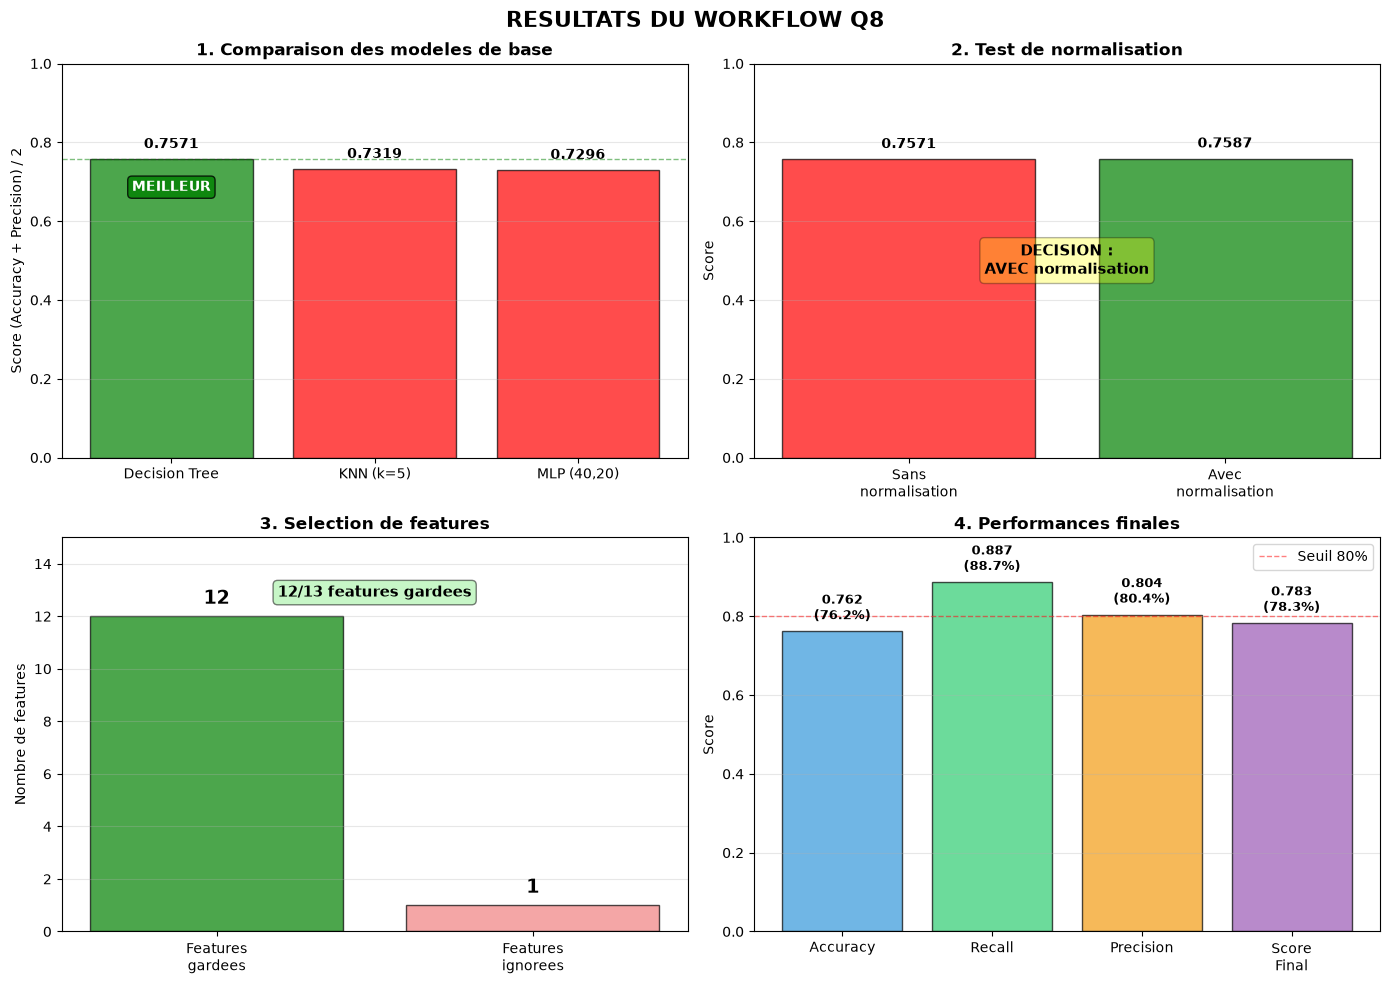


Graphiques affiches avec succes !


In [14]:
# FONCTION DE VISUALISATION (c'est une fonction optionnelle mais c'est juste pour voir les resultats )



print("3. CREATION DE LA FONCTION DE VISUALISATION".center(70))
print("-"*70)

def visualize_workflow_results(results):
    """
    Visualise les resultats du workflow Q8

    Parametres :
    -----------
    results : dict
        Dictionnaire retourne par pipeline_generation_train_test_split()

    Affiche :
    ---------
    4 graphiques :
    1. Comparaison des modeles de base
    2. Test de normalisation
    3. Selection de features
    4. Performances finales
    """
    import matplotlib.pyplot as plt

    # Creer la figure avec 4 sous-graphiques
    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    fig.suptitle('RESULTATS DU WORKFLOW Q8', fontsize=16, fontweight='bold')


    # GRAPHIQUE 1 : COMPARAISON MODELES

    ax1 = axes[0, 0]

    models = list(results['scores_base'].keys())
    scores = list(results['scores_base'].values())
    colors_models = ['red' if s < max(scores) else 'green' for s in scores]

    bars1 = ax1.bar(models, scores, color=colors_models, alpha=0.7, edgecolor='black')
    ax1.set_title("1. Comparaison des modeles de base", fontweight='bold')
    ax1.set_ylabel(f"Score {LABEL_SCORE}")
    ax1.set_ylim(0, 1)
    ax1.axhline(y=max(scores), color='green', linestyle='--', linewidth=1, alpha=0.5)
    ax1.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs sur les barres
    for i, (bar, score) in enumerate(zip(bars1, scores)):
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{score:.4f}',
                ha='center', va='bottom', fontweight='bold')

    # Indiquer le meilleur
    best_idx = scores.index(max(scores))
    ax1.text(best_idx, max(scores) - 0.08, 'MEILLEUR',
            ha='center', fontweight='bold', color='white',
            bbox=dict(boxstyle='round', facecolor='green', alpha=0.8))


    # GRAPHIQUE 2 : TEST NORMALISATION

    ax2 = axes[0, 1]

    score_sans = results['scores_base'][results['best_model_base']]
    score_avec = results.get('score_normalized', 0)

    norm_labels = ['Sans\nnormalisation', 'Avec\nnormalisation']
    norm_scores = [score_sans, score_avec]

    # Couleur selon decision
    if results['use_normalization']:
        colors_norm = ['red', 'green']
        decision = 'AVEC normalisation'
    else:
        colors_norm = ['green', 'red']
        decision = 'SANS normalisation'

    bars2 = ax2.bar(norm_labels, norm_scores, color=colors_norm, alpha=0.7, edgecolor='black')
    ax2.set_title("2. Test de normalisation", fontweight='bold')
    ax2.set_ylabel("Score")
    ax2.set_ylim(0, 1)
    ax2.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs
    for bar, score in zip(bars2, norm_scores):
        height = bar.get_height()
        ax2.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{score:.4f}',
                ha='center', va='bottom', fontweight='bold')

    # Afficher la decision
    ax2.text(0.5, 0.5, f'DECISION :\n{decision}',
            transform=ax2.transAxes,
            ha='center', va='center',
            fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='yellow', alpha=0.3))


    # GRAPHIQUE 3 : SELECTION FEATURES

    ax3 = axes[1, 0]

    n_features_optimal = results['n_features_optimal']
    n_features_total = len(results['sorted_features'])
    n_features_ignores = n_features_total - n_features_optimal

    feature_labels = ['Features\ngardees', 'Features\nignorees']
    feature_counts = [n_features_optimal, n_features_ignores]
    colors_features = ['green', 'lightcoral']

    bars3 = ax3.bar(feature_labels, feature_counts, color=colors_features, alpha=0.7, edgecolor='black')
    ax3.set_title("3. Selection de features", fontweight='bold')
    ax3.set_ylabel("Nombre de features")
    ax3.set_ylim(0, n_features_total + 2)
    ax3.grid(axis='y', alpha=0.3)

    # Ajouter les valeurs
    for bar, count in zip(bars3, feature_counts):
        height = bar.get_height()
        ax3.text(bar.get_x() + bar.get_width()/2., height + 0.3,
                f'{int(count)}',
                ha='center', va='bottom', fontweight='bold', fontsize=14)

    # Afficher le ratio
    ax3.text(0.5, 0.85, f'{n_features_optimal}/{n_features_total} features gardees',
            transform=ax3.transAxes,
            ha='center', fontsize=11, fontweight='bold',
            bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.5))


    # GRAPHIQUE 4 : PERFORMANCES FINALES

    ax4 = axes[1, 1]

    final = results['final_scores']
    metric_names = ['Accuracy', 'Recall', 'Precision', 'Score\nFinal']
    metric_values = [final['accuracy'], final['recall'],
                    final['precision'], final['score_final']]
    colors_metrics = ['#3498db', '#2ecc71', '#f39c12', '#9b59b6']

    bars4 = ax4.bar(metric_names, metric_values, color=colors_metrics, alpha=0.7, edgecolor='black')
    ax4.set_title("4. Performances finales", fontweight='bold')
    ax4.set_ylabel("Score")
    ax4.set_ylim(0, 1)
    ax4.axhline(y=0.8, color='red', linestyle='--', linewidth=1, alpha=0.5, label='Seuil 80%')
    ax4.grid(axis='y', alpha=0.3)
    ax4.legend(loc='upper right')

    # Ajouter les valeurs
    for bar, value in zip(bars4, metric_values):
        height = bar.get_height()
        ax4.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{value:.3f}\n({value*100:.1f}%)',
                ha='center', va='bottom', fontweight='bold', fontsize=9)

    # Mise en forme finale
    plt.tight_layout()
    plt.show()

    print("\nGraphiques affiches avec succes !")

print("\nFonction visualize_workflow_results() creee !")


# TEST DE LA FONCTION DE VISUALISATION


print("\n" + "-"*70)
print("4. TEST DE LA FONCTION DE VISUALISATION".center(70))
print("-"*70)

print("\nAffichage des graphiques du workflow...")

# Appeler la fonction de visualisation
visualize_workflow_results(workflow_results)

### Q9. API FastAPI – `src/api.py`

*(Partie de Sarah)*

L'API charge `models/final_pipeline_auto.pkl` (Q8) et expose `/predict/`, `/predict_batch/`
et `/health/`. Pour la lancer depuis un terminal, à la racine du projet :

```bash
python -m uvicorn api:app --app-dir src --reload
```

Documentation interactive : <http://127.0.0.1:8000/docs>. Ci-dessous, l'API est lancée en
arrière-plan depuis le notebook puis testée.

In [15]:
# ==============================================================================
# SECTION 1 : VÉRIFICATION DE L'ENVIRONNEMENT
# ==============================================================================

print("="*70)
print("VÉRIFICATION DE L'ENVIRONNEMENT".center(70))
print("="*70)

# Vérifier que les variables existent
try:
    print(f"\n X_train: {X_train.shape}")
    print(f" X_test: {X_test.shape}")
    print(f" y_train: {y_train.shape}")
    print(f" y_test: {y_test.shape}")
    print(f" X: {X.shape}")
    print(f" y: {y.shape}")
    print(f" feature_names: {len(feature_names)} features")
except NameError as e:
    print(f" ERREUR: Variables manquantes!")
    print(f"   Vous devez d'abord exécuter les parties Q1-Q8")
    print(f"   Variable manquante: {e}")
    raise

# Vérifier que le pipeline utilisé par l'API existe (créé en Q8)
pipeline_path = MODELS_DIR / 'final_pipeline_auto.pkl'
if pipeline_path.exists():
    print(f"\n Pipeline trouvé: {pipeline_path.relative_to(PROJECT_DIR).as_posix()}")
else:
    print(f"\n  Pipeline non trouvé: {pipeline_path.relative_to(PROJECT_DIR).as_posix()}")
    print(f"   Exécutez d'abord la Q8 (orchestration) pour le créer")

print("\n" + "="*70)
print(" ENVIRONNEMENT PRÊT".center(70))
print("="*70)

                   VÉRIFICATION DE L'ENVIRONNEMENT                    

 X_train: (2187, 13)
 X_test: (2188, 13)
 y_train: (2187,)
 y_test: (2188,)
 X: (4375, 13)
 y: (4375,)
 feature_names: 13 features

 Pipeline trouvé: models/final_pipeline_auto.pkl

                          ENVIRONNEMENT PRÊT                          


In [16]:
# -----------------------------------------------------------------------------
# LANCER L'API (en arrière-plan depuis le notebook)
# -----------------------------------------------------------------------------

print("\n Lancement de l'API...")

import socket
import threading
import time
import requests
import uvicorn

import api  # src/api.py : charge models/final_pipeline_auto.pkl

# Port 8000 s'il est libre, sinon un autre port libre
with socket.socket() as s:
    try:
        s.bind(('127.0.0.1', 8000))
    except OSError:
        s.bind(('127.0.0.1', 0))
    API_PORT = s.getsockname()[1]

API_URL = f"http://127.0.0.1:{API_PORT}"

api_server = uvicorn.Server(uvicorn.Config(api.app, host='127.0.0.1', port=API_PORT,
                                           log_level='warning'))
api_thread = threading.Thread(target=api_server.run, daemon=True)
api_thread.start()

# Attendre que l'API réponde (30 s maximum)
for _ in range(60):
    try:
        requests.get(f"{API_URL}/health/", timeout=1)
        break
    except requests.RequestException:
        time.sleep(0.5)
else:
    raise RuntimeError("L'API n'a pas démarré")

print(f" API lancée sur {API_URL}")
print(f" Documentation: {API_URL}/docs")


 Lancement de l'API...


 API lancée sur http://127.0.0.1:8000
 Documentation: http://127.0.0.1:8000/docs


In [17]:
# -----------------------------------------------------------------------------
# 4. TESTER L'API
# -----------------------------------------------------------------------------

print("\n" + "="*70)
print("TEST DE L'API".center(70))
print("="*70)

import requests
import json

# API_URL est défini dans la cellule précédente (lancement de l'API)

# TEST 1: Health check
print("\n TEST 1: Health Check")
print("-"*70)
try:
    r = requests.get(f"{API_URL}/health/", timeout=5)
    print(f"Status: {r.status_code}")
    print(json.dumps(r.json(), indent=2))
except Exception as e:
    print(f" Erreur: {e}")

# TEST 2: Prédiction individuelle
print("\n TEST 2: Prédiction Individuelle")
print("-"*70)

client_test = {
    "seniority": 9.0, "home": 1.0, "time": 60.0, "age": 30.0,
    "marital": 2.0, "records": 0.0, "job": 3.0, "expenses": 73.0,
    "income": 129.0, "assets": 0.0, "debt": 0.0,
    "amount": 800.0, "price": 846.0
}

print(f"Client: Âge={client_test['age']}, Revenu={client_test['income']}, Dette={client_test['debt']}")

try:
    r = requests.post(f"{API_URL}/predict/", json=client_test, timeout=5)
    result = r.json()
    print(f"\n Résultat:")
    print(f"  • {result['decision']}")
    print(f"  • Probabilité d'accord: {result['probabilite_accord']:.2%}")
    print(f"  • Confiance: {result['confiance']:.2%}")
except Exception as e:
    print(f" Erreur: {e}")

# TEST 3: Batch (3 individus du test set)
print("\nTEST 3: Prédiction Batch (3 individus)")
print("-"*70)

clients_batch = []
for i in range(3):
    client = {
        "seniority": float(X_test[i, 0]),
        "home": float(X_test[i, 1]),
        "time": float(X_test[i, 2]),
        "age": float(X_test[i, 3]),
        "marital": float(X_test[i, 4]),
        "records": float(X_test[i, 5]),
        "job": float(X_test[i, 6]),
        "expenses": float(X_test[i, 7]),
        "income": float(X_test[i, 8]),
        "assets": float(X_test[i, 9]),
        "debt": float(X_test[i, 10]),
        "amount": float(X_test[i, 11]),
        "price": float(X_test[i, 12])
    }
    clients_batch.append(client)

try:
    r = requests.post(f"{API_URL}/predict_batch/", json=clients_batch, timeout=10)
    result = r.json()

    print(f"\n Résultats:")
    print(f"  • Total: {result['total']}")
    print(f"  • Accordés: {result['accordes']}")
    print(f"  • Taux: {result['taux_acceptation']}")

    print(f"\n  Détails:")
    for pred in result['predictions']:
        vrai = y_test[pred['client_id']-1]
        match = "True" if pred['prediction'] == vrai else "False"
        print(f"    Client {pred['client_id']}: {pred['decision']} (vrai={vrai}) {match}")

except Exception as e:
    print(f" Erreur: {e}")

print("\n" + "="*70)
print(" Q9 TERMINÉE".center(70))
print("="*70)


                            TEST DE L'API                             

 TEST 1: Health Check
----------------------------------------------------------------------
Status: 200
{
  "status": "healthy",
  "pipeline_file": "final_pipeline_auto.pkl",
  "pipeline_type": "<class 'sklearn.pipeline.Pipeline'>",
  "pipeline_steps": [
    "scaler",
    "feature_selection",
    "classifier"
  ]
}

 TEST 2: Prédiction Individuelle
----------------------------------------------------------------------
Client: Âge=30.0, Revenu=129.0, Dette=0.0

 Résultat:
  • CRÉDIT ACCORDÉ
  • Probabilité d'accord: 98.13%
  • Confiance: 98.13%

TEST 3: Prédiction Batch (3 individus)
----------------------------------------------------------------------

 Résultats:
  • Total: 3
  • Accordés: 3
  • Taux: 100.0%

  Détails:
    Client 1: CRÉDIT ACCORDÉ (vrai=1) True
    Client 2: CRÉDIT ACCORDÉ (vrai=0) False
    Client 3: CRÉDIT ACCORDÉ (vrai=1) True

                              Q9 TERMINÉE                      

### Q10. Validation croisée et comparaison d'algorithmes

Validation croisée 10 plis sur les 4375 individus pour 8 algorithmes et 3 préparations des
données. La normalisation et l'ACP sont placées dans un pipeline : elles sont ré-apprises sur
chaque pli d'entraînement (pas de fuite d'information vers le pli de test). Le meilleur
algorithme est ensuite optimisé et sauvegardé dans `models/final_pipeline_cv.pkl`.

In [18]:
# ==============================================================================
# Q10 - VALIDATION CROISÉE
# ==============================================================================

print("\n\n" + "="*70)
print("Q10 - VALIDATION CROISÉE (10-FOLD CV)".center(70))
print("="*70)

import numpy as np
import pandas as pd
import time
from sklearn.model_selection import KFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.base import clone
import matplotlib.pyplot as plt
from xgboost import XGBClassifier



                Q10 - VALIDATION CROISÉE (10-FOLD CV)                 


In [19]:
# -----------------------------------------------------------------------------
# FONCTION run_classifiers_cv()
# -----------------------------------------------------------------------------

def run_classifiers_cv(clfs_dict, X, Y, preprocessing=None, n_folds=10, random_state=0, verbose=True):
    """
    Compare plusieurs classifieurs avec validation croisée

    preprocessing : liste d'étapes (nom, transformer) appliquées avant chaque classifieur.
    Elles sont placées dans un Pipeline, donc ré-apprises sur chaque pli d'entraînement.
    """

    if verbose:
        print(f"\n  Configuration: {n_folds}-Fold CV, {len(clfs_dict)} algorithmes")
        print(f"   Dataset: {X.shape[0]} samples × {X.shape[1]} features")
        if preprocessing:
            print(f"   Prétraitement (dans chaque pli): {' -> '.join(name for name, _ in preprocessing)}")
        print()

    kf = KFold(n_splits=n_folds, shuffle=True, random_state=random_state)

    # Les 3 métriques sont calculées en une seule validation croisée
    scoring = {'accuracy': 'accuracy', 'auc': 'roc_auc', 'score': scorer_final}

    results = []

    for i, (name, clf) in enumerate(clfs_dict.items(), 1):
        if verbose:
            print(f"[{i}/{len(clfs_dict)}] {name}...")

        if preprocessing:
            estimator = Pipeline([(step, clone(t)) for step, t in preprocessing] + [('classifier', clf)])
        else:
            estimator = clf

        start = time.time()

        try:
            cv = cross_validate(estimator, X, Y, cv=kf, scoring=scoring, n_jobs=-1)
            cv_acc, cv_auc, cv_custom = cv['test_accuracy'], cv['test_auc'], cv['test_score']

            elapsed = time.time() - start

            results.append({
                'Algorithme': name,
                'Accuracy_mean': np.mean(cv_acc),
                'Accuracy_std': np.std(cv_acc),
                'AUC_mean': np.mean(cv_auc),
                'AUC_std': np.std(cv_auc),
                'Score_mean': np.mean(cv_custom),
                'Score_std': np.std(cv_custom),
                'Temps_sec': elapsed
            })

            if verbose:
                print(f"  ✓ Acc: {np.mean(cv_acc):.4f}±{np.std(cv_acc):.4f} | "
                      f"AUC: {np.mean(cv_auc):.4f}±{np.std(cv_auc):.4f} | "
                      f"Score: {np.mean(cv_custom):.4f}±{np.std(cv_custom):.4f} | "
                      f"{elapsed:.1f}s\n")
        except Exception as e:
            if verbose:
                print(f"  Erreur: {e}\n")

    df = pd.DataFrame(results).sort_values('Score_mean', ascending=False)
    df['Rang'] = range(1, len(df)+1)

    if verbose:
        print("\n" + "="*70)
        print("RÉSULTATS".center(70))
        print("="*70 + "\n")
        print(df.to_string(index=False))

        print("\n TOP 3:")
        for i in range(min(3, len(df))):
            row = df.iloc[i]
            print(f"\n  {['1','2','3'][i]} {row['Algorithme']}")
            print(f"     Score: {row['Score_mean']:.4f}±{row['Score_std']:.4f}")

    return df

In [20]:
# -----------------------------------------------------------------------------
# TESTS SUR 3 CONFIGURATIONS
# -----------------------------------------------------------------------------

print("\n Définition des algorithmes...")

clfs = {
    'CART': DecisionTreeClassifier(random_state=1),
    'Decision Stump': DecisionTreeClassifier(max_depth=1, random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'MLP (20,10)': MLPClassifier(hidden_layer_sizes=(20,10), random_state=1, max_iter=1000),
    'Bagging (200)': BaggingClassifier(n_estimators=200, random_state=1),
    'AdaBoost (200)': AdaBoostClassifier(n_estimators=200, random_state=1),
    'Random Forest (200)': RandomForestClassifier(n_estimators=200, random_state=1),
    'XGBoost (200)': XGBClassifier(n_estimators=200, random_state=1, eval_metric='logloss')
}

print(f" {len(clfs)} algorithmes définis\n")

# CONFIG 1: Données brutes
print("="*70)
print("CONFIG 1/3: DONNÉES BRUTES".center(70))
print("="*70)
results_brut = run_classifiers_cv(clfs, X, y)

# CONFIG 2: StandardScaler
print("\n\n" + "="*70)
print("CONFIG 2/3: STANDARDSCALER".center(70))
print("="*70)

from sklearn.preprocessing import StandardScaler
# Le scaler est appris dans chaque pli (pipeline), pas sur tout X
prep_scaled = [('scaler', StandardScaler())]
results_scaled = run_classifiers_cv(clfs, X, y, preprocessing=prep_scaled)

# CONFIG 3: StandardScaler + ACP
print("\n\n" + "="*70)
print("CONFIG 3/3: STANDARDSCALER + ACP".center(70))
print("="*70)

from sklearn.decomposition import PCA
# Variables normalisées + 3 composantes ACP (comme en Q4), apprises dans chaque pli
prep_pca = [('scaler', StandardScaler()),
            ('acp', FeatureUnion([('originales', 'passthrough'),
                                  ('composantes', PCA(n_components=3))]))]
results_pca = run_classifiers_cv(clfs, X, y, preprocessing=prep_pca)

# Prétraitement associé à chaque configuration (réutilisé pour le pipeline final)
preprocessings = {'Brut': [], 'StandardScaler': prep_scaled, 'StandardScaler+ACP': prep_pca}


 Définition des algorithmes...
 8 algorithmes définis

                      CONFIG 1/3: DONNÉES BRUTES                      

  Configuration: 10-Fold CV, 8 algorithmes
   Dataset: 4375 samples × 13 features

[1/8] CART...


  ✓ Acc: 0.7269±0.0252 | AUC: 0.6556±0.0318 | Score: 0.7673±0.0216 | 0.3s

[2/8] Decision Stump...
  ✓ Acc: 0.7221±0.0184 | AUC: 0.6181±0.0283 | Score: 0.7310±0.0191 | 0.1s

[3/8] KNN (k=5)...
  ✓ Acc: 0.7152±0.0170 | AUC: 0.6622±0.0271 | Score: 0.7411±0.0171 | 0.1s

[4/8] MLP (20,10)...


  ✓ Acc: 0.6880±0.0712 | AUC: 0.7145±0.0567 | Score: 0.7454±0.0387 | 3.0s

[5/8] Bagging (200)...


  ✓ Acc: 0.7819±0.0149 | AUC: 0.8234±0.0204 | Score: 0.8036±0.0143 | 10.7s

[6/8] AdaBoost (200)...


  ✓ Acc: 0.7959±0.0151 | AUC: 0.8325±0.0159 | Score: 0.8100±0.0142 | 3.2s

[7/8] Random Forest (200)...


...

  ✓ Acc: 0.7813±0.0212 | AUC: 0.8213±0.0197 | Score: 0.8053±0.0154 | 25.4s

[5/8] Bagging (200)...


  ✓ Acc: 0.7776±0.0136 | AUC: 0.8227±0.0162 | Score: 0.7994±0.0118 | 15.9s

[6/8] AdaBoost (200)...


  ✓ Acc: 0.7938±0.0159 | AUC: 0.8314±0.0157 | Score: 0.8086±0.0148 | 4.2s

[7/8] Random Forest (200)...


  ✓ Acc: 0.7831±0.0136 | AUC: 0.8286±0.0173 | Score: 0.7992±0.0135 | 5.6s

[8/8] XGBoost (200)...


  ✓ Acc: 0.7824±0.0176 | AUC: 0.8085±0.0201 | Score: 0.8061±0.0148 | 2.8s


                              RÉSULTATS                               

         Algorithme  Accuracy_mean  Accuracy_std  AUC_mean  AUC_std  Score_mean  Score_std  Temps_sec  Rang
     AdaBoost (200)       0.793825      0.015878  0.831391 0.015742    0.808551   0.014822   4.237637     1
      XGBoost (200)       0.782400      0.017600  0.808495 0.020071    0.806066   0.014836   2.813425     2
        MLP (20,10)       0.781261      0.021169  0.821343 0.019666    0.805265   0.015390  25.438788     3
      Bagging (200)       0.777596      0.013627  0.822701 0.016205    0.799387   0.011768  15.937451     4
Random Forest (200)       0.783085      0.013626  0.828590 0.017306    0.799209   0.013523   5.612910     5
          KNN (k=5)       0.764799      0.019294  0.763129 0.027776    0.790579   0.017189   0.516659     6
               CART       0.717704      0.017878  0.649047 0.018950    0.761178   0.016815   0.1

In [21]:
# -----------------------------------------------------------------------------
# COMPARAISON GLOBALE
# -----------------------------------------------------------------------------

print("\n\n" + "="*70)
print("COMPARAISON GLOBALE".center(70))
print("="*70)

configs = ['Brut', 'StandardScaler', 'StandardScaler+ACP']
all_results = [results_brut, results_scaled, results_pca]

comparison = []
for config, df in zip(configs, all_results):
    best = df.iloc[0]
    comparison.append({
        'Config': config,
        'Algo': best['Algorithme'],
        'Score': f"{best['Score_mean']:.4f}"
    })

print("\n" + pd.DataFrame(comparison).to_string(index=False))

# Trouver le meilleur global
best_score = -1
best_config = None
best_algo = None

for config, df in zip(configs, all_results):
    score = df.iloc[0]['Score_mean']
    if score > best_score:
        best_score = score
        best_config = config
        best_algo = df.iloc[0]['Algorithme']

print(f"\n MEILLEUR:")
print(f"   Config: {best_config}")
print(f"   Algo: {best_algo}")
print(f"   Score: {best_score:.4f}")



                         COMPARAISON GLOBALE                          

            Config           Algo  Score
              Brut AdaBoost (200) 0.8100
    StandardScaler AdaBoost (200) 0.8100
StandardScaler+ACP AdaBoost (200) 0.8086

 MEILLEUR:
   Config: Brut
   Algo: AdaBoost (200)
   Score: 0.8100



 Génération des graphiques...


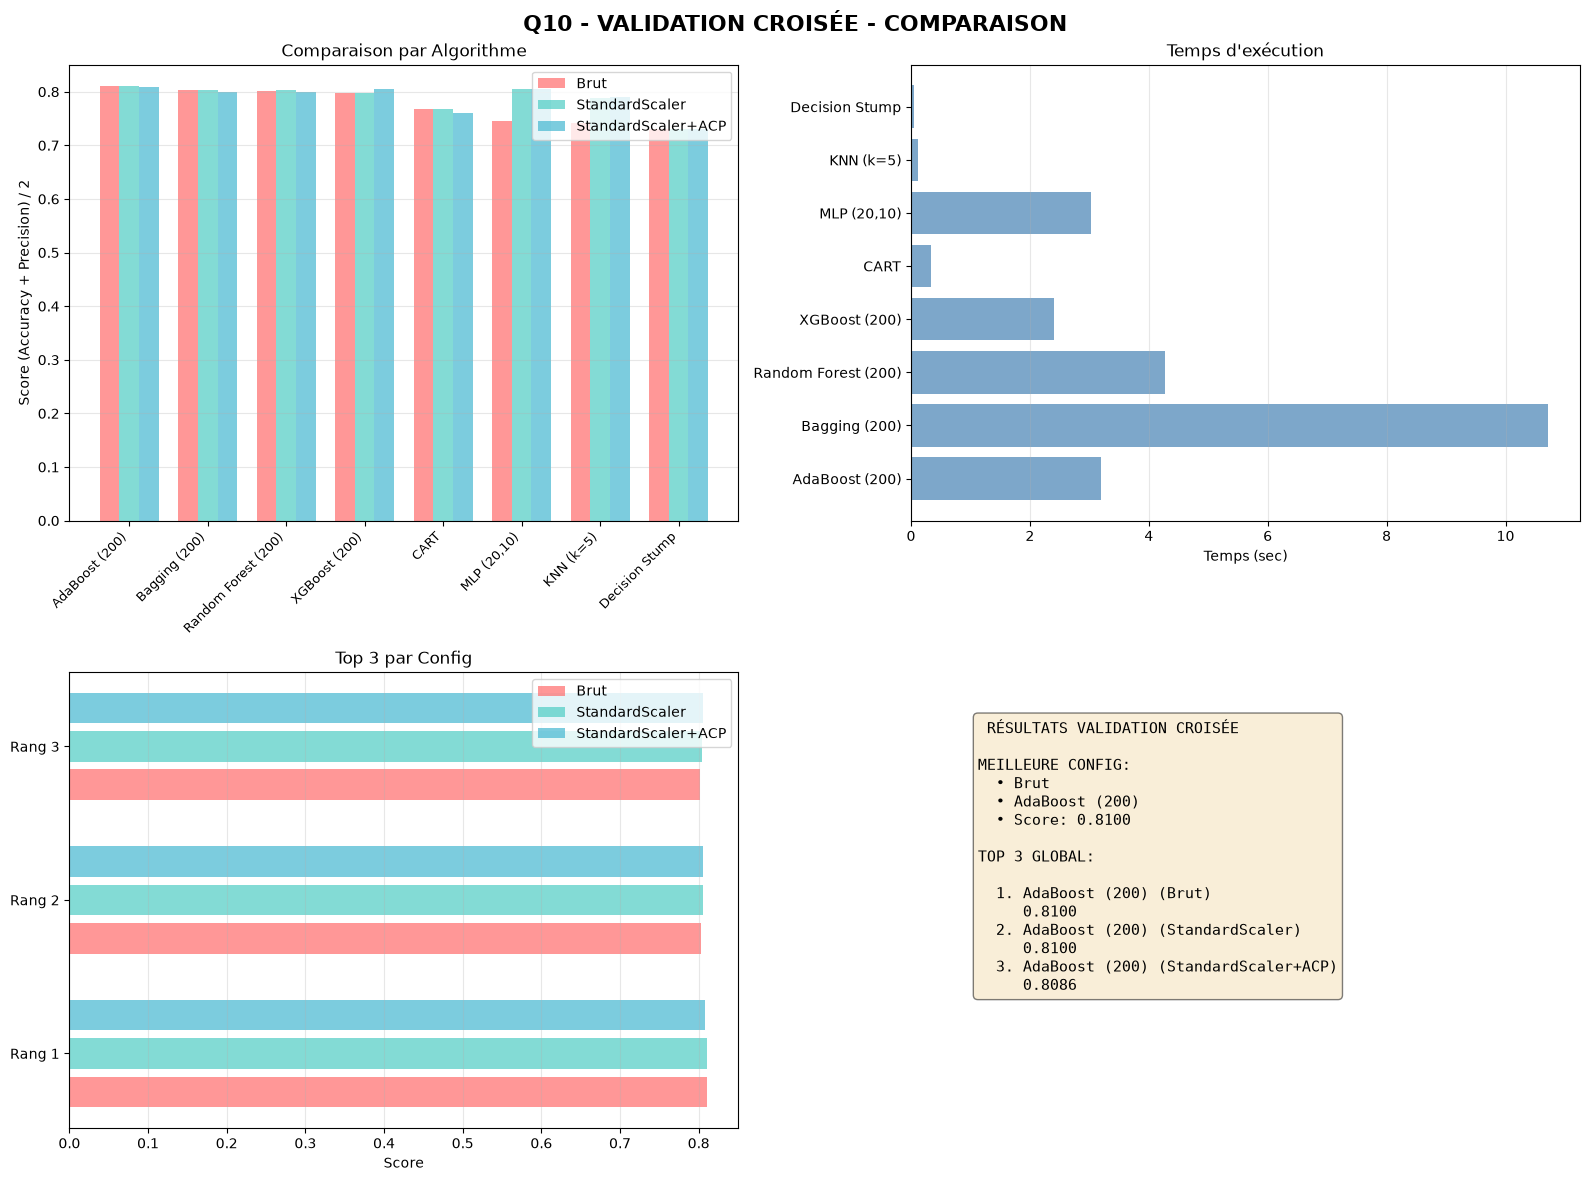

 Graphiques affichés


In [22]:
# -----------------------------------------------------------------------------
# VISUALISATION
# -----------------------------------------------------------------------------

print("\n Génération des graphiques...")

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Q10 - VALIDATION CROISÉE - COMPARAISON', fontsize=16, fontweight='bold')

# Graph 1: Scores par config
ax1 = axes[0, 0]
algos = results_brut['Algorithme'].values
x = np.arange(len(algos))
width = 0.25
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1']

for i, (config, df, color) in enumerate(zip(configs, all_results, colors)):
    scores = df.set_index('Algorithme').loc[algos, 'Score_mean'].values
    ax1.bar(x + i*width, scores, width, label=config, color=color, alpha=0.7)

ax1.set_xticks(x + width)
ax1.set_xticklabels(algos, rotation=45, ha='right', fontsize=9)
ax1.set_ylabel(f'Score {LABEL_SCORE}')
ax1.set_title('Comparaison par Algorithme')
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Graph 2: Temps
ax2 = axes[0, 1]
times = results_brut['Temps_sec'].values
ax2.barh(algos, times, color='steelblue', alpha=0.7)
ax2.set_xlabel('Temps (sec)')
ax2.set_title('Temps d\'exécution')
ax2.grid(axis='x', alpha=0.3)

# Graph 3: Top 3
ax3 = axes[1, 0]
y_pos = np.arange(3)
for i, (config, df, color) in enumerate(zip(configs, all_results, colors)):
    top3 = df.head(3)['Score_mean'].values
    ax3.barh(y_pos + i*0.25, top3, height=0.2, label=config, color=color, alpha=0.7)

ax3.set_yticks(y_pos + 0.25)
ax3.set_yticklabels(['Rang 1', 'Rang 2', 'Rang 3'])
ax3.set_xlabel('Score')
ax3.set_title('Top 3 par Config')
ax3.legend()
ax3.grid(axis='x', alpha=0.3)

# Graph 4: Résumé
ax4 = axes[1, 1]
ax4.axis('off')

summary = f""" RÉSULTATS VALIDATION CROISÉE

MEILLEURE CONFIG:
  • {best_config}
  • {best_algo}
  • Score: {best_score:.4f}

TOP 3 GLOBAL:
"""

all_scores = []
for config, df in zip(configs, all_results):
    for _, row in df.iterrows():
        all_scores.append({
            'config': config,
            'algo': row['Algorithme'],
            'score': row['Score_mean']
        })

all_scores.sort(key=lambda x: x['score'], reverse=True)

for i, item in enumerate(all_scores[:3], 1):
    summary += f"\n  {i}. {item['algo']} ({item['config']})"
    summary += f"\n     {item['score']:.4f}"

ax4.text(0.1, 0.9, summary, transform=ax4.transAxes,
        fontsize=11, verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()

print(" Graphiques affichés")

In [23]:
# -----------------------------------------------------------------------------
# PIPELINE FINAL
# -----------------------------------------------------------------------------

print("\n\n" + "="*70)
print("CRÉATION DU PIPELINE FINAL CV".center(70))
print("="*70)

from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import GridSearchCV
import pickle

print(f"\n  Config sélectionnée: {best_config}")
print(f"  Algo sélectionné: {best_algo}")

# Préparer les étapes : même prétraitement que la meilleure configuration
steps = [(name, clone(t)) for name, t in preprocessings[best_config]]

# Sélection de features : les n_optimal variables les plus importantes selon une
# RandomForest (même méthode qu'en Q5), ré-apprise dans chaque pli
steps.append(('feature_selection', SelectFromModel(
    RandomForestClassifier(n_estimators=100, random_state=1),
    threshold=-np.inf, max_features=n_optimal)))

# Classifier : le meilleur algorithme de la validation croisée
steps.append(('classifier', clone(clfs[best_algo])))

# Pipeline
pipeline = Pipeline(steps)

print(f"\n Pipeline: {len(steps)} étapes")
for name, _ in pipeline.steps:
    print(f"   • {name}")

# Grilles d'hyperparamètres (une par algorithme)
grilles_cv = {
    'CART': {'classifier__max_depth': [5, 10, None], 'classifier__min_samples_leaf': [1, 5]},
    'Decision Stump': {'classifier__criterion': ['gini', 'entropy']},
    'KNN (k=5)': {'classifier__n_neighbors': [5, 11, 21], 'classifier__weights': ['uniform', 'distance']},
    'MLP (20,10)': {'classifier__hidden_layer_sizes': [(20, 10), (40, 20)], 'classifier__alpha': [0.001, 0.01]},
    'Bagging (200)': {'classifier__n_estimators': [100, 200], 'classifier__max_samples': [0.5, 1.0]},
    'AdaBoost (200)': {'classifier__n_estimators': [100, 200], 'classifier__learning_rate': [0.5, 1.0]},
    'Random Forest (200)': {'classifier__n_estimators': [200], 'classifier__max_depth': [10, None]},
    'XGBoost (200)': {'classifier__n_estimators': [200], 'classifier__max_depth': [3, 5]},
}
params = dict(grilles_cv[best_algo])

# La validation croisée décide aussi si la sélection de variables est utile
params['feature_selection'] = ['passthrough', pipeline.named_steps['feature_selection']]

# GridSearch
print(f"\n GridSearchCV...")

grid = GridSearchCV(pipeline, params, scoring=scorer_final, cv=5, n_jobs=-1, verbose=0)

start = time.time()
grid.fit(X, y)
elapsed = time.time() - start

print(f" Terminé en {elapsed:.1f}s")
print(f"\n Meilleurs params:")
for k, v in grid.best_params_.items():
    print(f"   {k}: {type(v).__name__ if hasattr(v, 'fit') else v}")
print(f"\n Score CV: {grid.best_score_:.4f}")

# Sauvegarder
pipeline_path = MODELS_DIR / 'final_pipeline_cv.pkl'

with open(pipeline_path, 'wb') as f:
    pickle.dump(grid.best_estimator_, f)

print(f"\n Sauvegardé: {pipeline_path.relative_to(PROJECT_DIR).as_posix()} ({pipeline_path.stat().st_size / 1024:.1f} KB)")



                    CRÉATION DU PIPELINE FINAL CV                     

  Config sélectionnée: Brut
  Algo sélectionné: AdaBoost (200)

 Pipeline: 2 étapes
   • feature_selection
   • classifier

 GridSearchCV...


 Terminé en 11.4s

 Meilleurs params:
   classifier__learning_rate: 0.5
   classifier__n_estimators: 200
   feature_selection: passthrough

 Score CV: 0.8084

 Sauvegardé: models/final_pipeline_cv.pkl (109.5 KB)


## Partie II – Données hétérogènes (`credit.data`)

### Q1. Variables numériques uniquement

On garde les 6 variables numériques, on supprime les individus avec des valeurs manquantes,
puis on compare 6 algorithmes sans normalisation, avec `StandardScaler` et avec `MinMaxScaler`.

In [24]:
# ==============================================================================
# PARTIE II - DONNÉES HÉTÉROGÈNES : credit.data
# ==============================================================================

print("\n" + "="*80)
print("PARTIE II - DONNÉES HÉTÉROGÈNES (credit.data)".center(80))
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, auc
import warnings
warnings.filterwarnings('ignore')


                 PARTIE II - DONNÉES HÉTÉROGÈNES (credit.data)                  



--------------------------------------------------------------------------------
                ÉTAPE 1 : CHARGEMENT ET PRÉPARATION DES DONNÉES                 
--------------------------------------------------------------------------------

 Chargement du fichier credit.data...
 Dataset chargé : (688, 16)
   • 688 instances
   • 16 colonnes (15 features + 1 target)

 Aperçu des premières lignes :
  0      1      2  3  4  5  6     7  8  9   10 11 12     13   14 15
0  b  30.83  0.000  u  g  w  v  1.25  t  t   1  f  g  202.0    0  +
1  a  58.67  4.460  u  g  q  h  3.04  t  t   6  f  g   43.0  560  +
2  a  24.50  0.500  u  g  q  h  1.50  t  f   0  f  g  280.0  824  +
3  b  27.83  1.540  u  g  w  v  3.75  t  t   5  t  g  100.0    3  +
4  b  20.17  5.625  u  g  w  v  1.71  t  f   0  f  s  120.0    0  +

--------------------------------------------------------------------------------
                    ÉTAPE 2 : TRANSFORMATION EN NUMPY ARRAY                     
-------------------------

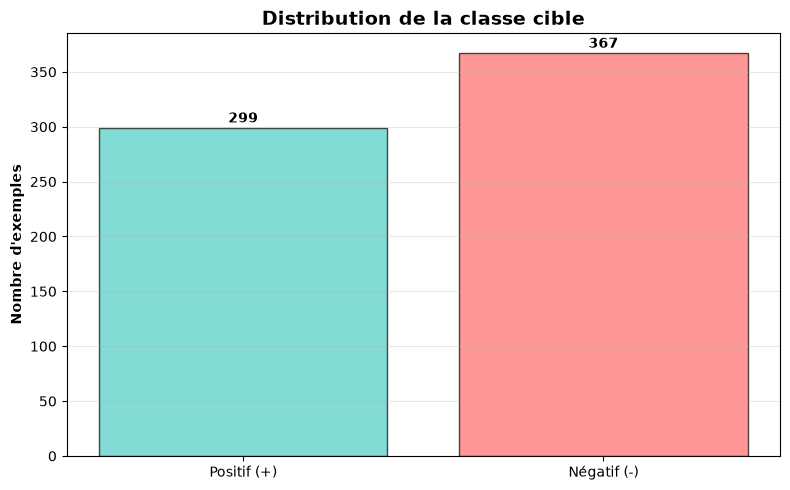


--------------------------------------------------------------------------------
                      ÉTAPE 7 : BINARISATION DE LA TARGET                       
--------------------------------------------------------------------------------

 Conversion :
   • '+' → 1 (crédit accordé)
   • '-' → 0 (crédit refusé)

 Target binarisée

 Distribution après binarisation :
   • Refusé (0) : 367 exemples (55.1%)
   • Accordé (1) : 299 exemples (44.9%)


In [25]:
# ==============================================================================
# 1. CHARGEMENT ET PRÉPARATION DES DONNÉES
# ==============================================================================

print("\n" + "-"*80)
print("ÉTAPE 1 : CHARGEMENT ET PRÉPARATION DES DONNÉES".center(80))
print("-"*80)

# 1.1 - IMPORTATION
print("\n Chargement du fichier credit.data...")

# Le fichier utilise des tabulations comme séparateur et n'a pas d'en-tête
df_credit = pd.read_csv(DATA_DIR / 'credit.data',
                        header=None,
                        sep='\t',
                        na_values='?')  # Traiter '?' comme valeurs manquantes

print(f" Dataset chargé : {df_credit.shape}")
print(f"   • {df_credit.shape[0]} instances")
print(f"   • {df_credit.shape[1]} colonnes (15 features + 1 target)")

print("\n Aperçu des premières lignes :")
print(df_credit.head())

# 1.2 - TRANSFORMATION EN NUMPY ARRAY
print("\n" + "-"*80)
print("ÉTAPE 2 : TRANSFORMATION EN NUMPY ARRAY".center(80))
print("-"*80)

# Séparer X et y
X_credit_full = df_credit.iloc[:, :-1].to_numpy()  # Toutes les colonnes sauf la dernière
y_credit_full = df_credit.iloc[:, -1].to_numpy()   # Dernière colonne (target)

print(f"\n Séparation X/y effectuée")
print(f"   • X shape : {X_credit_full.shape}")
print(f"   • y shape : {y_credit_full.shape}")

# Distribution de y
unique_classes, counts = np.unique(y_credit_full, return_counts=True)
print(f"\n Distribution de la classe cible :")
for cls, count in zip(unique_classes, counts):
    pct = count / len(y_credit_full) * 100
    print(f"   • '{cls}' : {count} exemples ({pct:.1f}%)")

# ==============================================================================
# 1.3 - IDENTIFIER LES COLONNES NUMÉRIQUES
# ==============================================================================

print("\n" + "-"*80)
print("ÉTAPE 3 : EXTRACTION DES VARIABLES NUMÉRIQUES".center(80))
print("-"*80)

# Méthode CORRECTE : détecter automatiquement les colonnes numériques
print("\n🔍 Détection automatique des colonnes numériques...")

# Examiner chaque colonne
numeric_cols = []
for col_idx in range(X_credit_full.shape[1]):
    col_data = X_credit_full[:, col_idx]

    # Essayer de convertir en float
    try:
        # Remplacer '?' par nan temporairement
        col_cleaned = np.where(col_data == '?', 'nan', col_data)
        # Tester la conversion
        col_as_float = col_cleaned.astype(float)
        # Si ça marche, c'est numérique
        numeric_cols.append(col_idx)
        print(f"   ✓ Colonne {col_idx:2d} : NUMÉRIQUE (ex: {col_data[0]})")
    except (ValueError, TypeError):
        # Si ça échoue, c'est catégoriel
        print(f"   ✗ Colonne {col_idx:2d} : CATÉGORIEL (ex: {col_data[0]})")

print(f"\n✅ {len(numeric_cols)} colonnes numériques identifiées : {numeric_cols}")

# Extraire les colonnes numériques
X_numeric = X_credit_full[:, numeric_cols].copy()

print(f"✅ Variables numériques extraites : {X_numeric.shape}")
print(f"   • {X_numeric.shape[0]} instances")
print(f"   • {X_numeric.shape[1]} variables numériques")

# ==============================================================================
# 1.4 - REMPLACER '?' PAR NaN ET CONVERTIR EN FLOAT
# ==============================================================================

print("\n" + "-"*80)
print("ÉTAPE 4 : GESTION DES VALEURS MANQUANTES".center(80))
print("-"*80)

print("\n🔧 Nettoyage et conversion en float...")

# Compter les valeurs manquantes AVANT ('?' a été lu comme NaN par read_csv)
n_missing_before = int(pd.isna(X_numeric).sum())
print(f"   • Nombre de valeurs manquantes ('?') détectées : {n_missing_before}")

# Remplacer '?' par 'nan' (string)
X_numeric_cleaned = np.where(X_numeric == '?', 'nan', X_numeric)

# Convertir en float (maintenant ça va marcher)
X_numeric_float = X_numeric_cleaned.astype(float)

# Compter les NaN APRÈS
n_nan = np.sum(np.isnan(X_numeric_float))
print(f"   • Nombre de NaN après conversion : {n_nan}")

print("\n📊 Valeurs manquantes par colonne :")
for j, col_idx in enumerate(numeric_cols):
    n_missing = np.sum(np.isnan(X_numeric_float[:, j]))
    pct = (n_missing / X_numeric_float.shape[0]) * 100
    if n_missing > 0:
        print(f"   • Colonne {col_idx:2d} : {n_missing:3d} NaN ({pct:5.1f}%)")
    else:
        print(f"   • Colonne {col_idx:2d} : {n_missing:3d} NaN ✓")

# ==============================================================================
# 1.5 - SUPPRIMER LES LIGNES AVEC DES NaN
# ==============================================================================

print("\n" + "-"*80)
print("ÉTAPE 5 : SUPPRESSION DES INSTANCES AVEC NaN".center(80))
print("-"*80)

# Identifier les lignes sans NaN
mask_no_nan = ~np.any(np.isnan(X_numeric_float), axis=1)

# Filtrer X et y
X_credit_clean = X_numeric_float[mask_no_nan]
y_credit_clean = y_credit_full[mask_no_nan]

n_removed = len(y_credit_full) - len(y_credit_clean)

print(f"\n🗑️  Instances supprimées : {n_removed} ({n_removed/len(y_credit_full)*100:.1f}%)")
print(f"✅ Dataset nettoyé : {X_credit_clean.shape}")
print(f"   • {X_credit_clean.shape[0]} instances restantes")
print(f"   • {X_credit_clean.shape[1]} variables")

# Vérifier qu'il n'y a plus de NaN
n_nan_after = np.sum(np.isnan(X_credit_clean))
print(f"\n✓ Nombre de NaN restants : {n_nan_after}")

# Afficher quelques statistiques
print("\n📊 Statistiques des données nettoyées :")
stats_df = pd.DataFrame({
    'Colonne': [f'Col_{numeric_cols[i]}' for i in range(X_credit_clean.shape[1])],
    'Min': X_credit_clean.min(axis=0),
    'Max': X_credit_clean.max(axis=0),
    'Moyenne': X_credit_clean.mean(axis=0),
    'Écart-type': X_credit_clean.std(axis=0)
})
print(stats_df.to_string(index=False))
# 1.6 - ANALYSER LES PROPRIÉTÉS DES DONNÉES NETTOYÉES
print("\n" + "-"*80)
print("ÉTAPE 6 : ANALYSE DES PROPRIÉTÉS".center(80))
print("-"*80)

print("\n TAILLE DE L'ÉCHANTILLON :")
print(f"   • Nombre d'instances : {X_credit_clean.shape[0]}")
print(f"   • Nombre de variables : {X_credit_clean.shape[1]}")
print(f"   • Taille totale : {X_credit_clean.shape[0]} × {X_credit_clean.shape[1]}")

print("\n DISTRIBUTION DE LA CLASSE CIBLE :")
unique, counts = np.unique(y_credit_clean, return_counts=True)
for label, count in zip(unique, counts):
    pct = (count / len(y_credit_clean)) * 100
    symbol = '+' if label == '+' else '-'
    print(f"   • Classe '{symbol}' : {count} exemples ({pct:.1f}%)")
    print(f"     {'█' * int(count/5)}")

# Visualisation
plt.figure(figsize=(8, 5))
# Étiquettes dans l'ordre de np.unique ('+' est trié avant '-')
bar_labels = ['Positif (+)' if label == '+' else 'Négatif (-)' for label in unique]
bar_colors = ['#4ECDC4' if label == '+' else '#FF6B6B' for label in unique]
plt.bar(bar_labels, counts, color=bar_colors, alpha=0.7, edgecolor='black')
plt.ylabel('Nombre d\'exemples', fontweight='bold')
plt.title('Distribution de la classe cible', fontweight='bold', fontsize=14)
plt.grid(axis='y', alpha=0.3)
for i, count in enumerate(counts):
    plt.text(i, count + 5, str(count), ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

# 1.7 - BINARISER LA TARGET
print("\n" + "-"*80)
print("ÉTAPE 7 : BINARISATION DE LA TARGET".center(80))
print("-"*80)

print("\n Conversion :")
print("   • '+' → 1 (crédit accordé)")
print("   • '-' → 0 (crédit refusé)")

# Binariser
y_credit_binary = np.where(y_credit_clean == '+', 1, 0)

print(f"\n Target binarisée")
print(f"\n Distribution après binarisation :")
unique_bin, counts_bin = np.unique(y_credit_binary, return_counts=True)
for cls, count in zip(unique_bin, counts_bin):
    pct = (count / len(y_credit_binary)) * 100
    label = "Accordé (1)" if cls == 1 else "Refusé (0)"
    print(f"   • {label} : {count} exemples ({pct:.1f}%)")

In [26]:
# ==============================================================================
# 2. FONCTION run_classifiers AVEC AUC
# ==============================================================================

print("\n\n" + "="*80)
print("CRÉATION DE LA FONCTION run_classifiers AVEC AUC".center(80))
print("="*80)

def run_classifiers_with_auc(clfs_dict, X_train, y_train, X_test, y_test, verbose=True):
    """
    Compare plusieurs classifieurs avec métriques incluant AUC

    Paramètres :
    -----------
    clfs_dict : dict
        Dictionnaire {nom: classifier}
    X_train, y_train : données d'entraînement
    X_test, y_test : données de test
    verbose : bool
        Afficher les détails

    Retourne :
    ---------
    results_df : DataFrame avec tous les résultats
    """

    results = []

    if verbose:
        print(f"\n🔧 Entraînement de {len(clfs_dict)} algorithmes...")
        print(f"   • Train : {X_train.shape[0]} instances")
        print(f"   • Test  : {X_test.shape[0]} instances\n")

    for i, (name, clf) in enumerate(clfs_dict.items(), 1):
        if verbose:
            print(f"[{i}/{len(clfs_dict)}] {name}...")

        # Entraînement
        clf.fit(X_train, y_train)

        # Prédictions
        y_pred = clf.predict(X_test)

        # Probabilités (pour AUC)
        try:
            y_proba = clf.predict_proba(X_test)[:, 1]
        except:
            # Si le modèle ne supporte pas predict_proba
            y_proba = y_pred

        # Métriques
        from sklearn.metrics import accuracy_score, recall_score, precision_score, f1_score

        acc = accuracy_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred, zero_division=0)
        prec = precision_score(y_test, y_pred, zero_division=0)
        f1 = f1_score(y_test, y_pred, zero_division=0)

        # AUC
        try:
            auc_score = roc_auc_score(y_test, y_proba)
        except:
            auc_score = 0.0

        # Score final (Accuracy + critère) / 2 : même critère que la Partie I
        score = score_final(y_test, y_pred, CRITERE)

        results.append({
            'Algorithme': name,
            'Accuracy': acc,
            'Recall': rec,
            'Precision': prec,
            'F1-Score': f1,
            'AUC-ROC': auc_score,
            'Score_Final': score
        })

        if verbose:
            print(f"   ✓ Acc: {acc:.4f} | Rec: {rec:.4f} | Prec: {prec:.4f} | AUC: {auc_score:.4f}\n")

    # Créer DataFrame
    results_df = pd.DataFrame(results)
    results_df = results_df.sort_values('Score_Final', ascending=False)
    results_df['Rang'] = range(1, len(results_df) + 1)

    if verbose:
        print("\n" + "="*80)
        print("TABLEAU COMPARATIF".center(80))
        print("="*80 + "\n")
        print(results_df.to_string(index=False))

        print("\n CLASSEMENT :")
        for i in range(min(3, len(results_df))):
            row = results_df.iloc[i]
            medal = ["1", "2", "3"][i]
            print(f"\n{medal} Rang {i+1} : {row['Algorithme']}")
            print(f"   • Score Final : {row['Score_Final']:.4f}")
            print(f"   • AUC-ROC     : {row['AUC-ROC']:.4f}")

    return results_df

print(" Fonction run_classifiers_with_auc créée !")



                CRÉATION DE LA FONCTION run_classifiers AVEC AUC                
 Fonction run_classifiers_with_auc créée !


In [27]:
# ==============================================================================
# 3. DIVISION TRAIN/TEST ET COMPARAISON DES ALGORITHMES
# ==============================================================================

print("\n\n" + "="*80)
print("COMPARAISON DES ALGORITHMES".center(80))
print("="*80)

# Split 50/50
print("\n Division Train/Test (50/50)...")
X_train_credit, X_test_credit, y_train_credit, y_test_credit = train_test_split(
    X_credit_clean,
    y_credit_binary,
    test_size=0.5,
    random_state=1,
    stratify=y_credit_binary
)

print(f" Split effectué")
print(f"   • Train : {X_train_credit.shape[0]} instances")
print(f"   • Test  : {X_test_credit.shape[0]} instances")

# Définir les algorithmes
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier, BaggingClassifier, AdaBoostClassifier

classifiers_credit = {
    'CART (Decision Tree)': DecisionTreeClassifier(random_state=1),
    'KNN (k=5)': KNeighborsClassifier(n_neighbors=5),
    'MLP (40,20)': MLPClassifier(hidden_layer_sizes=(40, 20), random_state=1, max_iter=1000),
    'Random Forest (100)': RandomForestClassifier(n_estimators=100, random_state=1),
    'Bagging (100)': BaggingClassifier(n_estimators=100, random_state=1),
    'AdaBoost (100)': AdaBoostClassifier(n_estimators=100, random_state=1)
}

print(f"\n {len(classifiers_credit)} algorithmes à tester")

# Exécuter la comparaison
results_credit = run_classifiers_with_auc(
    classifiers_credit,
    X_train_credit, y_train_credit,
    X_test_credit, y_test_credit,
    verbose=True
)



                          COMPARAISON DES ALGORITHMES                           

 Division Train/Test (50/50)...
 Split effectué
   • Train : 333 instances
   • Test  : 333 instances

 6 algorithmes à tester

🔧 Entraînement de 6 algorithmes...
   • Train : 333 instances
   • Test  : 333 instances

[1/6] CART (Decision Tree)...
   ✓ Acc: 0.7117 | Rec: 0.7133 | Prec: 0.6687 | AUC: 0.7119

[2/6] KNN (k=5)...


   ✓ Acc: 0.6426 | Rec: 0.5733 | Prec: 0.6099 | AUC: 0.6832

[3/6] MLP (40,20)...
   ✓ Acc: 0.6607 | Rec: 0.5800 | Prec: 0.6350 | AUC: 0.6635

[4/6] Random Forest (100)...


   ✓ Acc: 0.7928 | Rec: 0.7200 | Prec: 0.8000 | AUC: 0.8501

[5/6] Bagging (100)...


   ✓ Acc: 0.7718 | Rec: 0.7333 | Prec: 0.7534 | AUC: 0.8452

[6/6] AdaBoost (100)...


   ✓ Acc: 0.7928 | Rec: 0.7333 | Prec: 0.7914 | AUC: 0.8627


                               TABLEAU COMPARATIF                               

          Algorithme  Accuracy   Recall  Precision  F1-Score  AUC-ROC  Score_Final  Rang
 Random Forest (100)  0.792793 0.720000   0.800000  0.757895 0.850055     0.796396     1
      AdaBoost (100)  0.792793 0.733333   0.791367  0.761246 0.862696     0.792080     2
       Bagging (100)  0.771772 0.733333   0.753425  0.743243 0.845228     0.762598     3
CART (Decision Tree)  0.711712 0.713333   0.668750  0.690323 0.711858     0.690231     4
         MLP (40,20)  0.660661 0.580000   0.635036  0.606272 0.663497     0.647849     5
           KNN (k=5)  0.642643 0.573333   0.609929  0.591065 0.683169     0.626286     6

 CLASSEMENT :

1 Rang 1 : Random Forest (100)
   • Score Final : 0.7964
   • AUC-ROC     : 0.8501

2 Rang 2 : AdaBoost (100)
   • Score Final : 0.7921
   • AUC-ROC     : 0.8627

3 Rang 3 : Bagging (100)
   • Score Final : 0.7626
   



                          VISUALISATION DES RÉSULTATS                           


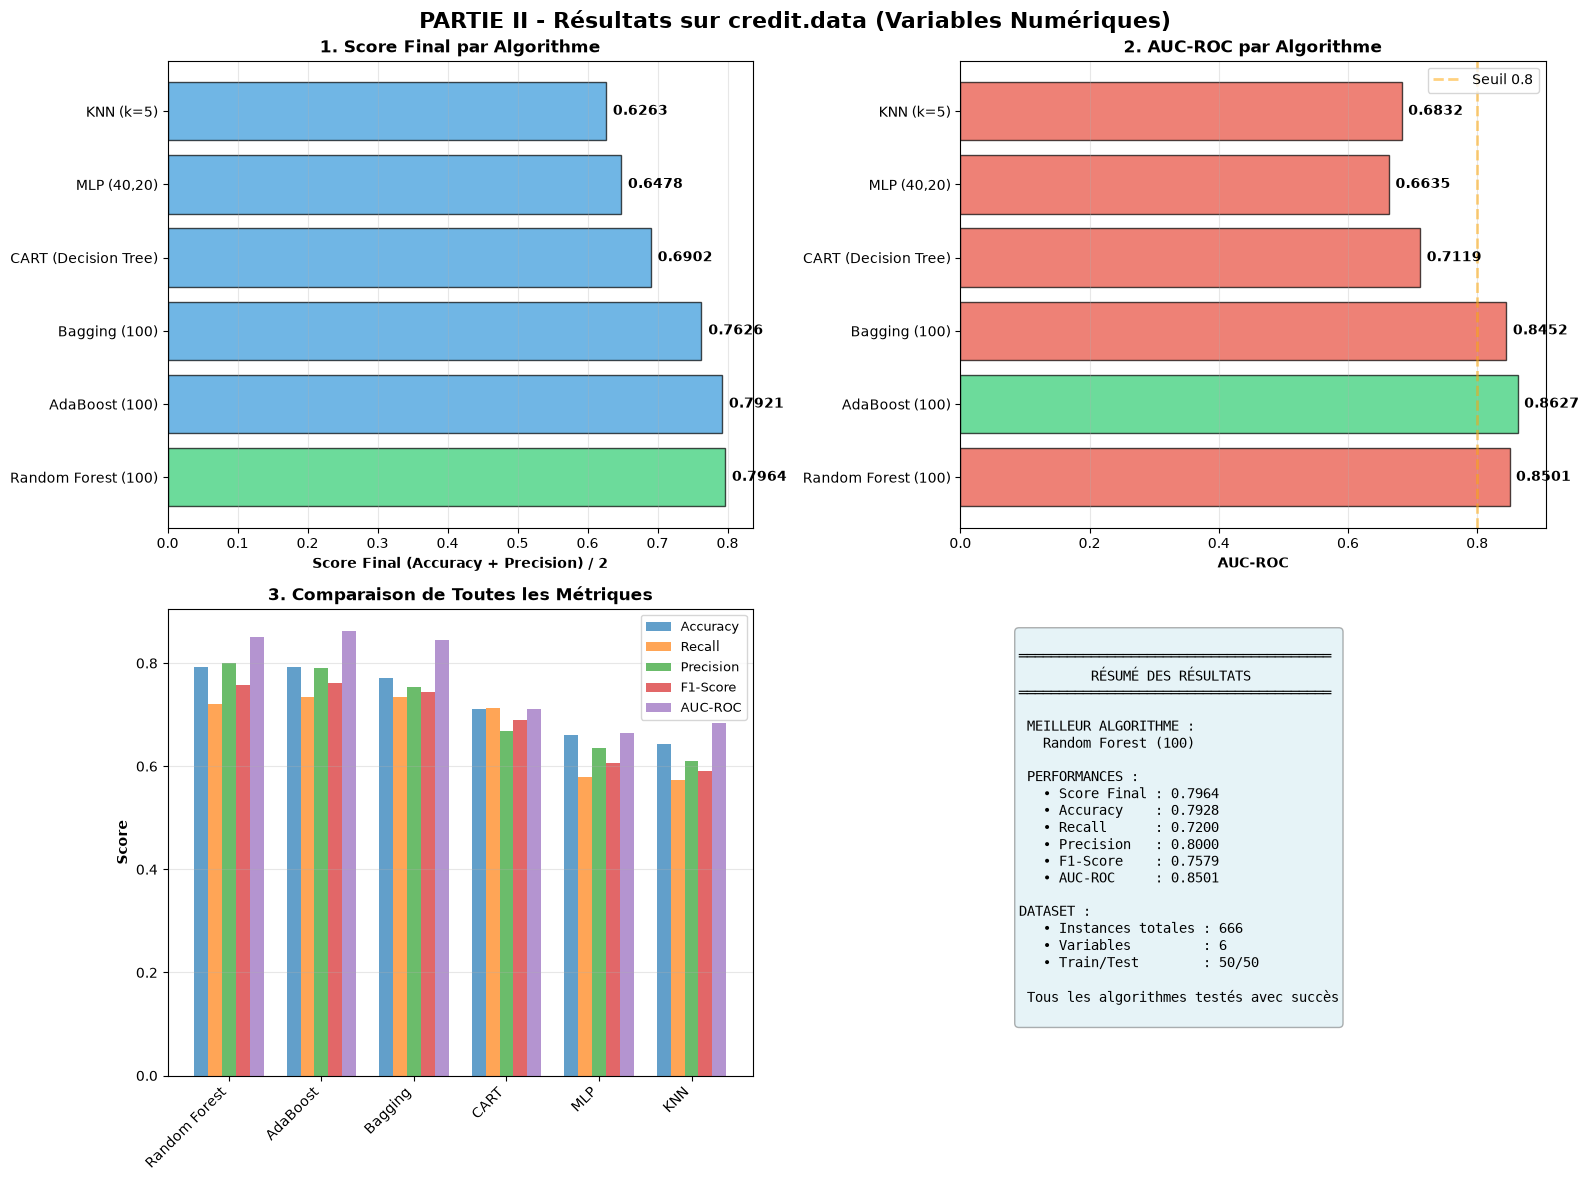


 Graphiques affichés


In [28]:
# ==============================================================================
# 4. VISUALISATION DES RÉSULTATS
# ==============================================================================

print("\n\n" + "="*80)
print("VISUALISATION DES RÉSULTATS".center(80))
print("="*80)

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('PARTIE II - Résultats sur credit.data (Variables Numériques)',
             fontsize=16, fontweight='bold')

# Graphique 1 : Score Final
ax1 = axes[0, 0]
algos = results_credit['Algorithme'].values
scores = results_credit['Score_Final'].values
colors = ['#2ECC71' if i == 0 else '#3498DB' for i in range(len(algos))]
bars1 = ax1.barh(algos, scores, color=colors, alpha=0.7, edgecolor='black')
ax1.set_xlabel(f'Score Final {LABEL_SCORE}', fontweight='bold')
ax1.set_title('1. Score Final par Algorithme', fontweight='bold')
ax1.grid(axis='x', alpha=0.3)
for bar, score in zip(bars1, scores):
    ax1.text(score + 0.01, bar.get_y() + bar.get_height()/2,
             f'{score:.4f}', va='center', fontweight='bold')

# Graphique 2 : AUC-ROC
ax2 = axes[0, 1]
aucs = results_credit['AUC-ROC'].values
colors_auc = ['#2ECC71' if auc == max(aucs) else '#E74C3C' for auc in aucs]
bars2 = ax2.barh(algos, aucs, color=colors_auc, alpha=0.7, edgecolor='black')
ax2.set_xlabel('AUC-ROC', fontweight='bold')
ax2.set_title('2. AUC-ROC par Algorithme', fontweight='bold')
ax2.grid(axis='x', alpha=0.3)
ax2.axvline(x=0.8, color='orange', linestyle='--', linewidth=2, alpha=0.5, label='Seuil 0.8')
ax2.legend()
for bar, auc in zip(bars2, aucs):
    ax2.text(auc + 0.01, bar.get_y() + bar.get_height()/2,
             f'{auc:.4f}', va='center', fontweight='bold')

# Graphique 3 : Toutes les métriques
ax3 = axes[1, 0]
metrics = ['Accuracy', 'Recall', 'Precision', 'F1-Score', 'AUC-ROC']
x = np.arange(len(algos))
width = 0.15

for i, metric in enumerate(metrics):
    values = results_credit[metric].values
    ax3.bar(x + i*width, values, width, label=metric, alpha=0.7)

ax3.set_ylabel('Score', fontweight='bold')
ax3.set_title('3. Comparaison de Toutes les Métriques', fontweight='bold')
ax3.set_xticks(x + width * 2)
ax3.set_xticklabels([a.split('(')[0].strip() for a in algos], rotation=45, ha='right')
ax3.legend(fontsize=9)
ax3.grid(axis='y', alpha=0.3)

# Graphique 4 : Résumé textuel
ax4 = axes[1, 1]
ax4.axis('off')

best_row = results_credit.iloc[0]
summary_text = f"""
═══════════════════════════════════════
         RÉSUMÉ DES RÉSULTATS
═══════════════════════════════════════

 MEILLEUR ALGORITHME :
   {best_row['Algorithme']}

 PERFORMANCES :
   • Score Final : {best_row['Score_Final']:.4f}
   • Accuracy    : {best_row['Accuracy']:.4f}
   • Recall      : {best_row['Recall']:.4f}
   • Precision   : {best_row['Precision']:.4f}
   • F1-Score    : {best_row['F1-Score']:.4f}
   • AUC-ROC     : {best_row['AUC-ROC']:.4f}

DATASET :
   • Instances totales : {len(y_credit_clean)}
   • Variables         : {X_credit_clean.shape[1]}
   • Train/Test        : 50/50

 Tous les algorithmes testés avec succès
"""

ax4.text(0.1, 0.95, summary_text, transform=ax4.transAxes,
        fontsize=10, verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.3))

plt.tight_layout()
plt.show()

print("\n Graphiques affichés")

In [29]:
# ==============================================================================
#  SUITE : NORMALISATION ET COMPARAISON
# ==============================================================================

print("\n\n" + "="*80)
print("PARTIE II - NORMALISATION DES VARIABLES CONTINUES".center(80))
print("="*80)

from sklearn.preprocessing import StandardScaler, MinMaxScaler
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd



               PARTIE II - NORMALISATION DES VARIABLES CONTINUES                


In [30]:
# ==============================================================================
# 1. RAPPEL DES RÉSULTATS SANS NORMALISATION (BASELINE)
# ==============================================================================

print("\n" + "-"*80)
print("ÉTAPE 1 : RAPPEL - RÉSULTATS SANS NORMALISATION (BASELINE)".center(80))
print("-"*80)

print("\n Résultats de référence (données brutes) :")
print(results_credit[['Algorithme', 'Accuracy', 'Recall', 'AUC-ROC', 'Score_Final']].to_string(index=False))

# Stocker les résultats baseline
results_baseline = results_credit.copy()
results_baseline['Configuration'] = 'Sans normalisation'

print(f"\n Meilleur algorithme (baseline) : {results_baseline.iloc[0]['Algorithme']}")
print(f"   Score Final : {results_baseline.iloc[0]['Score_Final']:.4f}")
print(f"   AUC-ROC     : {results_baseline.iloc[0]['AUC-ROC']:.4f}")


--------------------------------------------------------------------------------
           ÉTAPE 1 : RAPPEL - RÉSULTATS SANS NORMALISATION (BASELINE)           
--------------------------------------------------------------------------------

 Résultats de référence (données brutes) :
          Algorithme  Accuracy   Recall  AUC-ROC  Score_Final
 Random Forest (100)  0.792793 0.720000 0.850055     0.796396
      AdaBoost (100)  0.792793 0.733333 0.862696     0.792080
       Bagging (100)  0.771772 0.733333 0.845228     0.762598
CART (Decision Tree)  0.711712 0.713333 0.711858     0.690231
         MLP (40,20)  0.660661 0.580000 0.663497     0.647849
           KNN (k=5)  0.642643 0.573333 0.683169     0.626286

 Meilleur algorithme (baseline) : Random Forest (100)
   Score Final : 0.7964
   AUC-ROC     : 0.8501


In [31]:
# ==============================================================================
# 2. NORMALISATION AVEC StandardScaler
# ==============================================================================

print("\n\n" + "="*80)
print("ÉTAPE 2 : NORMALISATION AVEC StandardScaler".center(80))
print("="*80)

print("\n StandardScaler :")
print("   • Formule : X_norm = (X - moyenne) / écart-type")
print("   • Résultat : moyenne ≈ 0, écart-type ≈ 1")
print("   • Usage : KNN, MLP, SVM (sensibles à l'échelle)")

# Créer le scaler
scaler_standard_credit = StandardScaler()

# FIT sur train UNIQUEMENT (éviter data leakage)
print("\n Fit du StandardScaler sur X_train...")
scaler_standard_credit.fit(X_train_credit)

# TRANSFORM train et test
print(" Transformation de X_train et X_test...")
X_train_standard_credit = scaler_standard_credit.transform(X_train_credit)
X_test_standard_credit = scaler_standard_credit.transform(X_test_credit)

# Vérification
print(f"\n Normalisation StandardScaler effectuée")
print(f"   • Moyenne train  : {X_train_standard_credit.mean():.6f} (attendu ≈ 0)")
print(f"   • Écart-type train : {X_train_standard_credit.std():.6f} (attendu ≈ 1)")
print(f"   • Min train      : {X_train_standard_credit.min():.2f}")
print(f"   • Max train      : {X_train_standard_credit.max():.2f}")

# Statistiques par feature
print("\n Statistiques par variable (train) :")
stats_df = pd.DataFrame({
    'Variable': [f'V{i+1}' for i in range(X_train_standard_credit.shape[1])],
    'Moyenne': X_train_standard_credit.mean(axis=0),
    'Écart-type': X_train_standard_credit.std(axis=0),
    'Min': X_train_standard_credit.min(axis=0),
    'Max': X_train_standard_credit.max(axis=0)
})
print(stats_df.to_string(index=False))

# Comparaison des algorithmes avec StandardScaler
print("\n\n Comparaison des algorithmes avec StandardScaler...")
print("-" * 80)

results_standard_credit = run_classifiers_with_auc(
    classifiers_credit,
    X_train_standard_credit, y_train_credit,
    X_test_standard_credit, y_test_credit,
    verbose=True
)

results_standard_credit['Configuration'] = 'StandardScaler'



                  ÉTAPE 2 : NORMALISATION AVEC StandardScaler                   

 StandardScaler :
   • Formule : X_norm = (X - moyenne) / écart-type
   • Résultat : moyenne ≈ 0, écart-type ≈ 1
   • Usage : KNN, MLP, SVM (sensibles à l'échelle)

 Fit du StandardScaler sur X_train...
 Transformation de X_train et X_test...

 Normalisation StandardScaler effectuée
   • Moyenne train  : 0.000000 (attendu ≈ 0)
   • Écart-type train : 1.000000 (attendu ≈ 1)
   • Min train      : -1.50
   • Max train      : 12.08

 Statistiques par variable (train) :
Variable       Moyenne  Écart-type       Min       Max
      V1 -8.001607e-18         1.0 -1.500022  4.193048
      V2  1.917052e-16         1.0 -1.001369  4.321105
      V3 -1.249418e-16         1.0 -0.691798  5.550075
      V4  3.600723e-17         1.0 -0.574678  4.273304
      V5 -4.067484e-17         1.0 -1.014654  9.816567
      V6  3.242318e-17         1.0 -0.205930 12.078117


 Comparaison des algorithmes avec StandardScaler...
-------

   ✓ Acc: 0.7718 | Rec: 0.7400 | Prec: 0.7500 | AUC: 0.8269

[4/6] Random Forest (100)...
   ✓ Acc: 0.7898 | Rec: 0.7200 | Prec: 0.7941 | AUC: 0.8505

[5/6] Bagging (100)...


   ✓ Acc: 0.7718 | Rec: 0.7333 | Prec: 0.7534 | AUC: 0.8454

[6/6] AdaBoost (100)...


   ✓ Acc: 0.7928 | Rec: 0.7333 | Prec: 0.7914 | AUC: 0.8627


                               TABLEAU COMPARATIF                               

          Algorithme  Accuracy   Recall  Precision  F1-Score  AUC-ROC  Score_Final  Rang
           KNN (k=5)  0.777778 0.640000   0.827586  0.721805 0.820328     0.802682     1
      AdaBoost (100)  0.792793 0.733333   0.791367  0.761246 0.862696     0.792080     2
 Random Forest (100)  0.789790 0.720000   0.794118  0.755245 0.850455     0.791954     3
       Bagging (100)  0.771772 0.733333   0.753425  0.743243 0.845355     0.762598     4
         MLP (40,20)  0.771772 0.740000   0.750000  0.744966 0.826922     0.760886     5
CART (Decision Tree)  0.714715 0.720000   0.670807  0.694534 0.715191     0.692761     6

 CLASSEMENT :

1 Rang 1 : KNN (k=5)
   • Score Final : 0.8027
   • AUC-ROC     : 0.8203

2 Rang 2 : AdaBoost (100)
   • Score Final : 0.7921
   • AUC-ROC     : 0.8627

3 Rang 3 : Random Forest (100)
   • Score Final : 0.7920
   • AU

In [32]:
# ==============================================================================
# 3. NORMALISATION AVEC MinMaxScaler
# ==============================================================================

print("\n\n" + "="*80)
print("ÉTAPE 3 : NORMALISATION AVEC MinMaxScaler".center(80))
print("="*80)

print("\n MinMaxScaler :")
print("   • Formule : X_norm = (X - min) / (max - min)")
print("   • Résultat : toutes les valeurs entre 0 et 1")
print("   • Usage : réseaux de neurones, algorithmes basés sur distances")

# Créer le scaler
scaler_minmax_credit = MinMaxScaler()

# FIT sur train UNIQUEMENT
print("\n Fit du MinMaxScaler sur X_train...")
scaler_minmax_credit.fit(X_train_credit)

# TRANSFORM train et test
print(" Transformation de X_train et X_test...")
X_train_minmax_credit = scaler_minmax_credit.transform(X_train_credit)
X_test_minmax_credit = scaler_minmax_credit.transform(X_test_credit)

# Vérification
print(f"\n Normalisation MinMaxScaler effectuée")
print(f"   • Min train : {X_train_minmax_credit.min():.6f} (attendu ≈ 0)")
print(f"   • Max train : {X_train_minmax_credit.max():.6f} (attendu ≈ 1)")
print(f"   • Moyenne train : {X_train_minmax_credit.mean():.4f}")

# Statistiques par feature
print("\n Statistiques par variable (train) :")
stats_df_mm = pd.DataFrame({
    'Variable': [f'V{i+1}' for i in range(X_train_minmax_credit.shape[1])],
    'Moyenne': X_train_minmax_credit.mean(axis=0),
    'Min': X_train_minmax_credit.min(axis=0),
    'Max': X_train_minmax_credit.max(axis=0)
})
print(stats_df_mm.to_string(index=False))

# Comparaison des algorithmes avec MinMaxScaler
print("\n\n Comparaison des algorithmes avec MinMaxScaler...")
print("-" * 80)

results_minmax_credit = run_classifiers_with_auc(
    classifiers_credit,
    X_train_minmax_credit, y_train_credit,
    X_test_minmax_credit, y_test_credit,
    verbose=True
)

results_minmax_credit['Configuration'] = 'MinMaxScaler'



                   ÉTAPE 3 : NORMALISATION AVEC MinMaxScaler                    

 MinMaxScaler :
   • Formule : X_norm = (X - min) / (max - min)
   • Résultat : toutes les valeurs entre 0 et 1
   • Usage : réseaux de neurones, algorithmes basés sur distances

 Fit du MinMaxScaler sur X_train...
 Transformation de X_train et X_test...

 Normalisation MinMaxScaler effectuée
   • Min train : 0.000000 (attendu ≈ 0)
   • Max train : 1.000000 (attendu ≈ 1)
   • Moyenne train : 0.1319

 Statistiques par variable (train) :
Variable  Moyenne  Min  Max
      V1 0.263482  0.0  1.0
      V2 0.188140  0.0  1.0
      V3 0.110832  0.0  1.0
      V4 0.118540  0.0  1.0
      V5 0.093679  0.0  1.0
      V6 0.016764  0.0  1.0


 Comparaison des algorithmes avec MinMaxScaler...
--------------------------------------------------------------------------------

🔧 Entraînement de 6 algorithmes...
   • Train : 333 instances
   • Test  : 333 instances

[1/6] CART (Decision Tree)...
   ✓ Acc: 0.7117 | Rec: 0.

   ✓ Acc: 0.7688 | Rec: 0.7133 | Prec: 0.7589 | AUC: 0.8222

[4/6] Random Forest (100)...
   ✓ Acc: 0.7928 | Rec: 0.7200 | Prec: 0.8000 | AUC: 0.8505

[5/6] Bagging (100)...


   ✓ Acc: 0.7688 | Rec: 0.7267 | Prec: 0.7517 | AUC: 0.8450

[6/6] AdaBoost (100)...
   ✓ Acc: 0.7928 | Rec: 0.7333 | Prec: 0.7914 | AUC: 0.8627


                               TABLEAU COMPARATIF                               

          Algorithme  Accuracy   Recall  Precision  F1-Score  AUC-ROC  Score_Final  Rang
 Random Forest (100)  0.792793 0.720000   0.800000  0.757895 0.850492     0.796396     1
      AdaBoost (100)  0.792793 0.733333   0.791367  0.761246 0.862696     0.792080     2
         MLP (40,20)  0.768769 0.713333   0.758865  0.735395 0.822222     0.763817     3
       Bagging (100)  0.768769 0.726667   0.751724  0.738983 0.844991     0.760246     4
           KNN (k=5)  0.732733 0.626667   0.740157  0.678700 0.792441     0.736445     5
CART (Decision Tree)  0.711712 0.713333   0.668750  0.690323 0.711858     0.690231     6

 CLASSEMENT :

1 Rang 1 : Random Forest (100)
   • Score Final : 0.7964
   • AUC-ROC     : 0.8505

2 Rang 2 : AdaBoost (100)
   • Score Final : 0.7

In [33]:
# ==============================================================================
# 4. TABLEAU COMPARATIF COMPLET (3 CONFIGURATIONS)
# ==============================================================================

print("\n\n" + "="*80)
print("COMPARAISON GLOBALE : 3 CONFIGURATIONS".center(80))
print("="*80)

# Combiner tous les résultats
all_configs_credit = pd.concat([results_baseline, results_standard_credit, results_minmax_credit], ignore_index=True)

# Pivot pour voir les 3 configs côte à côte
print("\n TABLEAU COMPARATIF PAR ALGORITHME :")
print("-" * 80)

comparison_data = []
for algo in classifiers_credit.keys():
    row = {'Algorithme': algo}

    # Sans normalisation
    baseline_row = results_baseline[results_baseline['Algorithme'] == algo].iloc[0]
    row['Brut_Score'] = f"{baseline_row['Score_Final']:.4f}"
    row['Brut_AUC'] = f"{baseline_row['AUC-ROC']:.4f}"

    # StandardScaler
    std_row = results_standard_credit[results_standard_credit['Algorithme'] == algo].iloc[0]
    row['Std_Score'] = f"{std_row['Score_Final']:.4f}"
    row['Std_AUC'] = f"{std_row['AUC-ROC']:.4f}"

    # MinMaxScaler
    mm_row = results_minmax_credit[results_minmax_credit['Algorithme'] == algo].iloc[0]
    row['MM_Score'] = f"{mm_row['Score_Final']:.4f}"
    row['MM_AUC'] = f"{mm_row['AUC-ROC']:.4f}"

    # Meilleure config
    scores = [baseline_row['Score_Final'], std_row['Score_Final'], mm_row['Score_Final']]
    best_cfg = ['Brut', 'Standard', 'MinMax'][np.argmax(scores)]
    row['Meilleur'] = f"{best_cfg} ({max(scores):.4f})"

    comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data)
print(comparison_df.to_string(index=False))



                     COMPARAISON GLOBALE : 3 CONFIGURATIONS                     

 TABLEAU COMPARATIF PAR ALGORITHME :
--------------------------------------------------------------------------------
          Algorithme Brut_Score Brut_AUC Std_Score Std_AUC MM_Score MM_AUC          Meilleur
CART (Decision Tree)     0.6902   0.7119    0.6928  0.7152   0.6902 0.7119 Standard (0.6928)
           KNN (k=5)     0.6263   0.6832    0.8027  0.8203   0.7364 0.7924 Standard (0.8027)
         MLP (40,20)     0.6478   0.6635    0.7609  0.8269   0.7638 0.8222   MinMax (0.7638)
 Random Forest (100)     0.7964   0.8501    0.7920  0.8505   0.7964 0.8505     Brut (0.7964)
       Bagging (100)     0.7626   0.8452    0.7626  0.8454   0.7602 0.8450     Brut (0.7626)
      AdaBoost (100)     0.7921   0.8627    0.7921  0.8627   0.7921 0.8627     Brut (0.7921)


In [34]:
# ==============================================================================
# 5. ANALYSE DES AMÉLIORATIONS
# ==============================================================================

print("\n\n" + "="*80)
print("ANALYSE DES AMÉLIORATIONS".center(80))
print("="*80)

print("\n AMÉLIORATION PAR RAPPORT AU BASELINE (BRUT) :")
print("-" * 80)

for algo in classifiers_credit.keys():
    print(f"\n{algo} :")

    baseline_score = results_baseline[results_baseline['Algorithme'] == algo].iloc[0]['Score_Final']
    std_score = results_standard_credit[results_standard_credit['Algorithme'] == algo].iloc[0]['Score_Final']
    mm_score = results_minmax_credit[results_minmax_credit['Algorithme'] == algo].iloc[0]['Score_Final']

    imp_std = ((std_score - baseline_score) / baseline_score) * 100
    imp_mm = ((mm_score - baseline_score) / baseline_score) * 100

    print(f"   • Baseline       : {baseline_score:.4f}")
    print(f"   • StandardScaler : {std_score:.4f} ({imp_std:+.2f}%)")
    print(f"   • MinMaxScaler   : {mm_score:.4f} ({imp_mm:+.2f}%)")

    # Meilleure stratégie
    if std_score > baseline_score and std_score >= mm_score:
        print(f"    Meilleur : StandardScaler")
    elif mm_score > baseline_score and mm_score > std_score:
        print(f"    Meilleur : MinMaxScaler")
    else:
        print(f"     Pas d'amélioration avec normalisation")

# Score moyen par configuration
print("\n\n SCORE MOYEN PAR CONFIGURATION :")
print("-" * 80)

mean_scores = {
    'Sans normalisation': results_baseline['Score_Final'].mean(),
    'StandardScaler': results_standard_credit['Score_Final'].mean(),
    'MinMaxScaler': results_minmax_credit['Score_Final'].mean()
}

for config, score in mean_scores.items():
    print(f"   • {config:25s} : {score:.4f}")

best_config_name = max(mean_scores, key=mean_scores.get)
print(f"\n Meilleure configuration globale : {best_config_name}")



                           ANALYSE DES AMÉLIORATIONS                            

 AMÉLIORATION PAR RAPPORT AU BASELINE (BRUT) :
--------------------------------------------------------------------------------

CART (Decision Tree) :
   • Baseline       : 0.6902
   • StandardScaler : 0.6928 (+0.37%)
   • MinMaxScaler   : 0.6902 (+0.00%)
    Meilleur : StandardScaler

KNN (k=5) :
   • Baseline       : 0.6263
   • StandardScaler : 0.8027 (+28.17%)
   • MinMaxScaler   : 0.7364 (+17.59%)
    Meilleur : StandardScaler

MLP (40,20) :
   • Baseline       : 0.6478
   • StandardScaler : 0.7609 (+17.45%)
   • MinMaxScaler   : 0.7638 (+17.90%)
    Meilleur : MinMaxScaler

Random Forest (100) :
   • Baseline       : 0.7964
   • StandardScaler : 0.7920 (-0.56%)
   • MinMaxScaler   : 0.7964 (+0.00%)
     Pas d'amélioration avec normalisation

Bagging (100) :
   • Baseline       : 0.7626
   • StandardScaler : 0.7626 (+0.00%)
   • MinMaxScaler   : 0.7602 (-0.31%)
     Pas d'amélioration avec normali



                           VISUALISATION COMPARATIVE                            


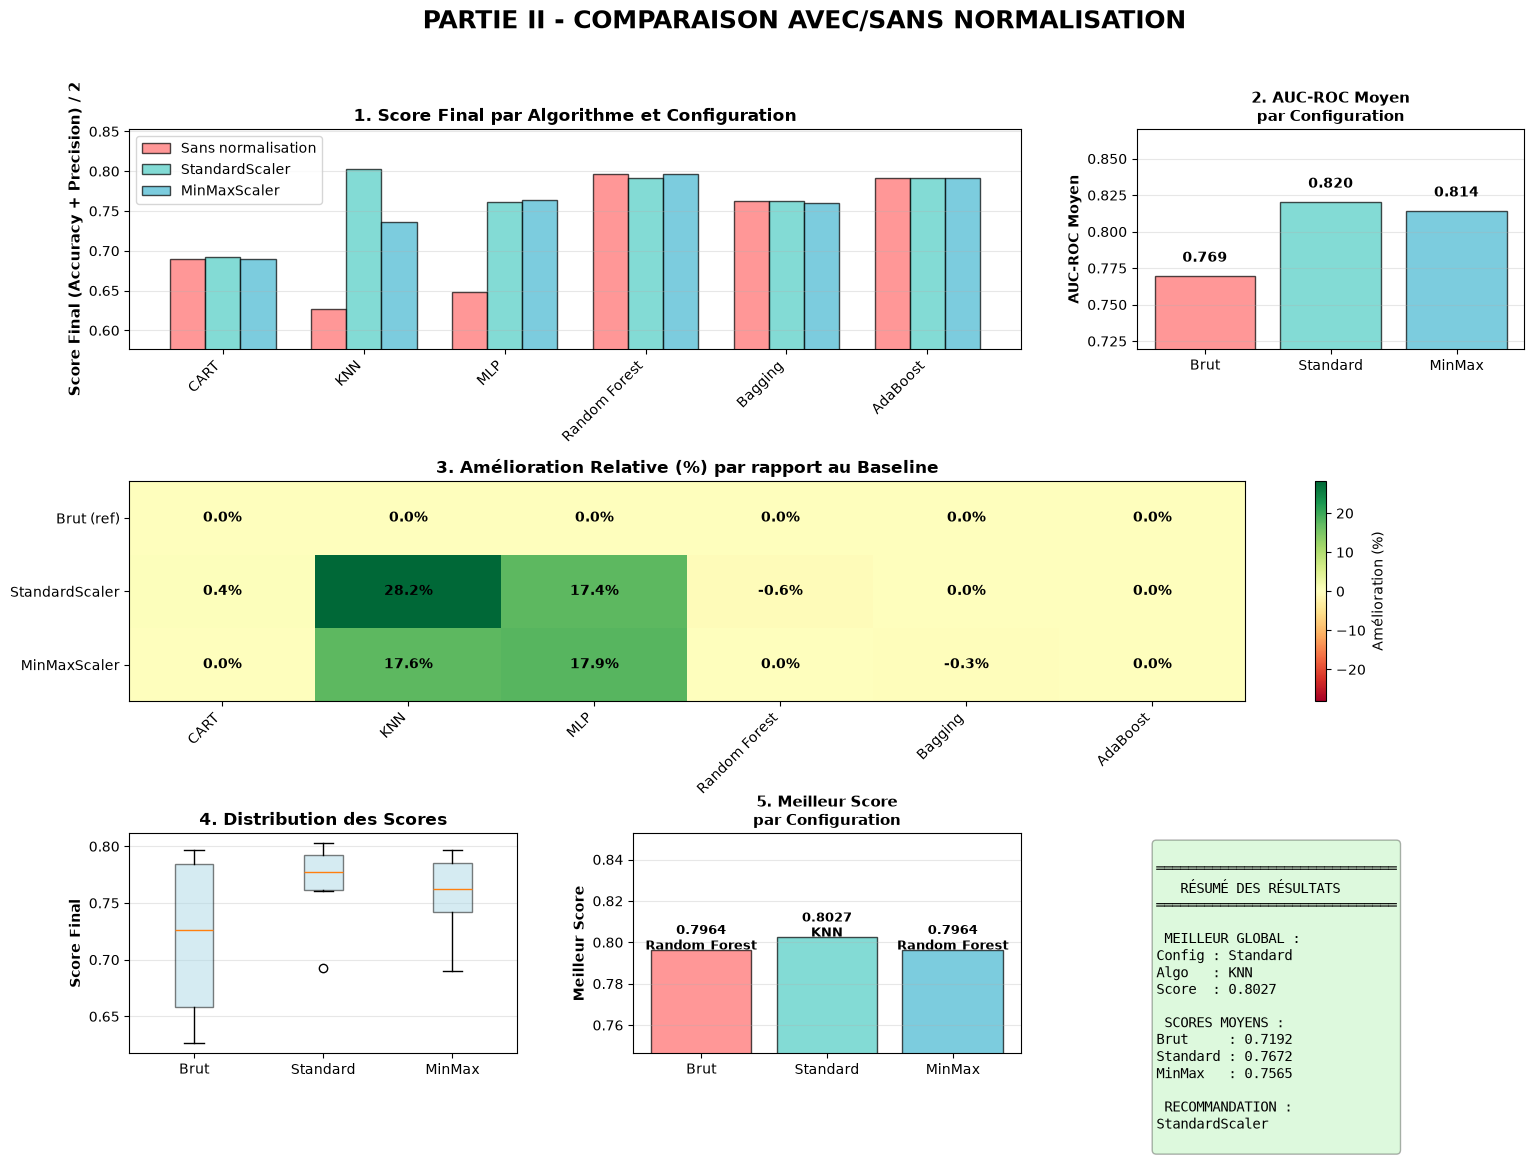


 Graphiques affichés


In [35]:
# ==============================================================================
# 6. VISUALISATION COMPARATIVE COMPLÈTE
# ==============================================================================

print("\n\n" + "="*80)
print("VISUALISATION COMPARATIVE".center(80))
print("="*80)

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.6, wspace=0.3)

fig.suptitle('PARTIE II - COMPARAISON AVEC/SANS NORMALISATION',
             fontsize=18, fontweight='bold')

# GRAPHIQUE 1 : Score Final par Config et Algo
ax1 = fig.add_subplot(gs[0, :2])

algos_short = [algo.split('(')[0].strip() for algo in classifiers_credit.keys()]
x = np.arange(len(algos_short))
width = 0.25

scores_brut = [results_baseline[results_baseline['Algorithme'] == algo].iloc[0]['Score_Final']
               for algo in classifiers_credit.keys()]
scores_std = [results_standard_credit[results_standard_credit['Algorithme'] == algo].iloc[0]['Score_Final']
              for algo in classifiers_credit.keys()]
scores_mm = [results_minmax_credit[results_minmax_credit['Algorithme'] == algo].iloc[0]['Score_Final']
             for algo in classifiers_credit.keys()]

ax1.bar(x - width, scores_brut, width, label='Sans normalisation', color='#FF6B6B', alpha=0.7, edgecolor='black')
ax1.bar(x, scores_std, width, label='StandardScaler', color='#4ECDC4', alpha=0.7, edgecolor='black')
ax1.bar(x + width, scores_mm, width, label='MinMaxScaler', color='#45B7D1', alpha=0.7, edgecolor='black')

ax1.set_ylabel(f'Score Final {LABEL_SCORE}', fontweight='bold', fontsize=11)
ax1.set_title('1. Score Final par Algorithme et Configuration', fontweight='bold', fontsize=12)
ax1.set_xticks(x)
ax1.set_xticklabels(algos_short, rotation=45, ha='right', fontsize=10)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)
valeurs_q1 = scores_brut + scores_std + scores_mm
ax1.set_ylim([max(0, min(valeurs_q1) - 0.05), min(1, max(valeurs_q1) + 0.05)])

# GRAPHIQUE 2 : AUC-ROC par Config et Algo
ax2 = fig.add_subplot(gs[0, 2])

auc_mean = {
    'Brut': results_baseline['AUC-ROC'].mean(),
    'Standard': results_standard_credit['AUC-ROC'].mean(),
    'MinMax': results_minmax_credit['AUC-ROC'].mean()
}

configs_short = list(auc_mean.keys())
auc_values = list(auc_mean.values())
colors_auc = ['#FF6B6B', '#4ECDC4', '#45B7D1']

bars = ax2.bar(configs_short, auc_values, color=colors_auc, alpha=0.7, edgecolor='black')
ax2.set_ylabel('AUC-ROC Moyen', fontweight='bold')
ax2.set_title('2. AUC-ROC Moyen\npar Configuration', fontweight='bold', fontsize=11)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim([max(0, min(auc_values) - 0.05), min(1, max(auc_values) + 0.05)])

for bar, val in zip(bars, auc_values):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01,
             f'{val:.3f}', ha='center', fontweight='bold', fontsize=10)

# GRAPHIQUE 3 : Amélioration relative (heatmap)
ax3 = fig.add_subplot(gs[1, :])

improvements = []
for algo in classifiers_credit.keys():
    baseline_score = results_baseline[results_baseline['Algorithme'] == algo].iloc[0]['Score_Final']
    std_score = results_standard_credit[results_standard_credit['Algorithme'] == algo].iloc[0]['Score_Final']
    mm_score = results_minmax_credit[results_minmax_credit['Algorithme'] == algo].iloc[0]['Score_Final']

    imp_std = ((std_score - baseline_score) / baseline_score) * 100
    imp_mm = ((mm_score - baseline_score) / baseline_score) * 100

    improvements.append([0, imp_std, imp_mm])  # Baseline = 0%

improvements = np.array(improvements)

lim = max(5, np.abs(improvements).max())
im = ax3.imshow(improvements.T, cmap='RdYlGn', aspect='auto', vmin=-lim, vmax=lim)

ax3.set_xticks(np.arange(len(algos_short)))
ax3.set_yticks(np.arange(3))
ax3.set_xticklabels(algos_short, rotation=45, ha='right', fontsize=10)
ax3.set_yticklabels(['Brut (ref)', 'StandardScaler', 'MinMaxScaler'], fontsize=10)
ax3.set_title('3. Amélioration Relative (%) par rapport au Baseline', fontweight='bold', fontsize=12)

# Ajouter les valeurs dans chaque cellule
for i in range(3):
    for j in range(len(algos_short)):
        text = ax3.text(j, i, f'{improvements[j, i]:.1f}%',
                       ha="center", va="center", color="black", fontweight='bold')

plt.colorbar(im, ax=ax3, label='Amélioration (%)')

# GRAPHIQUE 4 : Distribution des scores
ax4 = fig.add_subplot(gs[2, 0])

ax4.boxplot([scores_brut, scores_std, scores_mm],
            patch_artist=True,
            boxprops=dict(facecolor='lightblue', alpha=0.5))
ax4.set_xticks([1, 2, 3])
ax4.set_xticklabels(['Brut', 'Standard', 'MinMax'])

ax4.set_ylabel('Score Final', fontweight='bold')
ax4.set_title('4. Distribution des Scores', fontweight='bold')
ax4.grid(axis='y', alpha=0.3)

# GRAPHIQUE 5 : Meilleurs par config
ax5 = fig.add_subplot(gs[2, 1])

best_scores = [
    results_baseline.iloc[0]['Score_Final'],
    results_standard_credit.iloc[0]['Score_Final'],
    results_minmax_credit.iloc[0]['Score_Final']
]

best_algos = [
    results_baseline.iloc[0]['Algorithme'].split('(')[0].strip(),
    results_standard_credit.iloc[0]['Algorithme'].split('(')[0].strip(),
    results_minmax_credit.iloc[0]['Algorithme'].split('(')[0].strip()
]

bars5 = ax5.bar(configs_short, best_scores, color=colors_auc, alpha=0.7, edgecolor='black')
ax5.set_ylabel('Meilleur Score', fontweight='bold')
ax5.set_title('5. Meilleur Score\npar Configuration', fontweight='bold', fontsize=11)
ax5.grid(axis='y', alpha=0.3)

# CORRECTION : Ajuster les limites dynamiquement
min_score = min(best_scores)
max_score = max(best_scores)
margin = (max_score - min_score) * 0.2  # Marge de 20%

# Si les scores sont tres proches, forcer une plage visible
if max_score - min_score < 0.05:
    ax5.set_ylim([min_score - 0.05, max_score + 0.05])
else:
    ax5.set_ylim([min_score - margin, max_score + margin])

# Ajouter les valeurs et noms des algos
for bar, score, algo in zip(bars5, best_scores, best_algos):
    height = bar.get_height()
    ax5.text(bar.get_x() + bar.get_width()/2, height + (max_score - min_score) * 0.02,
             f'{score:.4f}\n{algo}', ha='center', fontweight='bold', fontsize=9)


# GRAPHIQUE 6 : Résumé textuel
ax6 = fig.add_subplot(gs[2, 2])
ax6.axis('off')

# Trouver le meilleur global
all_scores_flat = scores_brut + scores_std + scores_mm
all_configs_flat = ['Brut']*len(scores_brut) + ['Standard']*len(scores_std) + ['MinMax']*len(scores_mm)
all_algos_flat = list(classifiers_credit.keys()) * 3

best_idx = np.argmax(all_scores_flat)
best_score_global = all_scores_flat[best_idx]
best_config_global = all_configs_flat[best_idx]
best_algo_global = all_algos_flat[best_idx]

summary_text = f"""
══════════════════════════════
   RÉSUMÉ DES RÉSULTATS
══════════════════════════════

 MEILLEUR GLOBAL :
Config : {best_config_global}
Algo   : {best_algo_global.split('(')[0].strip()}
Score  : {best_score_global:.4f}

 SCORES MOYENS :
Brut     : {mean_scores['Sans normalisation']:.4f}
Standard : {mean_scores['StandardScaler']:.4f}
MinMax   : {mean_scores['MinMaxScaler']:.4f}

 RECOMMANDATION :
{best_config_name}
"""

ax6.text(0.05, 0.95, summary_text, transform=ax6.transAxes,
        fontsize=10, verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.3))

plt.tight_layout()
plt.show()

print("\n Graphiques affichés")

In [36]:
# ==============================================================================
# 7. CONCLUSION SUR LA NORMALISATION
# ==============================================================================

print("\n\n" + "="*80)
print("CONCLUSION SUR LA NORMALISATION".center(80))
print("="*80)

print("\n SYNTHESE DES RESULTATS :")
print("-" * 80)

# Tableau resume
synthese_data = {
    'Configuration': ['Sans normalisation', 'StandardScaler', 'MinMaxScaler'],
    'Score Moyen': [
        results_baseline['Score_Final'].mean(),
        results_standard_credit['Score_Final'].mean(),
        results_minmax_credit['Score_Final'].mean()
    ],
    'Meilleur Score': [
        results_baseline['Score_Final'].max(),
        results_standard_credit['Score_Final'].max(),
        results_minmax_credit['Score_Final'].max()
    ],
    'Meilleur Algo': [
        results_baseline.iloc[0]['Algorithme'].split('(')[0].strip(),
        results_standard_credit.iloc[0]['Algorithme'].split('(')[0].strip(),
        results_minmax_credit.iloc[0]['Algorithme'].split('(')[0].strip()
    ]
}

df_synthese = pd.DataFrame(synthese_data)
print(df_synthese.to_string(index=False))

print("\n\n RECOMMANDATION FINALE :")
print("-" * 80)

if best_config_name == 'Sans normalisation':
    print("\n Pour ce dataset de credit scoring :")
    print("  -> La normalisation N'APPORTE PAS d'amelioration")
    print("  -> Utiliser les donnees BRUTES")
    print(f"  -> Meilleur algorithme : {results_baseline.iloc[0]['Algorithme'].split('(')[0].strip()}")
    print(f"  -> Score Final : {results_baseline.iloc[0]['Score_Final']:.4f}")
elif best_config_name == 'StandardScaler':
    print("\n Pour ce dataset de credit scoring :")
    print("  -> StandardScaler AMELIORE les performances")
    print("  -> Utiliser StandardScaler (centre a 0, ecart-type = 1)")
    print(f"  -> Meilleur algorithme : {results_standard_credit.iloc[0]['Algorithme'].split('(')[0].strip()}")
    print(f"  -> Score Final : {results_standard_credit.iloc[0]['Score_Final']:.4f}")
else:
    print("\n Pour ce dataset de credit scoring :")
    print("  -> MinMaxScaler AMELIORE les performances")
    print("  -> Utiliser MinMaxScaler (valeurs entre 0 et 1)")
    print(f"  -> Meilleur algorithme : {results_minmax_credit.iloc[0]['Algorithme'].split('(')[0].strip()}")
    print(f"  -> Score Final : {results_minmax_credit.iloc[0]['Score_Final']:.4f}")

print("\n" + "="*80)
print("FIN DE LA QUESTION 1 (Normalisation)".center(80))
print("="*80 + "\n")



                        CONCLUSION SUR LA NORMALISATION                         

 SYNTHESE DES RESULTATS :
--------------------------------------------------------------------------------
     Configuration  Score Moyen  Meilleur Score Meilleur Algo
Sans normalisation     0.719240        0.796396 Random Forest
    StandardScaler     0.767160        0.802682           KNN
      MinMaxScaler     0.756536        0.796396 Random Forest


 RECOMMANDATION FINALE :
--------------------------------------------------------------------------------

 Pour ce dataset de credit scoring :
  -> StandardScaler AMELIORE les performances
  -> Utiliser StandardScaler (centre a 0, ecart-type = 1)
  -> Meilleur algorithme : KNN
  -> Score Final : 0.8027

                      FIN DE LA QUESTION 1 (Normalisation)                      



### Q2. Toutes les variables (numériques + catégorielles)

Les 15 variables sont utilisées : imputation par la moyenne et normalisation des variables
numériques, modalité `MISSING` puis encodage one-hot des variables catégorielles.
Le découpage train / test est fait **avant** le prétraitement, appris sur le train uniquement.

In [37]:
# ==============================================================================
# PARTIE II - QUESTION 2 : DONNEES COMPLETES (15 VARIABLES)
# ==============================================================================

print("\n\n" + "="*80)
print("PARTIE II - QUESTION 2 : DONNEES COMPLETES (15 VARIABLES)".center(80))
print("="*80)

print("\n OBJECTIF :")
print("   Maintenant on utilise TOUTES les 15 variables :")
print("   - 6 variables numeriques")
print("   - 9 variables categorielles")
print("   - Traiter les donnees manquantes")
print("   - Encoder les variables categorielles")

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split

# ==============================================================================
# ETAPE 1 : RECHARGEMENT DONNÉES COMPLÈTES
# ==============================================================================

print("\n" + "-"*80)
print("ETAPE 1 : RECHARGEMENT DES DONNEES ORIGINALES (15 VAR)".center(80))
print("-"*80)

# Meme fichier que la Q1 : credit.data (tabulations, '?' = valeur manquante)
column_names = [f'V{i}' for i in range(1, 16)] + ['target']

df_full = pd.read_csv(DATA_DIR / 'credit.data', sep='\t', header=None,
                      names=column_names, na_values='?')

print(f"\n Dataset charge : {df_full.shape[0]} individus, {df_full.shape[1]} colonnes")

# Identifier colonnes
col_num = [1, 2, 7, 10, 13, 14]  # Variables numeriques (indices 0-based)
col_cat = [0, 3, 4, 5, 6, 8, 9, 11, 12]  # Variables categorielles
num_cols = [column_names[i] for i in col_num]
cat_cols = [column_names[i] for i in col_cat]

print(f"\n Variables numeriques : {len(col_num)} colonnes ({', '.join(num_cols)})")
print(f" Variables categorielles : {len(col_cat)} colonnes ({', '.join(cat_cols)})")

# Analyser donnees manquantes
print("\n ANALYSE DES DONNEES MANQUANTES :")
print("-" * 60)

missing_counts = df_full.isnull().sum()
missing_data = {
    'Colonne': missing_counts.index,
    'Nb_manquants': missing_counts.values,
    'Pourcentage': (missing_counts.values / len(df_full) * 100).round(2)
}
df_missing = pd.DataFrame(missing_data)
df_missing = df_missing[df_missing['Nb_manquants'] > 0]

if len(df_missing) > 0:
    print(df_missing.to_string(index=False))
    print(f"\n Total : {missing_counts.sum()} valeurs manquantes")
else:
    print(" Aucune donnee manquante")

# ==============================================================================
# ETAPE 2 : TRAIN/TEST SPLIT (AVANT LE PRETRAITEMENT)
# ==============================================================================
# Imputation, encodage et normalisation sont appris sur le train uniquement

print("\n\n" + "-"*80)
print("ETAPE 2 : TRAIN/TEST SPLIT (AVANT LE PRETRAITEMENT)".center(80))
print("-"*80)

X_full_df = df_full[cat_cols + num_cols].copy()

# Categorielles : une valeur manquante devient la modalite 'MISSING'
# (remplacement par une constante : rien n'est appris sur les donnees)
nan_count_cat = int(X_full_df[cat_cols].isna().sum().sum())
X_full_df[cat_cols] = X_full_df[cat_cols].fillna('MISSING')

# Binariser target
y_complete = (df_full['target'] == '+').astype(int).to_numpy()

X_train_df, X_test_df, y_train_complete, y_test_complete = train_test_split(
    X_full_df, y_complete, test_size=0.5, random_state=1, stratify=y_complete
)

print(f"\n Train : {X_train_df.shape[0]} individus")
print(f" Test  : {X_test_df.shape[0]} individus")

print(f"\n Target binarisee :")
print(f"   Classe 0 : {(y_complete == 0).sum()}")
print(f"   Classe 1 : {(y_complete == 1).sum()}")

# ==============================================================================
# ETAPE 3 : PRETRAITEMENT (APPRIS SUR LE TRAIN)
# ==============================================================================

print("\n\n" + "-"*80)
print("ETAPE 3 : TRAITEMENT DES VARIABLES".center(80))
print("-"*80)

preprocessor_full = ColumnTransformer([
    # Categorielles -> OneHot (variables binaires)
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
    # Numeriques -> imputation par la moyenne puis normalisation
    ('num', Pipeline([('imputer', SimpleImputer(strategy='mean')),
                      ('scaler', StandardScaler())]), num_cols),
])

X_train_complete = preprocessor_full.fit_transform(X_train_df)
X_test_complete = preprocessor_full.transform(X_test_df)

nan_count_num = int(df_full[num_cols].isna().sum().sum())
print(f"\n 3.1 - Variables numeriques :")
print(f"   {nan_count_num} valeurs manquantes imputees par la moyenne (calculee sur le train)")
print(f"   Normalisation StandardScaler (moyenne et ecart-type du train)")

print(f"\n 3.2 - Variables categorielles :")
print(f"   {nan_count_cat} valeurs manquantes remplacees par 'MISSING'")

ohe = preprocessor_full.named_transformers_['cat']

print("\n Detail des variables encodees (OneHot) :")
start_idx = 0
for col_name, categories in zip(cat_cols, ohe.categories_):
    n_categories = len(categories)
    print(f"   {col_name:5s} : {n_categories:2d} modalites -> colonnes {start_idx} a {start_idx + n_categories - 1}")
    start_idx += n_categories

n_onehot = start_idx

# ==============================================================================
# ETAPE 4 : CONSTRUCTION JEU DE DONNÉES FINAL
# ==============================================================================

print("\n\n" + "-"*80)
print("ETAPE 4 : CONSTRUCTION JEU DE DONNEES FINAL".center(80))
print("-"*80)

print(f"\n Shape finale : train {X_train_complete.shape}, test {X_test_complete.shape}")
print(f"   Variables categorielles (OneHot) : {n_onehot}")
print(f"   Variables numeriques : {len(num_cols)}")
print(f"   Total features : {X_train_complete.shape[1]}")

# ==============================================================================
# ETAPE 5 : COMPARAISON ALGORITHMES (15 VARIABLES)
# ==============================================================================

print("\n\n" + "-"*80)
print("ETAPE 5 : COMPARAISON ALGORITHMES (15 VARIABLES)".center(80))
print("-"*80)

results_complete = run_classifiers_with_auc(
    classifiers_credit,
    X_train_complete, y_train_complete,
    X_test_complete, y_test_complete,
    verbose=True
)

results_complete['Configuration'] = '15 variables completes'

# ==============================================================================
# ETAPE 6 : COMPARAISON 6 VAR vs 15 VAR
# ==============================================================================
# Reference 6 variables : la meilleure configuration de la Q1 (best_config_name).
# Les variables numeriques etant normalisees ici, on mesure bien l'apport des
# variables categorielles et non celui de la normalisation.

print("\n\n" + "="*80)
print("COMPARAISON FINALE : 6 VARIABLES vs 15 VARIABLES".center(80))
print("="*80)

results_6var = {
    'Sans normalisation': results_baseline,
    'StandardScaler': results_standard_credit,
    'MinMaxScaler': results_minmax_credit,
}[best_config_name]

comparison_final = {
    'Configuration': [f'6 var numeriques ({best_config_name})', '15 var completes'],
    'Nb_features': [X_train_credit.shape[1], X_train_complete.shape[1]],
    'Nb_individus': [X_train_credit.shape[0], X_train_complete.shape[0]],
    'Meilleur_Score': [
        results_6var['Score_Final'].max(),
        results_complete['Score_Final'].max()
    ],
    'Meilleur_Algo': [
        results_6var.iloc[0]['Algorithme'].split('(')[0].strip(),
        results_complete.iloc[0]['Algorithme'].split('(')[0].strip()
    ]
}

df_comparison_final = pd.DataFrame(comparison_final)
print("\n TABLEAU COMPARATIF :")
print(df_comparison_final.to_string(index=False))

# Comparaison par algo
print("\n\n COMPARAISON PAR ALGORITHME :")
print("-" * 80)

for algo in classifiers_credit.keys():
    score_6 = results_6var[results_6var['Algorithme'] == algo].iloc[0]['Score_Final']
    score_15 = results_complete[results_complete['Algorithme'] == algo].iloc[0]['Score_Final']
    improvement = ((score_15 - score_6) / score_6) * 100

    print(f"\n {algo.split('(')[0].strip()} :")
    print(f"   6 var  : {score_6:.4f}")
    print(f"   15 var : {score_15:.4f}")
    print(f"   Diff   : {improvement:+.2f}%")

# ==============================================================================
# CONCLUSION FINALE
# ==============================================================================

print("\n\n" + "="*80)
print("CONCLUSION FINALE - PARTIE II".center(80))
print("="*80)

best_6 = results_6var['Score_Final'].max()
best_15 = results_complete['Score_Final'].max()

print(f"\n Meilleur avec 6 var  : {best_6:.4f} ({results_6var.iloc[0]['Algorithme'].split('(')[0].strip()})")
print(f" Meilleur avec 15 var : {best_15:.4f} ({results_complete.iloc[0]['Algorithme'].split('(')[0].strip()})")

if best_15 > best_6:
    gain = ((best_15 - best_6) / best_6) * 100
    print(f"\n CONCLUSION : 15 variables MEILLEURES (+{gain:.2f}%)")
    print(f" -> Les variables categorielles apportent de l'information utile")
else:
    print(f"\n CONCLUSION : 6 variables SUFFISANTES")
    print(f" -> Les variables categorielles n'ameliorent pas")

print("\n" + "="*80)
print("FIN DE LA PARTIE II".center(80))
print("="*80 + "\n")



           PARTIE II - QUESTION 2 : DONNEES COMPLETES (15 VARIABLES)            

 OBJECTIF :
   Maintenant on utilise TOUTES les 15 variables :
   - 6 variables numeriques
   - 9 variables categorielles
   - Traiter les donnees manquantes
   - Encoder les variables categorielles

--------------------------------------------------------------------------------
             ETAPE 1 : RECHARGEMENT DES DONNEES ORIGINALES (15 VAR)             
--------------------------------------------------------------------------------

 Dataset charge : 688 individus, 16 colonnes

 Variables numeriques : 6 colonnes (V2, V3, V8, V11, V14, V15)
 Variables categorielles : 9 colonnes (V1, V4, V5, V6, V7, V9, V10, V12, V13)

 ANALYSE DES DONNEES MANQUANTES :
------------------------------------------------------------
Colonne  Nb_manquants  Pourcentage
     V1            12         1.74
     V2            12         1.74
     V4             5         0.73
     V5             5         0.73
     V6       

   ✓ Acc: 0.8081 | Rec: 0.7451 | Prec: 0.8085 | AUC: 0.8815

[4/6] Random Forest (100)...
   ✓ Acc: 0.8750 | Rec: 0.8301 | Prec: 0.8819 | AUC: 0.9114

[5/6] Bagging (100)...


   ✓ Acc: 0.8721 | Rec: 0.8366 | Prec: 0.8707 | AUC: 0.9228

[6/6] AdaBoost (100)...


   ✓ Acc: 0.8459 | Rec: 0.7712 | Prec: 0.8676 | AUC: 0.9147


                               TABLEAU COMPARATIF                               

          Algorithme  Accuracy   Recall  Precision  F1-Score  AUC-ROC  Score_Final  Rang
 Random Forest (100)  0.875000 0.830065   0.881944  0.855219 0.911354     0.878472     1
       Bagging (100)  0.872093 0.836601   0.870748  0.853333 0.922783     0.871421     2
      AdaBoost (100)  0.845930 0.771242   0.867647  0.816609 0.914708     0.856789     3
           KNN (k=5)  0.834302 0.738562   0.869231  0.798587 0.885091     0.851767     4
CART (Decision Tree)  0.845930 0.803922   0.842466  0.822742 0.841751     0.844198     5
         MLP (40,20)  0.808140 0.745098   0.808511  0.775510 0.881497     0.808325     6

 CLASSEMENT :

1 Rang 1 : Random Forest (100)
   • Score Final : 0.8785
   • AUC-ROC     : 0.9114

2 Rang 2 : Bagging (100)
   • Score Final : 0.8714
   • AUC-ROC     : 0.9228

3 Rang 3 : AdaBoost (100)
   • Score Final : 0.8568
   